# 3-servo: steps

Step the free servo's duty up and back by 2, 5 and 10 % at three operating points, and reverse it at three duties, so the current's and the speed's responses to a duty step, their delays and the backlash's crossing are read on mg90-d. These are the plant stage 5 designs its current and velocity loops on.

## Purpose

A brushed DC motor answers a duty step twice. The winding's current changes first, on the electrical time scale. The rotor's speed follows on the mechanical one, and as it rises its back-EMF (electromotive force) takes most of the current change back. With $V$ the applied volts, $I$ the current, $\omega$ ("omega") the rotor's speed, $R$ the terminal resistance, $L$ the winding's inductance and $K_e$ ("K e") the back-EMF constant,

$$V = R\,I + L\,\frac{dI}{dt} + K_e\,\omega, \qquad J\,\frac{d\omega}{dt} = K_t\,I - \text{drag},$$

with $J$ the rotor's inertia and $K_t$ ("K t") the torque constant, equal to $K_e$ in SI units. A small step $\Delta V$ ("delta V") raises the current with the electrical time constant $\tau_e = L/R$ ("tau e") toward a plateau of $\Delta V/R$. The speed then rises with the mechanical time constant $\tau_m$ ("tau m"), near $J R / (K_e K_t)$, toward $\Delta\omega = \Delta V / K_e$ less what the drag takes, and the current falls back from its plateau as it does. On this motor the two time constants differ by a factor of about a hundred, so the two responses are read one at a time.

Stage 5 designs the current loop on the first response and the velocity loop on the second. Each loop needs the plant's gain, its time constant and any delay between the command and the response, in the units the firmware works in, duty in percent in, crest current in mA and motor speed in rev/s out.

The stage README sets these targets.

- The current's and the speed's response to duty steps at several sizes and operating points.
- The delay from the command's edge.
- The reversals, for the backlash's dynamics.

mg90-d is a new motor from a new servo of the same brand, installed in a new, never used MG90 body whose gears were cleaned and regreased by hand with Super Lube. Its motor is not opened, so every number here is read through the servo's two motor leads and its pot. The type values come from stage 2's mg90-b and serve as comparisons, except the type's rotor inertia in one route to the backlash, said where it enters.

## Procedure

The servo is mg90-d on board dev-v006-2A-D, horn free, powered from the DPS-150 bench supply at 5 V over the board's feed diode, with the board's adapter on its bus at 3 Mbps. The board runs the experiment image, so every drive is open loop with only the raw current trip and the bus dead-man as protections. The sitting runner, `python -m oscnb.sitting servo`, ran the `capture` and `reversal` plans of `stages/3-servo/steps/plan.py` in sitting 1.

A chain is one `osc-lab sweep`. It opens with a 500 ms torque-off baseline. Then, in each direction, the servo seeks to its start, drives the base duty toward the far guard, steps the duty up by the step size with no release, and steps it back to the base. The three segments ask for 400, 300 and 300 ms, and the runner cuts all three by one factor so the chain ends short of the far guard.

- `capture-1` is 27 chains, bases of 20, 30 and 40 %, steps of 2, 5 and 10 %, from three starts, the guards and the guards moved in by a sixth and by a third of the travel. Each chain drives direction +1, then -1.
- `reversal-1` is 3 chains at 10, 20 and 30 %. Each drives the duty for 300 ms, then its negative for 300 ms with no release, first starting in direction +1 and then starting in -1.

Every drive stays inside the motor's rated 5 V as rail times duty.

## Data

Everything is under `telemetry/mg90-d__dev-v006-2A-D/`. The two datasets are `steps/capture-1` and `steps/reversal-1`, and sitting 1's manifest is `sittings/servo-1.csv`.

The libraries, then the pair and its folders.

In [1]:
import warnings
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import least_squares

from oscnb import boards, figures, motors, results, ripple, scales
from oscnb import servos, tel
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE, RED

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo: pot, train, rated V
MOTOR = motors.MOTORS["mg90-d"]         # its motor, with its counted parts
BOARD_KEY = "dev-v006-2A-D"             # the board, checked on every sweep
PAIR = f"{SERVO.key}__{BOARD_KEY}"      # the pair, the result file's name
PAIR_DIR = (Path("../../../telemetry") / PAIR).resolve()
CAPTURE = PAIR_DIR / "steps" / "capture-1"     # the 27 step chains
REVERSAL = PAIR_DIR / "steps" / "reversal-1"   # the 3 reversal chains
MANIFEST = PAIR_DIR / "sittings" / "servo-1.csv"   # sitting 1's log
FS = 20_000                             # rows per second, the control tick
ROW_US = 1e6 / FS                       # us per row, 50
print(SERVO.key, "on", BOARD_KEY, "from", results.rel(CAPTURE), "and",
      results.rel(REVERSAL))
print(f"{MOTOR.label}: {MOTOR.slots} slots, {MOTOR.brushes} brushes, "
      f"{MOTOR.ripple_per_rev} ripple events per rev, rows at {FS} Hz")

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D/steps/capture-1 and telemetry/mg90-d__dev-v006-2A-D/steps/reversal-1
the motor of MG90 clone d: 3 slots, 2 brushes, 6 ripple events per rev, rows at 20000 Hz


Every sweep names its board in its own `meta.json`. The board is looked up from that sense block, never assumed, and its check raises if any constant disagrees with the registry.

In [3]:
def board_of(meta, where=""):
    # the board a sweep's meta names, its sense block checked
    board = boards.from_meta(meta)      # identified from the data itself
    if board is None:
        raise ValueError(f"{where}: no board matches {meta['sense']}")
    board.check_meta(meta, where)       # raises on any mismatch
    return board


def load(folder):
    # (frame, meta, board) of one sweep, through the chain
    frame, meta = tel.load(folder)
    return frame, meta, board_of(meta, str(results.rel(folder)))

### Stage 1 values carried in

The current goes through the current-scale result and the terminal volts through the terminal-chain result, both graded on this board in stage 1. Bridge-states gives the low-side loop's resistance, which carries the current while the bridge brakes between its on-windows. Sample-timing gives the lag of the taps' ON and OFF edges behind the commanded window, here the mean of its two graded rails, since every drive in this notebook is on 5 V, between them.

In [4]:
SCALES = scales.load(BOARD_KEY)         # stage 1's current and volt lines
# multiplied as the stage 2 files were computed, never divided: a ripple
# count downstream turns a last-bit change into a moved result
A_PER_COUNT = SCALES.a_per_count        # amps per count over the zero
V_PER_COUNT = SCALES.v_per_count        # volts per count of tap difference
TAP_OFFSET = SCALES.terminal_offset_counts   # the tap difference's offset
I_DRIVE_OFFSET = SCALES.drive_offset_counts  # the in-drive current offset
BRIDGE = results.read("1-board", "bridge-states", pair=BOARD_KEY)
R_BRK = BRIDGE["low_side_loop_ohm"]["value"]   # ohm, the brake's loop
LAGS = SCALES.edge_lags()               # ticks, mean of the graded rails
EDGE_TICKS = LAGS["tap_on"] - LAGS["off"]      # the ON window's shortfall
SCALES.describe()
print(f"a count over the zero is {A_PER_COUNT * 1e3:.3f} mA, a count of tap "
      f"difference {V_PER_COUNT * 1e3:.3f} mV, in-drive offset "
      f"{I_DRIVE_OFFSET:.2f} counts")
print(f"low-side loop {R_BRK:.4f} ohm; ON tap lag less OFF lag "
      f"{EDGE_TICKS:.1f} ticks of the 2400 tick period")

current: counts over the zero = +5.3 + 1135.0 x amps (1133.8 to 1136.3), graded over 0.23 to 1.31 A
terminals: tap difference = +2.4 + 248.37 x volts (248.20 to 248.53)
rail: tap = +6.0 + 247.54 x volts at rest
bridge ON edge 40 ticks after the commanded start, shunt crossing 44, OFF edge 14 after the commanded end, shunt settled 72 after the start
fast decay: ON edge 8 ticks after the commanded start, OFF edge 12 after the end
a count over the zero is 0.881 mA, a count of tap difference 4.026 mV, in-drive offset 5.26 counts
low-side loop 0.3008 ohm; ON tap lag less OFF lag 25.5 ticks of the 2400 tick period


### Stage 3 values carried in

The resistance notebook's locked 100 % laps give $R$, 4.219 ohm, the number every EMF balance here uses. Its stop chains, read under construction A and under the board terms, are quoted beside it. The inductance notebook gives $L$ and $\tau_e$ from locked bursts, and its in-window ripple $L$. The ladder notebook gives $K_e$ from 108 natural coasts, the number every speed from volts uses here, and the sustaining floor. The sag notebook's $K_e$ is quoted beside it.

In [5]:
RES = results.read("3-servo", "resistance", pair=PAIR)
IND = results.read("3-servo", "inductance", pair=PAIR)
LADDER = results.read("3-servo", "ladder", pair=PAIR)
SAG = results.read("3-servo", "sag", pair=PAIR)
R_LOCKED = RES["r_term_ohm"]["value"]   # ohm, the locked 100 % laps
R_LOCKED_LO, R_LOCKED_HI = RES["r_term_ohm"]["lo"], RES["r_term_ohm"]["hi"]
R_STOP_A = RES["r_stop_ohm"]["value"]   # ohm, the stop chains under A
R_STOP_B = RES["r_stop_edge_brake_ohm"]["value"]   # under the board terms
L_MH = IND["l_mh"]["value"]             # mH, the locked bursts
L_MH_LO, L_MH_HI = IND["l_mh"]["lo"], IND["l_mh"]["hi"]
L_WINDOW_MH = IND["l_ripple_mh"]["value"]   # mH, the in-window ripple L
TAU_E_US = IND["tau_us"]["value"]       # us, the bursts' L/R
TAU_E_LO, TAU_E_HI = IND["tau_us"]["lo"], IND["tau_us"]["hi"]
KE_LADDER = LADDER["ke_mv_per_rev_s"]["value"] * 1e-3   # V per rev/s
KE_SAG = SAG["ke_mv_per_rev_s"]["value"] * 1e-3         # V per rev/s
FLOOR_V_EFF = LADDER["floor_v_effective"]["value"]      # V effective
print(f"R locked {R_LOCKED:.4f} ohm ({R_LOCKED_LO:.4f} to "
      f"{R_LOCKED_HI:.4f}); stop chains {R_STOP_A:.3f} (A), "
      f"{R_STOP_B:.3f} (board terms)")
print(f"L {L_MH:.3f} mH ({L_MH_LO:.3f} to {L_MH_HI:.3f}), tau_e "
      f"{TAU_E_US:.0f} us ({TAU_E_LO:.0f} to {TAU_E_HI:.0f}), window L "
      f"{L_WINDOW_MH:.3f} mH")
print(f"Ke {KE_LADDER * 1e3:.3f} mV per rev/s (ladder), "
      f"{KE_SAG * 1e3:.3f} (sag); floor {FLOOR_V_EFF:.3f} V effective")

R locked 4.2189 ohm (4.2065 to 4.2300); stop chains 4.377 (A), 4.265 (board terms)
L 0.820 mH (0.781 to 0.874), tau_e 199 us (186 to 205), window L 0.645 mH
Ke 7.283 mV per rev/s (ladder), 7.327 (sag); floor 0.340 V effective


### Stage 2 type values carried in

mg90-b's speed-torque result gives the type's rotor inertia $J$ and its measured run-up rise, and its inductance result the type's $L$ and $\tau_e$. $J$ enters one route to the backlash, the current route, and nothing else. The rest are comparisons.

In [6]:
TYPE_KEY = SERVO.type_motor             # mg90-b
ST_TYPE = results.read("2-motor", "speed-torque", pair=TYPE_KEY)
IND_TYPE = results.read("2-motor", "inductance", pair=TYPE_KEY)
J_TYPE = ST_TYPE["j_kg_m2"]["value"]    # kg m^2, the type's rotor inertia
J_TYPE_LO, J_TYPE_HI = ST_TYPE["j_kg_m2"]["lo"], ST_TYPE["j_kg_m2"]["hi"]
RISE63_TYPE_MS = ST_TYPE["measured_rise_63_ms"]   # ms, by direction
L_TYPE_MH = IND_TYPE["l_mh"]["value"]   # mH, comparison
TAU_TYPE_US = IND_TYPE["tau_us"]["value"]   # us, comparison
print(f"{TYPE_KEY}: J {J_TYPE:.3e} kg m^2 ({J_TYPE_LO:.3e} to "
      f"{J_TYPE_HI:.3e}), run-up 63 % rise at 100 % on 5 V "
      f"{RISE63_TYPE_MS['+1']['value']:.1f} / "
      f"{RISE63_TYPE_MS['-1']['value']:.1f} ms")
print(f"{TYPE_KEY}: L {L_TYPE_MH:.3f} mH, tau_e {TAU_TYPE_US:.0f} us")

mg90-b: J 6.255e-09 kg m^2 (5.827e-09 to 6.834e-09), run-up 63 % rise at 100 % on 5 V 19.0 / 19.5 ms
mg90-b: L 0.833 mH, tau_e 194 us


The servo's counted parts. The pot's slope is nominal, a sizing number the pot-table notebook grades, so every count turned into motor turns here carries that label.

In [7]:
N_R = MOTOR.ripple_per_rev              # ripple events per motor rev
GEAR = SERVO.gear_ratio                 # counted teeth, motor revs per out
COUNTS_PER_MOTOR_REV = SERVO.counts_per_motor_rev   # nominal pot slope
COUNTS_PER_DEG = SERVO.counts_per_deg_nominal       # nominal, output deg
print(f"{N_R} ripple events per motor rev, gear {GEAR:.2f}:1, pot "
      f"{COUNTS_PER_DEG} counts per degree, so {COUNTS_PER_MOTOR_REV:.2f} "
      f"counts per motor turn (nominal)")

6 ripple events per motor rev, gear 308.05:1, pot 19.8 counts per degree, so 23.14 counts per motor turn (nominal)


The constants of the method, each with its unit and reason. First the speed's.

In [8]:
TRACK_FROM_MS = 15.0    # ms into the run-up from rest, the tach's start
TRACK_CYCLES = 4        # cycles per chunk of the tracked tach
TRACK_FRAC = 0.35       # the tach's band, +/- this share of the line
SPEED_PRE_MS = 25.0     # ms before a flip, the per-edge speed check
SPEED_DELAY_BOUNDS_MS = (0.0, 8.0)  # ms, the delay a speed fit may take
TAU_M_BOUNDS_MS = (2.0, 200.0)      # ms, the time constant's range
SETTLED_MS = 40.0       # ms, a segment's settled window, its last rows
SETTLED_MIN_MS = 8.0    # ms, never shorter, half the segment at most
SETTLE_PCT_MAX = 2.5    # %, a settled level's speed change across it
SETTLED_CYCLES_MIN = 20     # cycles, a settled level's tach at least
POT_BOX_ROWS = 80       # 4 ms, a whole multiple of the pot's 250 Hz comb
I_BOX_ROWS = 40         # 2 ms boxcar on the current for its slow part
I_EXCLUDE_MS = 2.5      # ms either side of a flip the slow fit leaves out

Then the current's. A row is 50 us.

In [9]:
PRE_CYCLES = 4          # ripple cycles the per-edge template is read over
HARMONICS = 4           # the template's Fourier terms in the ripple phase
POST_ROWS = 30          # 1.5 ms after a flip, about 7 electrical tau
TAU_BOUNDS_ROWS = (0.5, 30.0)   # rows, the electrical tau's range
T0_BOUNDS_ROWS = (-4.0, 12.0)   # rows, where the exponential may start
ALIGN_PRE = 60          # rows before the flip kept for the ensemble
ALIGN_POST = 500        # rows after it, 25 ms, the current's slow fall
FIT_PRE = 40            # rows before the flip the ensemble fit reads
FIT_POST = 40           # rows after it, 2 ms
MECH_FROM = 15          # rows after the flip the slow fit starts
DECLINE_ROWS = 400      # rows, a mechanical tau for the decline variant
TAU2_BOUNDS = (8.0, 300.0)      # rows, the second exponential's range
BOOT = 200              # bootstrap resamples over the edges
RNG = np.random.default_rng(3)  # seeded, so the bounds repeat run to run

Then the take-up's and the reversals'.

In [10]:
POT_STILL_COUNTS = 2.5  # counts, the pot has moved once past this
POT_STILL_BOX = 20      # rows, 1 ms smoothing before that call
DIP_COUNTS = 6          # counts, a commutation dip's least depth
I_DRAG_A = 0.03         # A, the free rotor's drag, the current route's
                        # bracket at a few tens of rev/s
LOOK_MS = 120.0         # ms after a reversal's flip the reads look at

### chains.csv

One row per chain of `capture-1`. `k` is the chain number, `volts_set` the rail, `start_share` how far the guards were moved in, as a share of the travel, `guard_lo` and `guard_hi` the guards in pot counts, `base_pct` and `step_pct` the base duty and the step, `windows_ms` the three windows the runner allowed after its cut, `t_start` and `t_end` the host times, `folder` the chain's folder.

In [11]:
CHAINS = pd.read_csv(CAPTURE / "chains.csv")
REV_CHAINS = pd.read_csv(REVERSAL / "chains.csv")
show(CHAINS, n=4)
def values(col):
    # the distinct values of a column as plain numbers
    return [float(v) for v in sorted(CHAINS[col].unique())]


print(f"capture-1: {len(CHAINS)} chains, bases {values('base_pct')} %, "
      f"steps {values('step_pct')} %, starts {values('start_share')}")
show(REV_CHAINS, n=None)

,k,volts_set,start_share,guard_lo,guard_hi,base_pct,step_pct,windows_ms,t_start,t_end,folder
0,0,5.000,0.000,414,3460,20,2,363/272/272,1793943159.796,1793943223.745,chains/0
1,1,5.000,0.000,414,3460,20,5,342/256/256,1793943243.751,1793943303.831,chains/1
2,2,5.000,0.000,414,3460,20,10,311/233/233,1793943323.843,1793943383.977,chains/2
3,3,5.000,0.000,414,3460,30,2,217/163/163,1793943403.984,1793943463.531,chains/3


capture-1: 27 chains, bases [20.0, 30.0, 40.0] %, steps [2.0, 5.0, 10.0] %, starts [0.0, 0.167, 0.333]


,k,volts_set,duty_pct,window_ms,t_start,t_end,folder
0,0,5.000,10,300,1793945238.052,1793945296.449,chains/0
1,1,5.000,20,300,1793945316.460,1793945374.699,chains/1
2,2,5.000,30,300,1793945394.712,1793945453.209,chains/2


The windows the runner allowed, per base and start. The thing to see is how the runway cuts the faster and the inner chains short.

In [12]:
windows = CHAINS.assign(base_ms=CHAINS["windows_ms"].str.split("/").str[0])
cut = windows.pivot_table(index="base_pct", columns="start_share",
                          values="base_ms", aggfunc=lambda s: "/".join(s))
print("base window (ms) by base duty and start, steps 2/5/10 %:")
print(cut.to_string())

base window (ms) by base duty and start, steps 2/5/10 %:
start_share        0.000        0.167        0.333
base_pct                                          
20           363/342/311  286/268/242  209/194/173
30           217/190/164  167/144/122    117/98/79
40            108/103/95     80/75/68     51/47/41


### The manifest

Before every sweep the runner reads the board's registers with torque off and logs them in the sitting's manifest, `pos`, `ntc_raw` and `vbus_raw`. The chain's telemetry rows carry no `vbus_raw` and no `ntc_raw`, so this probe is the only reading of the rail and the board temperature each chain has. The parser is the ladder notebook's.

In [13]:
def manifest_probes(path, needle):
    # the probe rows of a sitting whose dataset path holds `needle`,
    # parsed to pos, ntc_raw and vbus_raw, keyed by the sweep's folder
    manifest = pd.read_csv(path)
    rows = []
    for _, r in manifest[manifest["event"] == "probe"].iterrows():
        label, _, rest = r["detail"].partition(": ")
        if needle not in label:
            continue                    # another dataset's probe
        got = dict(part.split(" ") for part in rest.split(", "))
        rows.append({"folder": label.split(needle)[1],
                     "t_probe": r["t_host"],
                     **{k: float(v) for k, v in got.items()}})
    return pd.DataFrame(rows)

In [14]:
PROBES = manifest_probes(MANIFEST, "steps/capture-1/")
CHAINS = CHAINS.merge(PROBES, how="left", on="folder")
show(CHAINS[["k", "base_pct", "step_pct", "start_share", "folder", "pos",
             "ntc_raw", "vbus_raw"]], n=4)
rail = SCALES.rail_v(CHAINS["vbus_raw"].to_numpy(float))
print(f"{CHAINS['vbus_raw'].notna().sum()} of {len(CHAINS)} chains carry a "
      f"probe, rail {rail.min():.3f} to {rail.max():.3f} V at rest")

,k,base_pct,step_pct,start_share,folder,pos,ntc_raw,vbus_raw
0,0,20,2,0.000,chains/0,1830.000,1994.000,1243.000
1,1,20,5,0.000,chains/1,2047.000,2011.000,1242.000
2,2,20,10,0.000,chains/2,1993.000,2011.000,1244.000
3,3,30,2,0.000,chains/3,2047.000,2013.000,1238.000


27 of 27 chains carry a probe, rail 4.973 to 5.006 V at rest


### chains/K/sweep.csv and meta.json

Each chain is `sweep.csv`, `meta.json` and `segments.csv`, one row per control tick at 20 kHz. Segment 0 is the half second torque-off baseline. Segments 1, 2 and 3 are the base, the step and the step back in direction +1, and 4, 5 and 6 the same in -1. In a reversal chain segments 1 and 2 are the duty and its negative starting in +1, and 3 and 4 the same starting in -1. `pos` is the pot in counts, `current_raw`, `vmotor_a` and `vmotor_b` ADC counts of the shunt amplifier and the two terminal taps at the crest sample, the conversion near the middle of each PWM on-window, `current_trough` the current sampled in the off-window, `duty_counts` the applied window in timer ticks of a 1200 tick half period, signed by the direction, and `window_valid` whether the window met the sampling floors. One chain, 20 % then 30 % then back, from the guards.

In [15]:
EX_FOLDER = CAPTURE / CHAINS.loc[CHAINS["k"] == 2, "folder"].iloc[0]
EX_DF, EX_META, EX_BOARD = load(EX_FOLDER)
segs = EX_DF["seg"].value_counts().sort_index().to_dict()
print(f"segments {segs}, schedule {EX_META['schedule']}, dirs "
      f"{EX_META['dirs']}, rows dropped {EX_META['rows_dropped']}")
print(f"plant stamp {EX_META['plant']['plant_stamp']} "
      f"({EX_META['plant']['stamp_verdict']}), current limit "
      f"{EX_META['drive']['current_limit_counts']} counts")
show(EX_DF[["seg", "tick", "pos", "current_raw", "current_trough",
            "duty_counts", "vmotor_a", "vmotor_b", "window_valid"]], n=4)

segments {0: 10000, 1: 6220, 2: 4660, 3: 4660, 4: 6220, 5: 4660, 6: 4660}, schedule ['20@311', 'then:30@233', 'then:20@233'], dirs [1, -1], rows dropped 0
plant stamp 0x9c45 (match), current limit 554 counts


,seg,tick,pos,current_raw,current_trough,duty_counts,vmotor_a,vmotor_b,window_valid
0,0,0,1991,1205,1205,0,775,773,0
1,0,1,1985,1205,1205,0,772,771,0
2,0,2,1982,1207,1207,0,771,769,0
3,0,3,1983,1209,1209,0,770,770,0


## Raw traces

The example chain's current, the two taps, the applied window as a percent of the half period and the pot, against the rows. The thing to see is the current's jump at each duty step, riding on a ripple about as large as the jump.

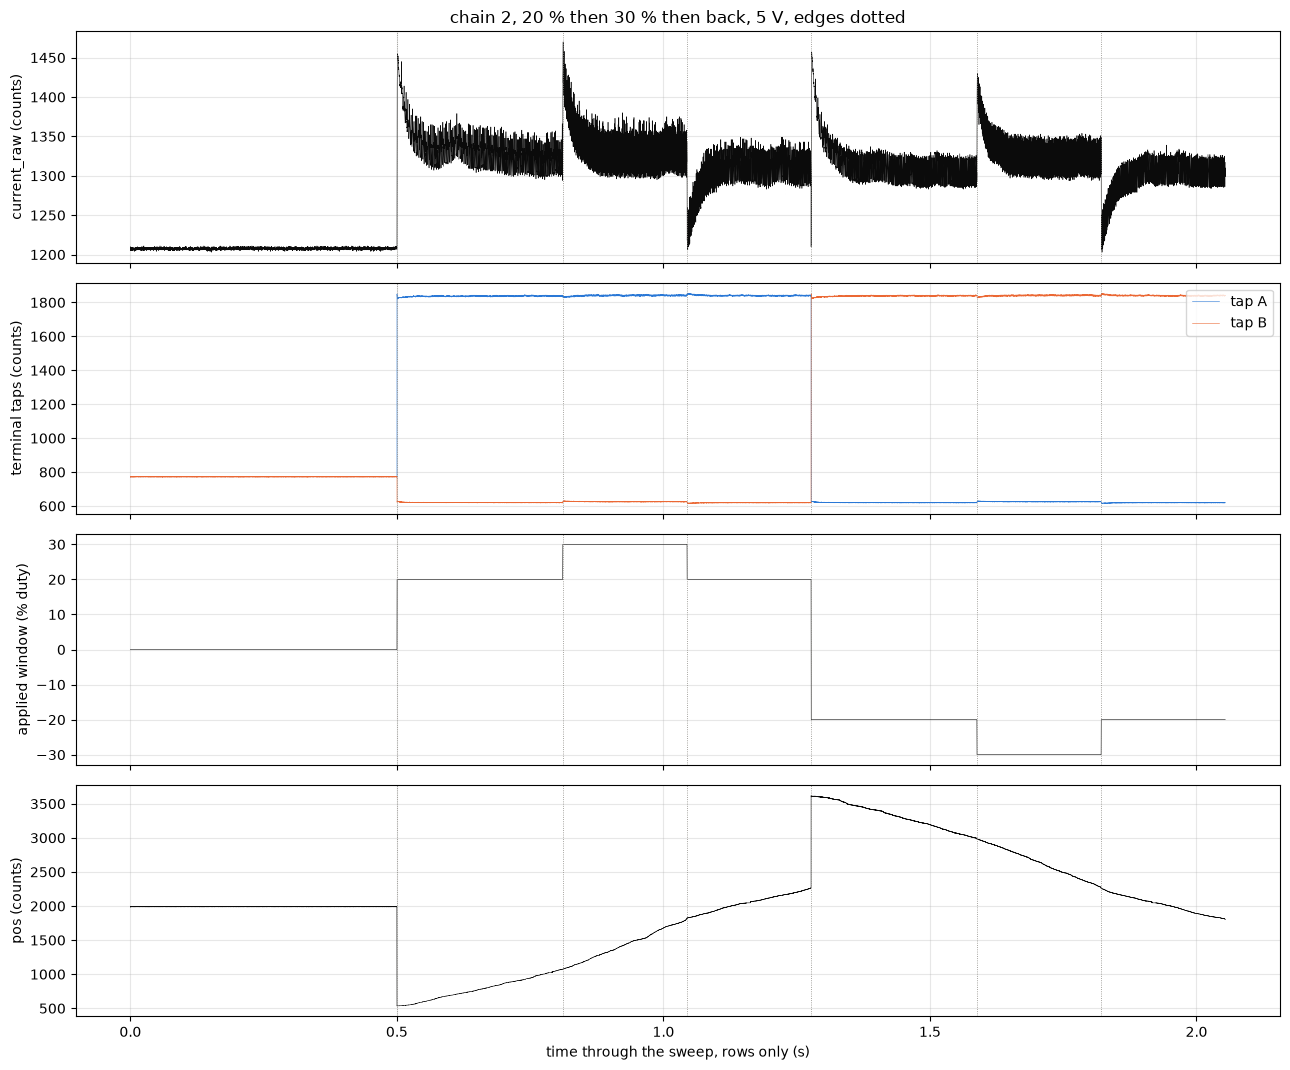

In [16]:
def overview(df, board, title):
    # a chain's raw channels against its rows, segment edges dotted
    duty_pct = df["duty_counts"] / board.pwm_arr * 100
    channels = [
        ("current_raw (counts)", [(df["current_raw"], INK)]),
        ("terminal taps (counts)", [(df["vmotor_a"], BLUE, "tap A"),
                                    (df["vmotor_b"], ORANGE, "tap B")]),
        ("applied window (% duty)", [(duty_pct, INK)]),
        ("pos (counts)", [(df["pos"], INK)]),
    ]
    fig, ax = figures.sweep_overview(df, FS, channels, title=title)
    figures.finish(fig)


overview(EX_DF, EX_BOARD, "chain 2, 20 % then 30 % then back, 5 V, edges "
         "dotted")

The baseline, then the three segments in direction +1 and the three in -1. Each base opens on the current peak of a start from rest. The step up raises the current at once and the current then falls back as the rotor gathers speed, and the step back does the reverse. The commutation ripple, the current's dip each time a brush crosses a gap between commutator segments, is 20 to 40 counts from peak to peak. The pot runs across the travel with a slope that steepens on the step.

## Method

### The chain and the applied volts

Every number goes through the chain the earlier stages built. The board is identified from each sweep's sense block and checked. The current is the crest sample over the sweep's own torque-off zero with current-scale's in-drive offset taken out. The terminal volts at the crest, $V_\mathrm{on}$ ("V on"), are the tap difference through terminal-chain, signed by the direction so drive reads positive. The duty fraction $D$ is the applied window in ticks over the 1200 tick half period.

The volts the motor sees, averaged over the PWM period, are not read directly. They are formed two ways, as the resistance and ladder notebooks left the question open.

- A, $V_A = D\,V_\mathrm{on}$, the duty times the crest volts.
- B, with stage 1's two board terms. The taps' edges lag the commanded window, so the motor sees an on-share $s = (2h - \ell_\mathrm{on} + \ell_\mathrm{off}) / P$ ("ell on", "ell off" the lags), with $h$ the half-window in ticks and $P$ the 2400 tick period. Between the on-windows the bridge brakes through the low-side loop $R_\mathrm{brk}$ ("R brake"), which drops $(1 - s)\,R_\mathrm{brk}\,I$. So $V_B = s\,V_\mathrm{on} - (1 - s)\,R_\mathrm{brk}\,I$.

The lags are constant, so a duty step changes $s$ by exactly the duty step, and on a step the two constructions differ only through the brake term's change. That is 0.6 % on the speed's gain per volt and 3 % on the resistance a step reads, B lower. Where volts enter absolutely, in the EMF balance of a settled level, the two differ by 50 to 70 mV, as the ladder found. The shapes, time constants and delays of the responses in current and speed hold no volts, so they do not depend on the construction at all.

In [17]:
def amps(current_raw, zero_i):
    # A from crest counts over the sweep's zero, the in-drive offset out
    return SCALES.amps(np.asarray(current_raw, float), zero_i, drive=True)


def v_on(rows, d):
    # V at the crest, the tap difference signed so drive reads positive
    taps = ((rows["vmotor_a"] - rows["vmotor_b"]) * d).to_numpy(float)
    return SCALES.volts(taps, TAP_OFFSET)


def share_of(half_ticks, period):
    # construction B's on-share: the window shortened by the edge lags
    h = np.asarray(half_ticks, float)
    return (2 * h - LAGS["tap_on"] + LAGS["off"]) / period


def volts_ab(D, share, von, i_a):
    # the applied volts under A and under B
    return D * von, share * von - (1 - share) * R_BRK * i_a

In [18]:
for pct in (20, 30, 40):
    half = pct / 100 * 1200             # ticks of the half period
    s = share_of(half, 2400)
    print(f"{pct} %: B's on-share {s:.4f}, {(pct / 100 - s) * 100:.2f} "
          f"points under the duty; brake term at 0.1 A "
          f"{(1 - s) * R_BRK * 0.1 * 1e3:.1f} mV")

20 %: B's on-share 0.1894, 1.06 points under the duty; brake term at 0.1 A 24.4 mV
30 %: B's on-share 0.2894, 1.06 points under the duty; brake term at 0.1 A 21.4 mV
40 %: B's on-share 0.3894, 1.06 points under the duty; brake term at 0.1 A 18.4 mV


### The flip row

A `then:` segment is chained with no release, so the duty register changes value inside the stream. The stream opens up to ten rows before the new duty shows. The flip row is the first row of a `then:` segment whose duty register shows the held value, and every time on a step is counted from it.

In [19]:
def direction_frame(df, segs):
    # the rows of `segs` end to end, and the row each segment starts on
    parts = [df[df["seg"] == s] for s in segs]
    out = pd.concat(parts, ignore_index=True)
    starts = np.cumsum([0] + [len(p) for p in parts[:-1]])
    return out, dict(zip(segs, starts))


def flip_row(seg_rows):
    # the first row showing the held duty, and the held duty in ticks
    d = seg_rows["duty_counts"].abs().to_numpy()
    held = np.median(d[len(d) // 2:])   # the segment's second half
    return int(np.flatnonzero(d == held)[0]), held

### The ripple tach through a step

The speed comes from the commutation ripple on the drive current, six events per motor turn, never from the pot. A fixed band around one line does not follow a step, since a 10 % step moves the line by a third. The tracked tach finds the upward crossings of the ripple line in chunks of four cycles, each chunk band-passed at $\pm$35 % around the line of the chunk before, so the band follows the speed through the step. It gives one speed per commutation cycle, 1 to 2 ms apart. It is seeded from the base segment 15 ms into the run-up from rest, where the line has risen above about 30 rev/s. The pot gives the travel and, over 40 ms settled windows, a second route to the settled speed.

In [20]:
def tracked_crossings(x, start, stop, f_seed, cycles=TRACK_CYCLES,
                      frac=TRACK_FRAC):
    # upward crossings of the ripple line from `start` to `stop`, the band
    # re-centered every `cycles` cycles on the last chunk's frequency
    x = np.asarray(x, float)
    out = []
    f = f_seed                          # Hz, the band's center
    last = start - 0.5
    while last < stop:
        lo = max(0, int(last - 3 * FS / f))     # 3 cycles of lead-in
        hi = min(len(x), int(last + (cycles + 4) * FS / f))
        if hi - lo < 6 * FS / f:
            break                       # too little left to filter
        tc = ripple.crossings(x[lo:hi], f, frac, FS) + lo
        tc = tc[(tc > last + 0.3 * FS / f) & (tc <= stop)]
        if len(tc) == 0:
            break                       # the line is lost
        take = tc[:cycles]
        out.extend(take.tolist())
        if len(out) >= 2:               # the line from the last chunk
            recent = out[-(cycles + 1):]
            f = (len(recent) - 1) / ((recent[-1] - recent[0]) / FS)
        last = out[-1]
        if hi >= len(x) and len(tc) <= len(take):
            break                       # the end of the data
    return np.array(out)

In [21]:
def cycle_speeds(crossings):
    # (mid time s, span s, rev/s) for each cycle between two crossings
    tc = np.asarray(crossings, float)
    span = np.diff(tc) / FS
    t_mid = (tc[:-1] + tc[1:]) / 2 / FS
    return t_mid, span, 1 / span / N_R


def ripple_line(x):
    # Hz, the ripple line of a stretch of drive current, its mean out
    return ripple.line_freq(np.asarray(x, float) - np.mean(x),
                            *ripple.BAND_HZ, fs=FS)


def speed_of(tcs):
    # rev/s over a run of crossings, nan under three of them
    if len(tcs) < 3:
        return np.nan
    return (len(tcs) - 1) / ((tcs[-1] - tcs[0]) / FS) / N_R


def smooth(x, rows):
    # a centered boxcar of `rows` rows, the ends padded with zeros
    return np.convolve(np.asarray(x, float), np.ones(rows) / rows,
                       mode="same")

Three small helpers. The line is an ordinary least-squares fit that drops non-finite points. The mean helper returns the mean, the standard deviation over the repeats and the mean's standard error. The settled window is a segment's last 40 ms, half the segment at most and 8 ms at least.

In [22]:
def line(x, y):
    # least-squares line of y on x with its standard errors
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    A = np.c_[x, np.ones_like(x)]       # columns: slope, intercept
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    res = y - A @ coef
    s2 = (res ** 2).sum() / max(len(x) - 2, 1)
    cov = s2 * np.linalg.inv(A.T @ A)
    return {"slope": coef[0], "intercept": coef[1],
            "slope_se": np.sqrt(cov[0, 0]),
            "intercept_se": np.sqrt(cov[1, 1]),
            "rms": np.sqrt((res ** 2).mean()), "n": len(x)}


def wmean(x):
    # mean, sd over the repeats, the mean's se and the count, nan dropped
    x = pd.Series(np.asarray(x, float)).dropna()
    if len(x) == 0:
        return np.nan, np.nan, np.nan, 0
    if len(x) == 1:
        return float(x.mean()), np.nan, np.nan, 1
    sd = float(x.std(ddof=1))
    return float(x.mean()), sd, sd / np.sqrt(len(x)), int(len(x))


def settled_window(n_rows):
    # (first, last) row of a segment's settled window
    n = int(min(SETTLED_MS * FS / 1e3, n_rows // 2))
    n = max(n, int(SETTLED_MIN_MS * FS / 1e3))
    return n_rows - n, n_rows

### The speed's response: one model per chain and direction

A base that is still rising when the step comes, as every 40 % chain and every inner start is, defeats a fit of one edge with a drift term (it returned negative gains there). So the speed of a whole chain-direction is fitted at once, over the run-up from rest from 15 ms in, the step up and the step back. The model is first order and piecewise. It has an initial speed, one asymptote per segment, one time constant $\tau_m$ and one delay at both flips. It is linear in the speeds, which come from linear least squares inside a nonlinear search over $\tau_m$ and the delay, the variable projection method. Each per-cycle speed is compared with the model at the cycle's midpoint. The same model with a jump of the state at each flip and no delay fits the 2 ms boxcar of the current, away from the flips, for the current's slow part.

The basis responses first. Each column is the model's response to a unit of one term, the initial state, one segment's level, or one flip's jump.

In [23]:
def chain_bases(t, switches, taus, td, t_start, jumps=False):
    # unit responses at times t: [initial, level per segment, (jumps)]
    edges = [t_start] + [sw + td for sw in switches]
    n_lev = len(edges)
    taus = list(taus) * n_lev if len(taus) == 1 else list(taus)
    n_col = 1 + n_lev + (len(switches) if jumps else 0)
    B = np.zeros((len(t), n_col))
    for col in range(n_col):
        state = 1.0 if col == 0 else 0.0       # the initial state's column
        for j, ta in enumerate(edges):
            tb = edges[j + 1] if j + 1 < n_lev else np.inf
            level = 1.0 if col == j + 1 else 0.0   # this segment's level
            if jumps and j >= 1 and col == 1 + n_lev + (j - 1):
                state += 1.0            # a jump adds to the state
            sel = (t >= ta) & (t < tb)
            B[sel, col] = level + (state - level) * np.exp(
                -(t[sel] - ta) / taus[j])
            if np.isfinite(tb):         # the state carried to the next
                state = level + (state - level) * np.exp(
                    -(tb - ta) / taus[j])
    return B

In [24]:
def chain_rows(t_all, y_all, switches, t_start, t_end, exclude_s):
    # the samples a chain fit uses: inside the window, off the switches
    t_all = np.asarray(t_all, float)
    y_all = np.asarray(y_all, float)
    sel = (t_all >= t_start) & (t_all <= t_end)
    for sw in switches:
        sel &= ~((t_all > sw - exclude_s) & (t_all < sw + exclude_s))
    return t_all[sel], y_all[sel]


def fit_chain(t_all, y_all, switches, t_start, t_end, taus=1, jumps=False,
              exclude_s=0.0, delay=True):
    # one tau (taus=1) or one per segment (taus=3), one delay or none
    t, y = chain_rows(t_all, y_all, switches, t_start, t_end, exclude_s)

    def bases(theta):
        td = theta[-1] if delay else 0.0    # s, the delay at the flips
        return chain_bases(t, switches, theta[:taus], td, t_start, jumps)

    def resid(theta):
        A = bases(theta)
        coef, *_ = np.linalg.lstsq(A, y, rcond=None)   # levels, linear
        return A @ coef - y

    lo_t, hi_t = TAU_M_BOUNDS_MS[0] * 1e-3, TAU_M_BOUNDS_MS[1] * 1e-3
    lo = [lo_t] * taus + ([SPEED_DELAY_BOUNDS_MS[0] * 1e-3] if delay else [])
    hi = [hi_t] * taus + ([SPEED_DELAY_BOUNDS_MS[1] * 1e-3] if delay else [])
    best = None
    for tau0 in (8e-3, 15e-3, 30e-3):   # several starts, the best kept
        for td0 in ((0.3e-3, 1.5e-3) if delay else (None,)):
            x0 = [tau0] * taus + ([td0] if delay else [])
            r = least_squares(resid, x0=x0, bounds=(lo, hi))
            if best is None or r.cost < best.cost:
                best = r
    A = bases(best.x)
    return chain_terms(A, t, y, best, len(switches) + 1, taus, jumps, delay)

In [25]:
def chain_terms(A, t, y, best, n_lev, taus, jumps, delay):
    # the levels and jumps by least squares, every term's standard error
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    res = A @ coef - y
    dof = max(len(y) - A.shape[1] - len(best.x), 1)
    s2 = (res ** 2).sum() / dof         # the residual's variance
    try:
        se = np.sqrt(np.diag(s2 * np.linalg.inv(best.jac.T @ best.jac)))
    except np.linalg.LinAlgError:
        se = np.full(len(best.x), np.nan)
    try:
        se_lin = np.sqrt(np.diag(s2 * np.linalg.inv(A.T @ A)))
    except np.linalg.LinAlgError:
        se_lin = np.full(A.shape[1], np.nan)
    out = {"taus_s": best.x[:taus], "taus_se_s": se[:taus],
           "td_s": best.x[-1] if delay else 0.0,
           "td_se_s": se[-1] if delay else np.nan,
           "w_init": coef[0], "levels": coef[1:1 + n_lev],
           "levels_se": se_lin[1:1 + n_lev],
           "rms": float(np.sqrt((res ** 2).mean())), "n": int(len(y)),
           "t": t, "y": y, "model": A @ coef, "resid": res}
    if jumps:
        out["jumps"] = coef[1 + n_lev:]
        out["jumps_se"] = se_lin[1 + n_lev:]
    return out

### Two per-edge alternatives, kept as checks

The current's step on one edge is about as large as the commutation ripple riding on it, and the ripple's phase is random against the flip. The first alternative fits one edge with the ripple as a four-harmonic Fourier template in the phase continued from the last four crossings before the flip, its amplitude free to scale with the step, jointly with a level, a slope and the step $\Delta i\,(1 - e^{-(k - t_0)/\tau_e})$ ("delta i", "t zero"), $k$ in rows. The template does not predict the ripple after the edge, so this fit scatters, and it is shown only to say why the ensemble below is the method of record.

In [26]:
def ripple_phase(k, tc_pre):
    # the ripple's phase in cycles at rows k, a line through the last
    # crossings before the flip continued through the edge
    tc_pre = np.asarray(tc_pre, float)
    j = np.arange(len(tc_pre))
    slope, icpt = np.polyfit(tc_pre, j, 1)
    return slope * np.asarray(k, float) + icpt, 1 / slope


def template_basis(i_counts, flip, tc):
    # rows, samples, and level + slope + Fourier columns around a flip
    tc = np.asarray(tc, float)
    before = tc[tc < flip - 1]
    if len(before) < PRE_CYCLES + 1:
        raise ValueError("too few crossings before the flip")
    tc_pre = before[-(PRE_CYCLES + 1):]
    pre = int(flip - np.ceil(tc_pre[0]))   # rows from the first crossing
    k = np.arange(-pre, POST_ROWS + 1, dtype=float)
    y = np.asarray(i_counts, float)[flip - pre: flip + POST_ROWS + 1]
    phase, period = ripple_phase(k + flip, tc_pre)
    cols = [np.ones_like(k), k]
    for h in range(1, HARMONICS + 1):
        cols += [np.cos(2 * np.pi * h * phase),
                 np.sin(2 * np.pi * h * phase)]
    return k, y, np.c_[tuple(cols)]

In [27]:
def fit_current_step(i_counts, flip, tc):
    # the per-edge template fit: t0 and tau in rows, the step in counts
    k, y, B = template_basis(i_counts, flip, tc)

    def design(theta):
        t0, tau, rho = theta            # rho scales the ripple on the step
        step = np.where(k >= t0, 1 - np.exp(-np.clip(k - t0, 0, None)
                                            / tau), 0.0)
        Bs = B.copy()
        Bs[:, 2:] *= (1 + rho * step)[:, None]
        return np.hstack([Bs, step[:, None]])

    def resid(theta):
        A = design(theta)
        coef, *_ = np.linalg.lstsq(A, y, rcond=None)
        return A @ coef - y

    lo = [T0_BOUNDS_ROWS[0], TAU_BOUNDS_ROWS[0], -0.9]
    hi = [T0_BOUNDS_ROWS[1], TAU_BOUNDS_ROWS[1], 4.0]
    best = None
    for t0_start in (0.0, 2.0, 4.0):
        for tau_start in (2.0, 5.0):
            r = least_squares(resid, x0=[t0_start, tau_start, 0.3],
                              bounds=(lo, hi))
            if best is None or r.cost < best.cost:
                best = r
    A = design(best.x)
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    res = A @ coef - y
    return {"t0_rows": best.x[0], "tau_rows": best.x[1],
            "di_counts": coef[-1],
            "rms_counts": float(np.sqrt((res ** 2).mean()))}

The second alternative fits the speed of one edge on its own, the per-cycle speeds 25 ms before the flip to the next flip, with an initial speed, a linear drift, a step $\Delta\omega$ through $\tau_m$ and a delay, each cycle compared with the model's mean over that cycle. It holds on a settled base and is kept only as a check there.

In [28]:
def exp_mean(ta, tb, tau):
    # the mean of 1 - exp(-t/tau) over [ta, tb], both clipped at 0
    ta = np.clip(ta, 0, None)
    tb = np.clip(tb, 0, None)
    dt = tb - ta
    with np.errstate(divide="ignore", invalid="ignore"):
        m = 1 - tau * (np.exp(-ta / tau) - np.exp(-tb / tau)) / dt
    return np.where(dt > 0, m, 1 - np.exp(-ta / tau))


def fit_speed_step(t_mid, span, w, t_flip, t_end, pre_s):
    # the per-edge speed check: w0 + s (t - t_flip) + dw x the cycle mean
    sel = (t_mid >= t_flip - pre_s) & (t_mid <= t_end)
    t, sp, y = t_mid[sel], span[sel], w[sel]
    ta, tb = t - sp / 2 - t_flip, t + sp / 2 - t_flip

    def design(theta):
        resp = exp_mean(ta - theta[0], tb - theta[0], theta[1])
        return np.c_[np.ones_like(t), t - t_flip, resp]

    def resid(theta):
        A = design(theta)
        coef, *_ = np.linalg.lstsq(A, y, rcond=None)
        return A @ coef - y

    lo = [SPEED_DELAY_BOUNDS_MS[0] * 1e-3, TAU_M_BOUNDS_MS[0] * 1e-3]
    hi = [SPEED_DELAY_BOUNDS_MS[1] * 1e-3, TAU_M_BOUNDS_MS[1] * 1e-3]
    best = None
    for td0 in (0.5e-3, 2e-3):
        for tau0 in (10e-3, 25e-3, 60e-3):
            r = least_squares(resid, x0=[td0, tau0], bounds=(lo, hi))
            if best is None or r.cost < best.cost:
                best = r
    coef, *_ = np.linalg.lstsq(design(best.x), y, rcond=None)
    return {"td_s": best.x[0], "tau_m_s": best.x[1], "dw": coef[-1]}

### Reading one chain direction

The rows of one direction are taken end to end, converted, and its two flips found. Then the tracked tach runs from 15 ms into the base to the end, and the chain models are fitted to it and to the current.

In [29]:
SEGS = {1: (1, 2, 3), -1: (4, 5, 6)}    # base, step, back per direction
LEVELS = ("base", "up", "back")


def direction_signals(df, board, d):
    # one direction's rows end to end, converted, and its two flips
    fr, starts = direction_frame(df, SEGS[d])
    zero_i, zero_e = tel.rest_zeros(df)  # the torque-off medians
    raw = fr["current_raw"].to_numpy(float)
    i_a = amps(raw, zero_i)              # A, in-drive offset out
    von = v_on(fr, d)                    # V, the crest tap difference
    half = fr["duty_counts"].abs().to_numpy(float)    # ticks
    D = half / board.pwm_arr             # the duty fraction
    share = share_of(half, 2 * board.pwm_arr)   # B's on-share
    v_a, v_b = volts_ab(D, share, von, i_a)
    s1, s2, s3 = (starts[s] for s in SEGS[d])
    f_up, held_up = flip_row(fr.iloc[s2:s3])
    f_dn, held_dn = flip_row(fr.iloc[s3:])
    return SimpleNamespace(
        fr=fr, d=d, zero_i=zero_i, zero_e=zero_e, raw=raw, i_a=i_a,
        von=von, half=half, D=D, share=share, v_a=v_a, v_b=v_b,
        pos=fr["pos"].to_numpy(float), n=len(fr), s1=s1, s2=s2, s3=s3,
        flip_up=s2 + f_up, flip_dn=s3 + f_dn, f_up=f_up, f_dn=f_dn,
        held_up=held_up, held_dn=held_dn, pwm_arr=board.pwm_arr)

In [30]:
def chain_tach(s):
    # the tracked ripple tach, 15 ms into the run-up to the end
    drive0 = s.s1 + tel.drive_start(s.fr.iloc[s.s1:s.s2])
    track_from = drive0 + int(TRACK_FROM_MS * 1e-3 * FS)
    seed = s.raw[track_from:min(track_from + int(0.010 * FS), s.flip_up)]
    f_seed = ripple_line(seed)          # Hz, the base's own line
    tc = tracked_crossings(s.raw, track_from, s.n - 1, f_seed)
    t_mid, span, w = cycle_speeds(tc)
    return SimpleNamespace(drive0=drive0, track_from=track_from,
                           f_seed=f_seed, tc=tc, t_mid=t_mid, span=span,
                           w=w)


def chain_models(s, t):
    # the speed's chain model with one tau and with three, and the
    # current's slow model with a jump at each flip
    t_fit0 = t.tc[2] / FS               # s, from the third crossing on
    switches = [s.flip_up / FS, s.flip_dn / FS]
    ch1 = fit_chain(t.t_mid, t.w, switches, t_fit0, s.n / FS, taus=1)
    ch3 = fit_chain(t.t_mid, t.w, switches, t_fit0, s.n / FS, taus=3)
    i_box = smooth(s.i_a, I_BOX_ROWS)   # A, the 2 ms boxcar
    rows = np.arange(t.track_from, s.n - I_BOX_ROWS // 2, 10)  # 0.5 ms
    ci = fit_chain(rows / FS, i_box[rows] * 1e3, switches, t_fit0,
                   s.n / FS, taus=1, jumps=True,
                   exclude_s=I_EXCLUDE_MS * 1e-3, delay=False)
    return ch1, ch3, ci

The chain models' terms as one flat row, in ms, rev/s and mA. `w_*_chain` are the speed's asymptotes per segment, `tau_runup`, `tau_up3` and `tau_down3` the three-constant model's, `i_*_chain_ma` the current's settled levels and `i_jump_*` its jumps at the flips.

In [31]:
def chain_row_of(ch1, ch3, ci):
    # every chain model term a later table reads, flat
    row = {"tau_m_chain_ms": ch1["taus_s"][0] * 1e3,
           "tau_m_chain_se_ms": ch1["taus_se_s"][0] * 1e3,
           "w_delay_chain_ms": ch1["td_s"] * 1e3,
           "w_delay_chain_se_ms": ch1["td_se_s"] * 1e3,
           "w_init_chain": ch1["w_init"], "chain_rms_rev_s": ch1["rms"],
           "chain_cycles": ch1["n"], "w_delay_chain3_ms": ch3["td_s"] * 1e3,
           "chain3_rms_rev_s": ch3["rms"],
           "tau_i_chain_ms": ci["taus_s"][0] * 1e3,
           "tau_i_chain_se_ms": ci["taus_se_s"][0] * 1e3,
           "chain_i_rms_ma": ci["rms"]}
    for j, seg in enumerate(LEVELS):    # per segment
        row[f"w_{seg}_chain"] = ch1["levels"][j]
        row[f"w_{seg}_chain_se"] = ch1["levels_se"][j]
        row[f"w_{seg}_chain3"] = ch3["levels"][j]
        row[f"i_{seg}_chain_ma"] = ci["levels"][j]
        row[f"i_{seg}_chain_se_ma"] = ci["levels_se"][j]
    for j, part in enumerate(("runup", "up3", "down3")):
        row[f"tau_{part}_ms"] = ch3["taus_s"][j] * 1e3
        row[f"tau_{part}_se_ms"] = ch3["taus_se_s"][j] * 1e3
    for j, edge in enumerate(("up", "dn")):     # per flip
        row[f"i_jump_{edge}_chain_ma"] = ci["jumps"][j]
        row[f"i_jump_{edge}_chain_se_ma"] = ci["jumps_se"][j]
    return row

The settled level of each segment, over its settled window. The tach's speed is the whole cycles inside the window, and the settle is the window's second half over its first, less one. The pot's speed is a line through its counts. The EMF balance $X = V - R\,I - K_e\,\omega$ ("X") of each level is formed under A and under B with the locked $R$ and the ladder's $K_e$.

In [32]:
def level_row(s, t, base, name, a, b):
    # one segment's settled window, rows a to b of the direction
    w0, w1 = settled_window(b - a)
    lo, hi = a + w0, a + w1
    mid = (lo + hi) // 2
    tcs = t.tc[(t.tc >= lo) & (t.tc <= hi)]
    w_tach = speed_of(tcs)              # rev/s, whole cycles in the window
    w_first = speed_of(t.tc[(t.tc >= lo) & (t.tc <= mid)])
    w_second = speed_of(t.tc[(t.tc > mid) & (t.tc <= hi)])
    pl = line(np.arange(hi - lo) / FS, s.pos[lo:hi])   # counts per s
    win = slice(lo, hi)
    trough = s.fr["current_trough"].to_numpy(float)[win]
    row = {**base, "level": name, "seg": SEGS[s.d][LEVELS.index(name)],
           "duty_pct": float(np.median(s.D[win]) * 100), "rows": b - a,
           "window_ms": (hi - lo) / FS * 1e3,
           "i_ma": float(s.i_a[win].mean() * 1e3),
           "i_sd_ma": float(s.i_a[win].std() * 1e3),
           "trough_over_zero_counts": float(np.nanmean(trough) - s.zero_i),
           "v_on_v": float(s.von[win].mean()),
           "share": float(s.share[win].mean()),
           "v_a_v": float(s.v_a[win].mean()),
           "v_b_v": float(s.v_b[win].mean()),
           "w_tach_rev_s": w_tach, "w_tach_cycles": int(len(tcs)) - 1,
           "settle_pct": ((w_second / w_first - 1) * 100
                          if np.isfinite(w_first) else np.nan),
           "w_pot_rev_s": pl["slope"] / COUNTS_PER_MOTOR_REV * s.d,
           "travel_counts": float(s.pos[b - 1] - s.pos[a]),
           "window_valid": float(s.fr["window_valid"].to_numpy(float)[
               win].mean())}
    for tag in ("a", "b"):              # the EMF balance under A and B
        e = row[f"v_{tag}_v"] - R_LOCKED * row["i_ma"] * 1e-3
        row[f"x_{tag}_mv"] = ((e - KE_LADDER * w_tach) * 1e3
                              if np.isfinite(w_tach) else np.nan)
    return row

Each edge's volts. The duty step is the held ticks after the flip less those before, as a percent. The applied change under A is the step times the crest volts over the 2 ms before the flip, `dv_a_v`. The rail sags a little on a step up, so the same with the volts 0.5 to 2 ms after the flip is kept beside it, `dv_a_after_v`.

In [33]:
def edge_volts(s, name, flip):
    # the duty step and the applied change under A, before and after
    if name == "up":
        d_duty = ((s.held_up - np.median(s.half[s.s1 + 40:s.s2]))
                  / s.pwm_arr * 100)
    else:
        d_duty = (s.held_dn - s.held_up) / s.pwm_arr * 100
    von_edge = float(s.von[flip - 40:flip].mean())     # V, 2 ms before
    von_after = float(s.von[flip + 10:flip + 40].mean())   # 0.5 to 2 ms
    i0 = float(s.i_a[flip - 40:flip].mean())           # A before the flip
    D0 = float(np.median(s.D[flip - 40:flip]))
    D1 = D0 + d_duty / 100
    return {"d_duty_pct": float(d_duty), "v_on_edge_v": von_edge,
            "i0_ma": i0 * 1e3, "dv_a_v": d_duty / 100 * von_edge,
            "dv_a_after_v": D1 * von_after - D0 * von_edge,
            "von_step_mv": (von_after - von_edge) * 1e3}


def edge_aligned(s, name, flip, t_end):
    # the raw current from 60 rows before the flip to 500 after, over its
    # 2 ms before the flip; nan past the segment's end
    post = min(ALIGN_POST, (t_end - flip) if name == "up" else (s.n - flip))
    win = np.full(ALIGN_PRE + ALIGN_POST, np.nan)
    win[:ALIGN_PRE + post] = s.raw[flip - ALIGN_PRE: flip + post]
    return win - win[ALIGN_PRE - 40:ALIGN_PRE].mean()

The settled change across each edge, by the levels and by the chain models. `r_takeback_ohm` is a resistance with no volts in it. Once the speed has followed, the current has fallen from its plateau by $R\,\Delta i = K_e\,\Delta\omega$, so $R = K_e\,\Delta\omega / (\Delta i_\mathrm{jump} - \Delta i_\mathrm{settled})$, all three from the chain models.

In [34]:
def edge_settled(row, levels, chain, name):
    # the settled changes across one edge, its gains and take-back R
    lv = {r["level"]: r for r in levels}
    a, b = ("base", "up") if name == "up" else ("up", "back")
    d_duty = row["d_duty_pct"]
    row["di_ss_ma"] = lv[b]["i_ma"] - lv[a]["i_ma"]
    row["dw_ss_tach_rev_s"] = lv[b]["w_tach_rev_s"] - lv[a]["w_tach_rev_s"]
    row["dw_ss_pot_rev_s"] = lv[b]["w_pot_rev_s"] - lv[a]["w_pot_rev_s"]
    row["travel_counts"] = lv[b]["travel_counts"]
    tag3, jump = ("up3", "up") if name == "up" else ("down3", "dn")
    row["dw_chain_rev_s"] = chain[f"w_{b}_chain"] - chain[f"w_{a}_chain"]
    row["k_w_chain_rev_s_per_pct"] = row["dw_chain_rev_s"] / d_duty
    row["tau_m_edge3_ms"] = chain[f"tau_{tag3}_ms"]
    row["di_ss_chain_ma"] = chain[f"i_{b}_chain_ma"] - chain[
        f"i_{a}_chain_ma"]
    row["di_jump_chain_ma"] = chain[f"i_jump_{jump}_chain_ma"]
    row["k_i_ss_chain_ma_per_pct"] = row["di_ss_chain_ma"] / d_duty
    fall = row["di_jump_chain_ma"] - row["di_ss_chain_ma"]   # mA
    row["r_takeback_ohm"] = (KE_LADDER * row["dw_chain_rev_s"]
                             / (fall * 1e-3) if fall else np.nan)
    row["k_w_ss_rev_s_per_pct"] = row["dw_ss_tach_rev_s"] / d_duty
    return row

One edge, the two per-edge checks run on it and its aligned current kept for the ensemble.

In [35]:
def edge_row(s, t, base, chain, levels, name):
    # one edge's row and its trace for the ensemble
    flip, t_end = ((s.flip_up, s.flip_dn) if name == "up"
                   else (s.flip_dn, s.n - 1))
    row = {**base, **chain, "edge": name, "flip_row": int(flip),
           **edge_volts(s, name, flip)}
    cf = fit_current_step(s.raw, flip, t.tc)    # the template check
    row["i_delay_us"] = cf["t0_rows"] * ROW_US
    row["tau_e_us"] = cf["tau_rows"] * ROW_US
    row["di_e_ma"] = cf["di_counts"] * A_PER_COUNT * 1e3
    pre_s = SPEED_PRE_MS * 1e-3         # the speed check's lead
    if name == "up":                    # never back into the run-up
        pre_s = min(pre_s, (flip - t.track_from) / FS - 2e-3)
    sf = fit_speed_step(t.t_mid, t.span, t.w, flip / FS, t_end / FS, pre_s)
    row["w_delay_ms"] = sf["td_s"] * 1e3
    row["tau_m_ms"] = sf["tau_m_s"] * 1e3
    row["k_w_rev_s_per_pct"] = sf["dw"] / row["d_duty_pct"]
    row = edge_settled(row, levels, chain, name)
    trace = {"aligned_counts": edge_aligned(s, name, flip, t_end),
             "aligned_i0_ma": row["i0_ma"],
             "aligned_von": row["v_on_edge_v"],
             "d_duty_pct": row["d_duty_pct"]}
    return row, trace

### The take-up from rest

In every base segment the drive starts from rest at the start position. The pot reads a few counts off the moment the drive turns on, before any motion (the reversals section returns to this), so its still reference is read 0.1 to 2 ms in. The still interval ends when the 1 ms smoothed pot has moved 2.5 counts in the drive's direction. The rotor's turns in that interval come by three routes.

- The current route. The rotor, free inside the play, turns at $K_t I / J$ with the type's $J$ and this motor's $K_e$ as $K_t$, integrated twice. 30 mA of drag taken off the current is the bracket.
- The EMF route, $(V - R\,I)/K_e$ integrated under A and under B. It differences two near-equal terms, about 1 V and 0.9 V.
- The commutation dips counted, six per turn.

The play crossed is the rotor's turns less the output's own 2.5 counts in motor turns.

In [36]:
def still_interval(s, drive0):
    # the pot before the drive, its still reference, and the still rows
    p_before = (float(np.median(s.pos[s.s1:drive0])) if drive0 > s.s1
                else np.nan)
    p0 = float(np.median(s.pos[drive0 + 2:drive0 + 40]))   # 0.1 to 2 ms
    pos_s = smooth(s.pos, POT_STILL_BOX)
    moved = np.flatnonzero((pos_s[drive0 + 20:s.s2] - p0) * s.d
                           > POT_STILL_COUNTS)
    still = int(moved[0]) + 20 if len(moved) else s.s2 - drive0
    return p_before, p0, still


def count_dips(raw, a, b):
    # commutation dips in rows a to b: local minima of the 3-row smoothed
    # current deeper than DIP_COUNTS under their 9-row neighborhood
    seg = smooth(raw, 3)[a:b]
    if len(seg) <= 12:
        return 0
    loc = smooth(seg, 9)
    is_min = ((seg[1:-1] < seg[:-2]) & (seg[1:-1] <= seg[2:])
              & (loc[1:-1] - seg[1:-1] > DIP_COUNTS))
    return int(is_min.sum())

In [37]:
KT_OVER_J = KE_LADDER / (2 * np.pi) / J_TYPE   # (N m/A) / (kg m^2)


def current_route(i_a, sl):
    # motor turns and end speed of a free rotor at Kt i / J from rest,
    # with no drag and with I_DRAG_A of drag taken off the current
    out = {}
    for tag, drag in (("0", 0.0), ("drag", I_DRAG_A)):
        acc = KT_OVER_J * np.clip(i_a[sl] - drag, 0, None)   # rad/s^2
        if len(acc) > 1:                # trapezoid, then again
            w = np.concatenate([[0.0], np.cumsum((acc[1:] + acc[:-1]) / 2)
                                / FS])
        else:
            w = np.zeros(1)
        out[tag] = (float(np.trapezoid(w, dx=1 / FS) / (2 * np.pi))
                    if len(w) > 1 else np.nan)
        out[tag + "_w_end"] = float(w[-1] / (2 * np.pi))
    return out

In [38]:
def takeup_row(s, t, base):
    # the take-up from rest at the base segment's start, three routes
    drive0 = t.drive0
    p_before, p0, still = still_interval(s, drive0)
    end = drive0 + still                # the row the pot has moved
    sl = slice(drive0 + 2, end)         # the first two rows: taps settle
    turns = {}
    for tag, v in (("a", s.v_a), ("b", s.v_b)):    # the EMF route
        w = (v - R_LOCKED * s.i_a) / KE_LADDER       # rev/s
        turns[tag] = float(np.trapezoid(np.clip(w[sl], 0, None),
                                        dx=1 / FS))
    out_turns = (abs(s.pos[end] - p0) / COUNTS_PER_MOTOR_REV
                 if end < s.n else np.nan)
    dips = count_dips(s.raw, drive0 + 10, end)
    cur = current_route(s.i_a, sl)
    peak = drive0 + int(np.argmax(s.i_a[drive0:drive0 + 400]))
    return {**base, "still_ms": still / FS * 1e3,
            "pot_shift_counts": (p0 - p_before) * s.d,
            "turns_a": turns["a"], "turns_b": turns["b"],
            "out_turns": out_turns,
            "play_turns_a": turns["a"] - out_turns,
            "play_turns_b": turns["b"] - out_turns,
            "dips": dips, "dip_turns": dips / N_R,
            "turns_cur": cur["0"], "turns_cur_drag": cur["drag"],
            "play_turns_cur": cur["0"] - out_turns,
            "play_turns_cur_drag": cur["drag"] - out_turns,
            "w_end_cur_rev_s": cur["0_w_end"],
            "i_peak_ma": float(s.i_a[peak] * 1e3),
            "i_peak_ms": (peak - drive0) / FS * 1e3}, (p0, still)

In [39]:
def reduce_direction(df, board, d, info):
    # every row one direction of one chain gives, and its traces
    s = direction_signals(df, board, d)
    t = chain_tach(s)
    base = {"k": int(info["k"]), "dir": d,
            "start_share": float(info["start_share"]),
            "base_pct": int(info["base_pct"]),
            "step_pct": int(info["step_pct"]),
            "zero_i": float(s.zero_i), "t_start": float(info["t_start"])}
    ch1, ch3, ci = chain_models(s, t)
    chain = chain_row_of(ch1, ch3, ci)
    bounds = [(s.s1, s.s2), (s.s2, s.s3), (s.s3, s.n)]
    levels = [level_row(s, t, base, name, a, b)
              for name, (a, b) in zip(LEVELS, bounds)]
    edges, trace = [], {"base": base, "s": s, "t": t, "chain1": ch1,
                        "chain_i": ci}
    for name in ("up", "down"):
        row, trace[name] = edge_row(s, t, base, chain, levels, name)
        edges.append(row)
    takeup, (p0, still) = takeup_row(s, t, base)
    lo = max(t.drive0 - 20, 0)          # the pot around the start
    trace["takeup"] = {"pos": s.pos[lo:t.drive0 + 600],
                       "row0": t.drive0 - lo, "still_rows": still}
    return edges, levels, takeup, trace

### Reading every chain

Every chain of `capture-1`, both directions. A chain with a dropped row stops the notebook.

In [40]:
EDGE_ROWS, LEVEL_ROWS, TAKEUP_ROWS, TRACES = [], [], [], []
for _, info in CHAINS.iterrows():
    df, meta, board = load(CAPTURE / info["folder"])
    assert tel.gaps(df).sum() == 0, f"{info['folder']}: dropped rows"
    for d in (1, -1):
        e, lv, tk, tr = reduce_direction(df, board, d, info)
        EDGE_ROWS += e
        LEVEL_ROWS += lv
        TAKEUP_ROWS.append(tk)
        TRACES.append(tr)
E = pd.DataFrame(EDGE_ROWS)             # one row per edge, 108
L = pd.DataFrame(LEVEL_ROWS)            # one row per segment level, 162
T = pd.DataFrame(TAKEUP_ROWS)           # one row per start from rest, 54
print(f"{len(E)} edges, {len(L)} levels, {len(T)} starts from rest; "
      f"rows dropped in no chain")
show(E[["k", "dir", "base_pct", "step_pct", "edge", "d_duty_pct",
        "tau_m_chain_ms", "w_delay_chain_ms", "chain_rms_rev_s",
        "k_w_chain_rev_s_per_pct", "r_takeback_ohm"]], n=6)

108 edges, 162 levels, 54 starts from rest; rows dropped in no chain


,k,dir,base_pct,step_pct,edge,d_duty_pct,tau_m_chain_ms,w_delay_chain_ms,chain_rms_rev_s,k_w_chain_rev_s_per_pct,r_takeback_ohm
0,0,1,20,2,up,2.000,35.953,0.000,2.742,10.852,6.030
1,0,1,20,2,down,-2.000,35.953,0.000,2.742,6.487,7.016
2,0,-1,20,2,up,2.000,17.541,0.000,2.002,5.331,6.320
3,0,-1,20,2,down,-2.000,17.541,0.000,2.002,5.388,7.884
4,1,1,20,5,up,5.000,26.118,0.000,2.488,7.504,5.347
5,1,1,20,5,down,-5.000,26.118,0.000,2.488,5.614,5.295


## The ripple tach through a step

One chain-direction end to end, chain 2 in direction +1, 20 % then 30 % then back, from the guards. The thing to see is the tach following the speed through both steps, one point per commutation cycle, and the one-constant chain model laid over it. The pot's speed, a 4 ms difference smoothed over 10 ms, is drawn beside it as the noise it is at this time scale.

In [41]:
def overview_current_speed(axes, tr):
    # the crest current with its slow model, the tach with its chain model
    s, t, b = tr["s"], tr["t"], tr["base"]
    ms = np.arange(s.n) / FS * 1e3
    ci, ch = tr["chain_i"], tr["chain1"]
    axes[0].plot(ms, s.i_a * 1e3, lw=figures.TRACE_LW, color=BLUE,
                 label="crest current, every row")
    axes[0].plot(ci["t"] * 1e3, ci["model"], color=RED, lw=1.2,
                 label=f"levels + jumps + one time constant "
                 f"{ci['taus_s'][0] * 1e3:.1f} ms")
    figures.label(axes[0], y="current (mA)")
    axes[1].plot(t.t_mid * 1e3, t.w, ".", ms=3, color=BLUE,
                 label="ripple tach, one point per commutation cycle")
    axes[1].plot(ch["t"] * 1e3, ch["model"], color=RED, lw=1.2,
                 label=f"first-order model, tau {ch['taus_s'][0] * 1e3:.1f}"
                 f" ms, delay {ch['td_s'] * 1e3:.2f} ms, rms "
                 f"{ch['rms']:.1f} rev/s")
    wp = pot_speed_rev_s(s.pos) * b["dir"]
    axes[1].plot(ms, smooth(np.nan_to_num(wp), 200), color=MUTED, lw=0.8,
                 label="pot speed, 10 ms boxcar (noise, not a reference)")
    figures.label(axes[1], y="motor speed (rev/s)")
    for ax in axes:
        ax.legend(loc="upper right")


def pot_speed_rev_s(pos, box=POT_BOX_ROWS):
    # motor rev/s by a centered 4 ms difference, nominal counts per turn
    p = np.asarray(pos, float)
    v = np.full_like(p, np.nan)
    v[box // 2: -box // 2] = (p[box:] - p[:-box]) / (box / FS)
    return v / COUNTS_PER_MOTOR_REV

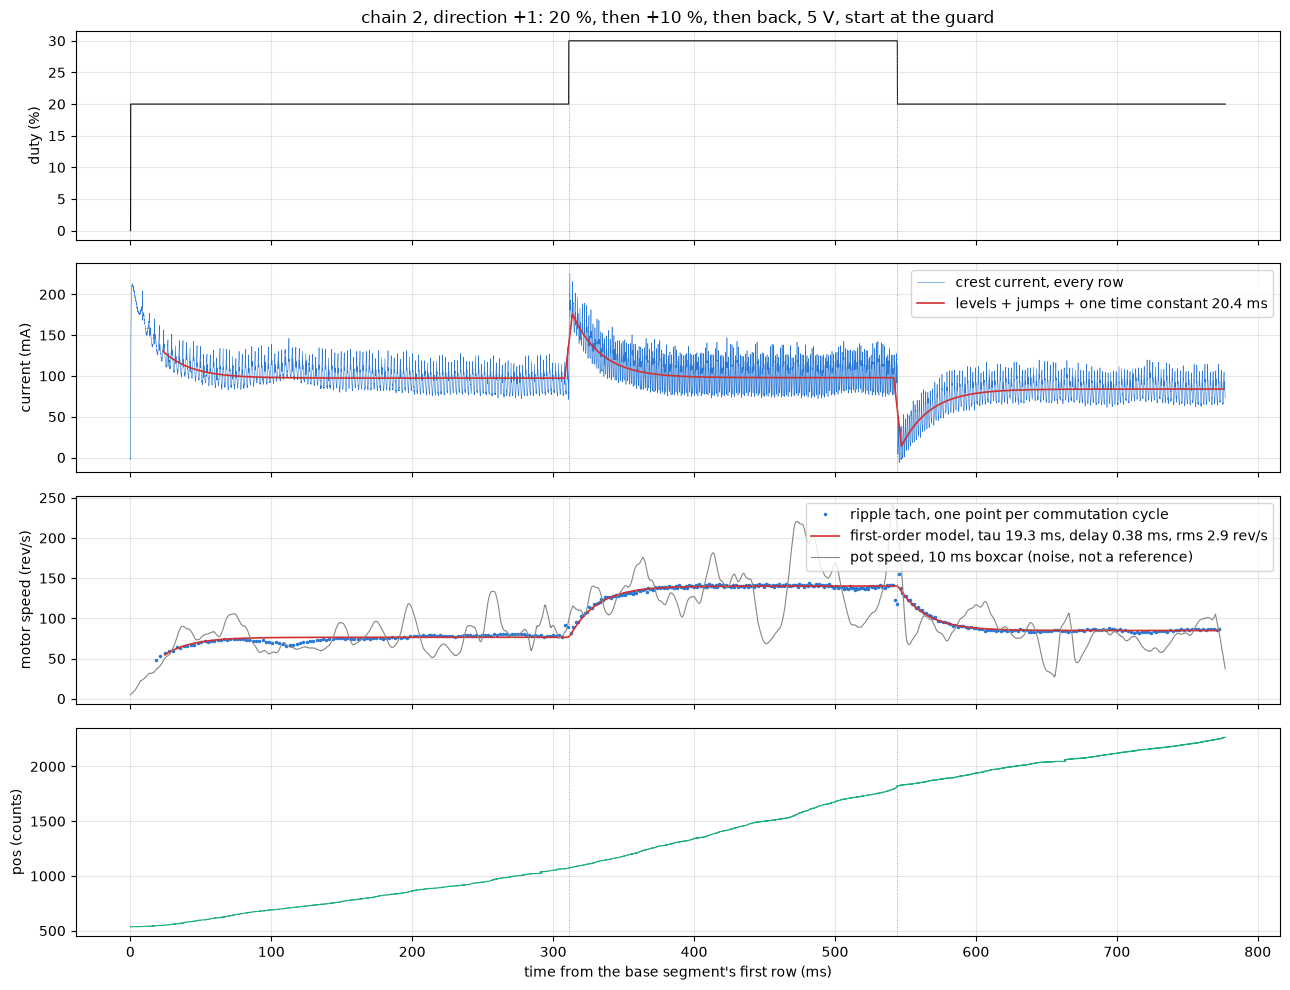

In [42]:
EX_TRACE = next(tr for tr in TRACES
                if tr["base"]["k"] == 2 and tr["base"]["dir"] == 1)
s, b = EX_TRACE["s"], EX_TRACE["base"]
ms = np.arange(s.n) / FS * 1e3
fig, axes = plt.subplots(4, 1, sharex=True, figsize=(13, 10))
axes[0].plot(ms, s.D * 100, color=INK, lw=0.8)
figures.label(axes[0], y="duty (%)", title=f"chain {b['k']}, direction +1:"
              f" {b['base_pct']} %, then +{b['step_pct']} %, then back, "
              "5 V, start at the guard")
overview_current_speed(axes[1:3], EX_TRACE)
axes[3].plot(ms, s.pos, lw=0.8, color=GREEN)
figures.label(axes[3], x="time from the base segment's first row (ms)",
              y="pos (counts)")
for ax in axes:
    for r in (s.flip_up, s.flip_dn):
        ax.axvline(r / FS * 1e3, **figures.EDGE_STYLE)
figures.finish(fig)

The duty steps at the two dotted lines. The current jumps up at the first, then falls back over about 20 ms while the speed rises toward its new level, and does the mirror image at the second. The tach follows the speed through each step with a scatter of a few rev/s, the commutation's own unevenness from cycle to cycle. The pot's speed carries the pot's own noise and its 250 Hz comb, ten times the tach's scatter at this smoothing, so it serves only for the travel and the settled windows.

## The current's response to a duty step

### The ripple problem

The commutation ripple is 20 to 40 counts from peak to peak at 500 to 1200 Hz, as large as the current's change on a 5 % step, and its phase at the flip is random. The per-edge template fit, the first alternative of the method, does not hold the ripple through the edge. Its electrical time constant per edge is the thing to see.

In [43]:
q10, q50, q90 = np.percentile(E["tau_e_us"], [10, 50, 90])
print(f"per-edge template fit, tau_e over {len(E)} edges: "
      f"{E['tau_e_us'].min():.0f} to {E['tau_e_us'].max():.0f} us, median "
      f"{q50:.0f}, 10th to 90th percentile {q10:.0f} to {q90:.0f}")
at_bound = (E["tau_e_us"] >= TAU_BOUNDS_ROWS[1] * ROW_US - 1e-6).sum()
print(f"{at_bound} edges at the fit's upper bound of "
      f"{TAU_BOUNDS_ROWS[1] * ROW_US:.0f} us; not used for any number")

per-edge template fit, tau_e over 108 edges: 25 to 1500 us, median 108, 10th to 90th percentile 25 to 516
2 edges at the fit's upper bound of 1500 us; not used for any number


The per-edge fit scatters over more than a decade and reaches its own bound, so it gives no time constant.

### The ensemble

The ripple's phase is random against the flip, so the mean over a group of edges aligned on the flip row averages it down by about the square root of the group's size, and the electrical step, a few 50 us rows, stands out. Each group mean is fitted over 2 ms either side of the flip with

$$y(k) = a + b\,k + \Delta i\,\left(1 - e^{-(k - t_0)/\tau_e}\right), \quad k \ge t_0,$$

a level $a$, a slope $b$, the plateau $\Delta i$, the start $t_0$ and $\tau_e$. The bounds are a bootstrap over the edges, 200 resamples. Three alternative models run beside it, one with an added instant jump at $t_0$ (the crest sample's own shift), one with a second, slower exponential, and one with a decline at a mechanical time constant of 20 ms. Each edge then gets its own plateau by scaling the group's shape to it, with a level and a slope, and its residual is the ripple it carries.

The groups are each edge direction and step size (18 edges), each direction, base and step size (6 edges), and every edge of a direction per volt of applied change under A (54 edges), with the 5 and 10 % steps per volt beside it.

The aligned edges and the row axes.

In [44]:
K_ALL = np.arange(-ALIGN_PRE, ALIGN_POST, dtype=float)   # rows to flip
FIT_SEL = (K_ALL >= -FIT_PRE) & (K_ALL <= FIT_POST)      # +/- 2 ms
K_FIT = K_ALL[FIT_SEL]
K_MECH = K_ALL[K_ALL >= MECH_FROM]      # 0.75 to 25 ms, the slow part
KEYS = ("k", "dir", "start_share", "base_pct", "step_pct")
rows = []
for tr in TRACES:
    for name in ("up", "down"):
        e = tr[name]
        rows.append({**{kk: tr["base"][kk] for kk in KEYS}, "edge": name,
                     "y": e["aligned_counts"][FIT_SEL],
                     "y_mech": e["aligned_counts"][K_ALL >= MECH_FROM],
                     "d_duty_pct": e["d_duty_pct"], "von": e["aligned_von"],
                     "i0_ma": e["aligned_i0_ma"],
                     "dv_a": e["d_duty_pct"] / 100 * e["aligned_von"]})
EDGES_ENS = pd.DataFrame(rows)
print(EDGES_ENS.groupby(["edge", "step_pct"]).size().to_string())

edge  step_pct
down  2           18
      5           18
      10          18
up    2           18
      5           18
      10          18


In [45]:
def step_shape(k, t0, tau):
    # 1 - exp(-(k - t0)/tau) from t0 on, zero before
    return np.where(k >= t0, 1 - np.exp(-np.clip(k - t0, 0, None) / tau),
                    0.0)


def group_design(k, theta, jump, second, decline_rows):
    # level, slope, the step, and the alternatives' extra columns
    cols = [np.ones_like(k), k, step_shape(k, theta[0], theta[1])]
    if jump:                            # an instant jump at t0
        cols.append((k >= theta[0]).astype(float))
    if second:                          # a second, slower exponential
        cols.append(step_shape(k, theta[0], theta[2]))
    if decline_rows is not None:        # a decline at a fixed slow tau
        cols.append(step_shape(k, theta[0], decline_rows))
    return np.c_[tuple(cols)]

In [46]:
def fit_group(k, y, jump=False, second=False, decline_rows=None):
    # the group model: t0 and tau by search, the rest by least squares
    def design(theta):
        return group_design(k, theta, jump, second, decline_rows)

    def resid(theta):
        A = design(theta)
        coef, *_ = np.linalg.lstsq(A, y, rcond=None)
        return A @ coef - y

    lo = [T0_BOUNDS_ROWS[0], TAU_BOUNDS_ROWS[0]] + (
        [TAU2_BOUNDS[0]] if second else [])
    hi = [T0_BOUNDS_ROWS[1], TAU_BOUNDS_ROWS[1]] + (
        [TAU2_BOUNDS[1]] if second else [])
    best = None
    for t0 in (0.0, 1.0, 2.5):          # several starts, the best kept
        for tau in (2.0, 4.0, 8.0):
            x0 = [t0, tau] + ([40.0] if second else [])
            r = least_squares(resid, x0=x0, bounds=(lo, hi))
            if best is None or r.cost < best.cost:
                best = r
    A = design(best.x)
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    res = A @ coef - y
    return {"t0": best.x[0], "tau": best.x[1], "a": coef[0], "b": coef[1],
            "di": coef[2], "jump": coef[3] if jump else 0.0,
            "tau2": best.x[2] if second else np.nan,
            "di2": coef[-1] if (second or decline_rows is not None) else 0.0,
            "rms": float(np.sqrt((res ** 2).mean())), "model": A @ coef,
            "resid": res}

The current's slow part after the edge, over 0.75 to 25 ms, is fitted with $L + (P - L)\,e^{-(k - t_0)/\tau}$, with $P$ the plateau extrapolated back to the edge and $L$ the settled level. Each edge's own plateau is the group's shape scaled to it.

In [47]:
def fit_mech(k, y, t0):
    # the plateau P at the edge falling to the settled level L
    ok = np.isfinite(y)
    k, y = k[ok], y[ok]

    def design(tau):
        e = np.exp(-(k - t0) / tau[0])
        return np.c_[1 - e, e]          # columns: L, P

    def resid(tau):
        A = design(tau)
        coef, *_ = np.linalg.lstsq(A, y, rcond=None)
        return A @ coef - y

    best = None
    for tau0 in (200.0, 400.0, 800.0):  # rows, 10 to 40 ms
        r = least_squares(resid, x0=[tau0], bounds=([40.0], [4000.0]))
        if best is None or r.cost < best.cost:
            best = r
    A = design(best.x)
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    res = A @ coef - y
    return {"tau_m_rows": best.x[0], "L": coef[0], "P": coef[1],
            "rms": float(np.sqrt((res ** 2).mean())), "model": A @ coef,
            "k": k, "n": len(k)}


def edge_amplitude(k, y, t0, tau):
    # one edge's plateau: the group's shape scaled, with a level and slope
    A = np.c_[np.ones_like(k), k, step_shape(k, t0, tau)]
    coef, *_ = np.linalg.lstsq(A, y, rcond=None)
    res = A @ coef - y
    s2 = (res ** 2).sum() / max(len(y) - 3, 1)
    se = np.sqrt(s2 * np.linalg.inv(A.T @ A)[2, 2])
    return coef[2], se, float(np.sqrt((res ** 2).mean()))

A group's edges stacked, in counts or in mA per volt of applied change, its slow mean with the slow fit's bootstrap, and the fast fit's bootstrap. The slow mean takes the rows where at least three edges still run, since the short segments end before 25 ms. The bootstraps draw from one seeded generator in a fixed order, so the bounds repeat run to run.

In [48]:
def group_stack(sub, col, per_volt):
    # the group's aligned edges as rows, mA per V of A change if per_volt
    Y = np.stack(sub[col].to_list())
    if per_volt:
        Y = Y / sub["dv_a"].to_numpy()[:, None] * A_PER_COUNT * 1e3
    return Y


def group_slow(sub, per_volt, t0):
    # the slow mean, its fit and the fit's bootstrap over the edges
    Ym = group_stack(sub, "y_mech", per_volt)
    enough = np.isfinite(Ym).sum(axis=0) >= 3   # rows with 3 edges or more
    with warnings.catch_warnings():     # columns past every edge's end
        warnings.simplefilter("ignore", RuntimeWarning)
        ym = np.where(enough, np.nanmean(np.where(np.isfinite(Ym), Ym,
                                                  np.nan), axis=0), np.nan)
        fm = fit_mech(K_MECH, ym, t0)
        boots = []
        for _ in range(BOOT // 2):
            idx = RNG.integers(0, len(Ym), len(Ym))
            yb = np.nanmean(Ym[idx], axis=0)
            yb[~enough] = np.nan
            fb = fit_mech(K_MECH, yb, t0)
            boots.append((fb["P"], fb["L"], fb["tau_m_rows"]))
    return ym, fm, np.array(boots), enough


def group_boot(Y):
    # the fast fit's (t0, tau, di) over BOOT resamples of the edges
    boots = []
    for _ in range(BOOT):
        idx = RNG.integers(0, len(Y), len(Y))
        fb = fit_group(K_FIT, Y[idx].mean(axis=0))
        boots.append((fb["t0"], fb["tau"], fb["di"]))
    return np.array(boots)

In [49]:
def group_row(label, n, fits, boots, per_volt, sub):
    # the fast fits' terms: us, and mA or mA per V
    f1, fj, f2, fd = fits
    sc = 1.0 if per_volt else A_PER_COUNT * 1e3
    return {"group": label, "n": n, "per_volt": per_volt,
            "unit": "mA per V" if per_volt else "mA",
            "delay_us": f1["t0"] * ROW_US,
            "delay_sd_us": boots[:, 0].std() * ROW_US,
            "tau_e_us": f1["tau"] * ROW_US,
            "tau_e_sd_us": boots[:, 1].std() * ROW_US,
            "di": f1["di"] * sc, "di_sd": boots[:, 2].std() * sc,
            "rms": f1["rms"] * sc, "pre_slope_per_ms": f1["b"] * 20 * sc,
            "jump": fj["jump"] * sc, "tau_e_with_jump_us": fj["tau"] * ROW_US,
            "di_with_jump": fj["di"] * sc, "rms_with_jump": fj["rms"] * sc,
            "tau_e_two_us": f2["tau"] * ROW_US,
            "tau2_us": f2["tau2"] * ROW_US, "di_fast_two": f2["di"] * sc,
            "di_slow_two": f2["di2"] * sc, "rms_two": f2["rms"] * sc,
            "mean_dv_a_v": float(sub["dv_a"].mean()),
            "mean_i0_ma": float(sub["i0_ma"].mean()),
            "di_decline": fd["di"] * sc,
            "tau_e_decline_us": fd["tau"] * ROW_US,
            "decline_amp": fd["di2"] * sc, "rms_decline": fd["rms"] * sc}


def slow_terms(fm, boots_m, enough, per_volt):
    # the slow fit's plateau, settled level and tau, bootstrap sd
    sc = 1.0 if per_volt else A_PER_COUNT * 1e3
    return {"plateau_P": fm["P"] * sc, "plateau_P_sd": boots_m[:, 0].std() * sc,
            "settled_L": fm["L"] * sc, "settled_L_sd": boots_m[:, 1].std() * sc,
            "tau_m_i_ms": fm["tau_m_rows"] * ROW_US * 1e-3,
            "tau_m_i_sd_ms": boots_m[:, 2].std() * ROW_US * 1e-3,
            "mech_rms": fm["rms"] * sc, "mech_rows": fm["n"],
            "mech_last_row": int(K_MECH[enough].max())}

In [50]:
def flat_band(f1, sc):
    # the residual after t0 + 5 tau: its mean and sd
    after = K_FIT > f1["t0"] + 5 * f1["tau"]
    res = f1["resid"][after]
    return {"flat_from_us": (f1["t0"] + 5 * f1["tau"]) * ROW_US,
            "resid_after_mean": float(res.mean() * sc) if after.any()
            else np.nan,
            "resid_after_sd": float(res.std() * sc) if after.any()
            else np.nan}


def edge_plateaus(label, sub, Y, f1):
    # each edge's own plateau, the group's shape scaled to it
    out, sc = [], A_PER_COUNT * 1e3
    for i, (_, r) in enumerate(sub.iterrows()):
        amp, se, rms = edge_amplitude(K_FIT, Y[i], f1["t0"], f1["tau"])
        out.append({**{kk: r[kk] for kk in KEYS + ("edge",)},
                    "group": label, "di_e_ma": amp * sc,
                    "di_e_se_ma": se * sc, "edge_rms_counts": rms,
                    "dv_a_v": r["dv_a"], "i0_ma": r["i0_ma"],
                    "r_step_a_ohm": r["dv_a"] / (amp * A_PER_COUNT),
                    "d_duty_pct": r["d_duty_pct"], "von": r["von"]})
    return out

In [51]:
GROUPS, PER_EDGE, CURVES = [], [], {}


def run_group(label, sub, per_volt=False):
    # every fit of one group, in the order the generator is drawn
    Y = group_stack(sub, "y", per_volt)
    y = Y.mean(axis=0)                  # the ensemble mean
    fits = (fit_group(K_FIT, y), fit_group(K_FIT, y, jump=True),
            fit_group(K_FIT, y, second=True),
            fit_group(K_FIT, y, decline_rows=DECLINE_ROWS))
    ym, fm, boots_m, enough = group_slow(sub, per_volt, fits[0]["t0"])
    boots = group_boot(Y)
    sc = 1.0 if per_volt else A_PER_COUNT * 1e3
    GROUPS.append({**group_row(label, len(Y), fits, boots, per_volt, sub),
                   **slow_terms(fm, boots_m, enough, per_volt),
                   **flat_band(fits[0], sc)})
    CURVES[label] = {"k": K_FIT, "y": y * sc, "model": fits[0]["model"] * sc,
                     "Y": Y * sc, "sd": Y.std(axis=0) * sc, "k_m": fm["k"],
                     "y_m": ym[np.isfinite(ym)] * sc,
                     "model_m": fm["model"] * sc}
    if not per_volt:
        PER_EDGE.extend(edge_plateaus(label, sub, Y, fits[0]))

Every group, a few minutes of fitting.

In [52]:
X = EDGES_ENS
for edge in ("up", "down"):
    for step in (2, 5, 10):
        run_group(f"{edge} {step} %", X[(X.edge == edge)
                                        & (X.step_pct == step)])
    for base in (20, 30, 40):
        for step in (2, 5, 10):
            run_group(f"{edge} {base} + {step} %",
                      X[(X.edge == edge) & (X.step_pct == step)
                        & (X.base_pct == base)])
    run_group(f"{edge} all per volt", X[X.edge == edge], per_volt=True)
    for step in (5, 10):
        run_group(f"{edge} {step} % per volt",
                  X[(X.edge == edge) & (X.step_pct == step)], per_volt=True)
G = pd.DataFrame(GROUPS)                # one row per group
P = pd.DataFrame(PER_EDGE)              # one row per edge, its plateau
print(f"{len(G)} groups, {len(P)} per-edge plateaus")

30 groups, 216 per-edge plateaus


### The delay and the electrical time constant

The 18-edge groups by direction and step size, and the per-volt groups. `delay_us` is $t_0$ from the flip row, `tau_e_us` the electrical time constant, `di` the plateau of the fast fit at 1 to 2 ms, all with their bootstrap sd.

In [53]:
MAIN = [f"{e} {s} %" for e in ("up", "down") for s in (2, 5, 10)]
PER_V = [f"{e} all per volt" for e in ("up", "down")]
cols = ["group", "n", "delay_us", "delay_sd_us", "tau_e_us", "tau_e_sd_us",
        "di", "di_sd", "plateau_P", "plateau_P_sd", "rms", "unit"]
gi = G.set_index("group")
print(G[G.group.isin(MAIN + PER_V)][cols].round(1).to_string(index=False))
d_tau = gi.loc["up 10 %", "tau_e_us"] - gi.loc["down 10 %", "tau_e_us"]
se = np.hypot(gi.loc["up 10 %", "tau_e_sd_us"],
              gi.loc["down 10 %", "tau_e_sd_us"])
print(f"tau_e up 10 % less down 10 %: {d_tau:.0f} +/- {se:.0f} us, "
      f"{d_tau / se:.1f} sigma")

            group  n  delay_us  delay_sd_us  tau_e_us  tau_e_sd_us    di  di_sd  plateau_P  plateau_P_sd  rms     unit
           up 2 % 18      29.4        116.5     178.7        194.5  15.1    4.7       18.0           0.6  3.0       mA
           up 5 % 18     -14.2         31.7     188.9         69.3  47.2    5.1       47.0           0.7  4.1       mA
          up 10 % 18     -22.2         15.6     204.2         27.5 101.1    4.3       94.7           1.4  3.6       mA
  up all per volt 54      -0.0         30.9     186.1         66.9 182.9   17.5      190.3           3.0 11.8 mA per V
         down 2 % 18      31.1         57.1     129.3         52.5 -22.2    3.8      -20.5           0.5  2.6       mA
         down 5 % 18      10.4         33.4     167.4         33.9 -45.1    3.9      -46.0           0.8  2.9       mA
        down 10 % 18      11.2          9.1     116.0         16.3 -85.5    2.1      -89.4           0.6  2.4       mA
down all per volt 54      18.4         17.0     

The mean current change of each 18-edge group against the time from the flip, with its standard error and the fit. The thing to see is the ripple averaged down to a few mA, the current starting to move in the flip row itself, and the step down rising faster than the step up.

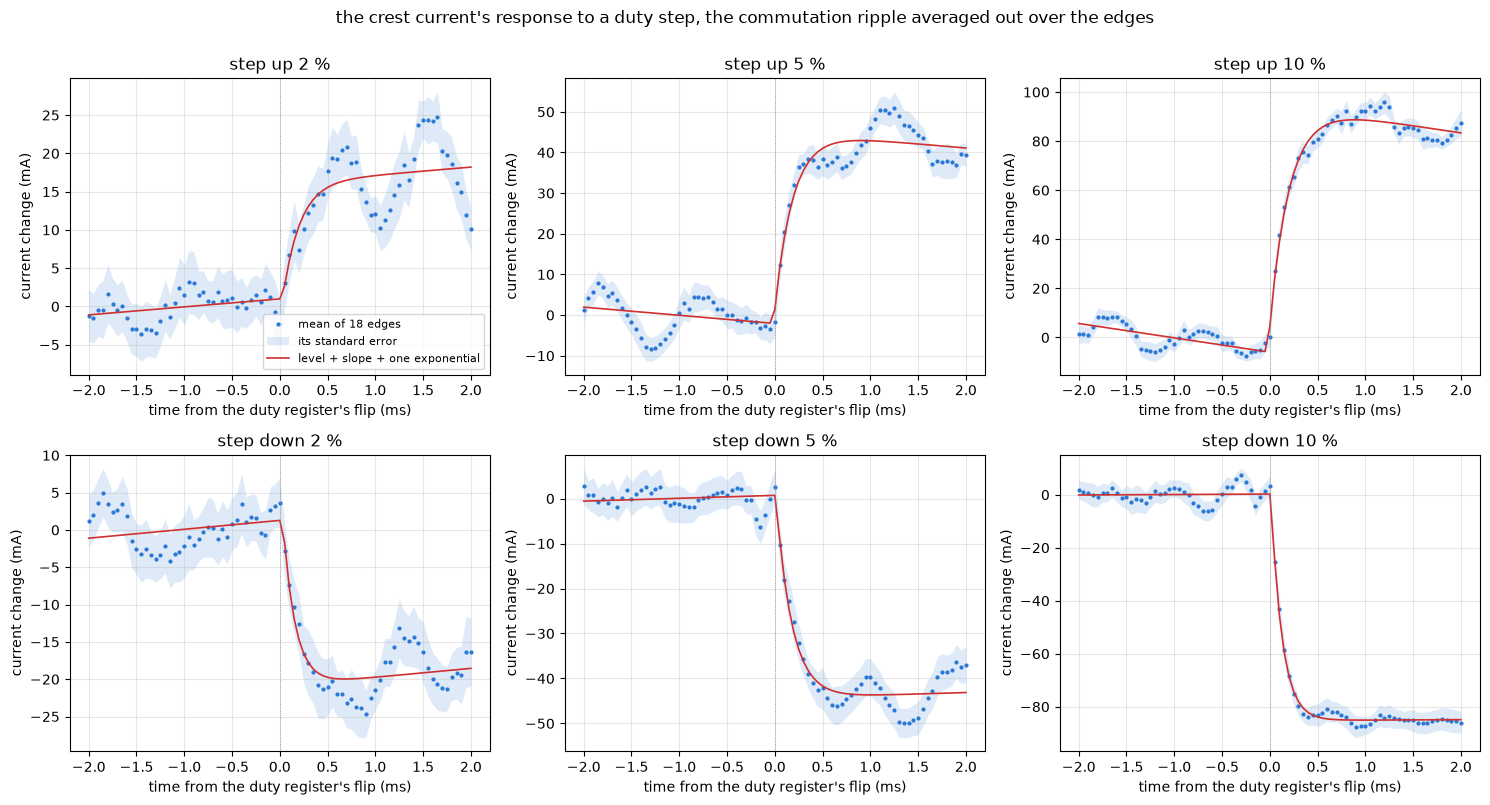

In [54]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row, edge in enumerate(("up", "down")):
    for col, step in enumerate((2, 5, 10)):
        ax, c = axes[row, col], CURVES[f"{edge} {step} %"]
        ms = c["k"] * ROW_US / 1e3      # rows to ms
        err = c["sd"] / np.sqrt(len(c["Y"]))
        ax.plot(ms, c["y"], ".", ms=4, color=BLUE, label="mean of 18 edges")
        ax.fill_between(ms, c["y"] - err, c["y"] + err, color=BLUE,
                        alpha=0.15, lw=0, label="its standard error")
        ax.plot(ms, c["model"], color=RED, lw=1.2,
                label="level + slope + one exponential")
        ax.axvline(0, **figures.EDGE_STYLE)
        figures.label(ax, x="time from the duty register's flip (ms)",
                      y="current change (mA)", title=f"step {edge} {step} %")
        if row == 0 and col == 0:
            ax.legend(loc="lower right", fontsize=8)
fig.suptitle("the crest current's response to a duty step, the commutation "
             "ripple averaged out over the edges", y=1.0)
figures.finish(fig)

The 10 and 5 % groups show a clean first-order rise from the flip row to a flat plateau by about 1 ms. The 2 % groups carry ripple of the step's own size, 3 mA rms on a 15 to 22 mA step.

The delay. The current begins to move in the row the register shows the new duty. The fitted start sits within half a row, 25 us, of the flip row for the 10 % groups and within a row for all. As the stream shows it, the delay from the command's edge is under 50 us, a quarter of the electrical time constant (high, as a bound). The trap note's "the register flips one sample before the current responds" does not describe this image and board.

The electrical time constant. The step up reads 189 to 204 us at 5 and 10 %, against the inductance notebook's 198 (186 to 205) us from locked bursts (high: the small-signal rise on the free, spinning motor is the locked rotor's $L/R$). The step down reads shorter, 116 +/- 16 us at 10 % and 167 +/- 34 at 5 %. The 10 % up and down groups differ by 88 +/- 32 us, 2.8 sigma, a likely finding with its cause open. The candidates are the crest sample's position in a narrowing against a widening window, since the two directions sample the within-period ripple differently, an $L(i)$ that falls as the current falls, although the inductance notebook's ripple $L$ falls 0.13 mH per A, which goes the wrong way, and the slow decay's brake interval carrying the fall. The same steps captured with the DMA burst window, the whole period's waveform instead of one crest sample, or steps of both signs on the RL dummy, with no motor and no $L(i)$, separate them.

The 6-edge groups per base give the spread. The thing to see is that only the 30 % up group stands apart, by about 2 sigma.

In [55]:
per_base = G[~G.per_volt & G.group.str.contains(r"\+")
             & G.group.str.endswith("10 %")]
print(per_base[["group", "n", "tau_e_us", "tau_e_sd_us", "delay_us",
                "di"]].round(0).to_string(index=False))

         group  n  tau_e_us  tau_e_sd_us  delay_us    di
  up 20 + 10 %  6     185.0         30.0     -11.0 113.0
  up 30 + 10 %  6     273.0         27.0     -75.0 100.0
  up 40 + 10 %  6     183.0         51.0      -4.0  94.0
down 20 + 10 %  6     116.0         21.0      19.0 -87.0
down 30 + 10 %  6      93.0         47.0      12.0 -84.0
down 40 + 10 %  6     147.0         28.0       0.0 -86.0


### The plateau per volt and the flat band

Per volt of applied change under A, the plateau the slow fit extrapolates to the edge is the number of record, since at 1 to 2 ms the speed has already risen 5 to 10 % of its change and the fast fit's plateau carries that. The flat band is where the residual's mean sits within its sd after $t_0 + 5\,\tau_e$. The alternatives are shown on the up 10 % group.

In [56]:
for name in PER_V + ["up 10 % per volt", "down 10 % per volt"]:
    r = gi.loc[name]
    print(f"{name}: plateau to the edge {r.plateau_P:.1f} +/- "
          f"{r.plateau_P_sd:.1f} mA/V, at 1 to 2 ms {r.di:.1f} +/- "
          f"{r.di_sd:.1f}, rms {r.rms:.1f}")
for name in MAIN:
    r = gi.loc[name]
    print(f"{name}: flat from {r.flat_from_us:.0f} us, residual after "
          f"{r.resid_after_mean:+.2f} +/- {r.resid_after_sd:.2f} mA")
r = gi.loc["up 10 %"]
total = r.di_with_jump + r.jump         # mA, the jump model's whole step
print(f"up 10 % alternatives: jump {r.jump:.1f} mA of {total:.1f}, rms "
      f"{r.rms_with_jump:.2f} against {r.rms:.2f} mA; second exponential "
      f"{r.di_slow_two:+.1f} mA at {r.tau2_us:.0f} us")
print("second exponential by group (mA):", {
    n: round(gi.loc[n, "di_slow_two"], 1) for n in MAIN})

up all per volt: plateau to the edge 190.3 +/- 3.0 mA/V, at 1 to 2 ms 182.9 +/- 17.5, rms 11.8
down all per volt: plateau to the edge 193.6 +/- 2.6 mA/V, at 1 to 2 ms 195.6 +/- 13.4, rms 9.3
up 10 % per volt: plateau to the edge 194.1 +/- 2.8 mA/V, at 1 to 2 ms 207.0 +/- 8.6, rms 7.5
down 10 % per volt: plateau to the edge 183.6 +/- 1.2 mA/V, at 1 to 2 ms 175.5 +/- 4.8, rms 4.8
up 2 %: flat from 923 us, residual after +0.54 +/- 4.80 mA
up 5 %: flat from 930 us, residual after -1.47 +/- 4.42 mA
up 10 %: flat from 999 us, residual after -0.08 +/- 4.18 mA
down 2 %: flat from 678 us, residual after -0.26 +/- 3.10 mA
down 5 %: flat from 847 us, residual after -0.51 +/- 4.37 mA
down 10 %: flat from 591 us, residual after -0.07 +/- 1.51 mA
up 10 % alternatives: jump 23.7 mA of 100.9, rms 3.63 against 3.65 mA; second exponential -80.3 mA at 15000 us
second exponential by group (mA): {'up 2 %': np.float64(-11.1), 'up 5 %': np.float64(22.7), 'up 10 %': np.float64(-80.3), 'down 2 %': np.float64(8

The plateau is 190 +/- 3 mA per volt up and 194 +/- 3 down, 9 to 9.5 mA per percent of duty on 5 V as the 18-edge groups read it. An instant jump added to the up 10 % model takes about a quarter of the step and moves the residual by under 1 %, not a finding. The second exponential is unresolved, its amplitude changes sign from group to group. After $t_0 + 5\,\tau_e$ the residual's mean sits within its sd for every 18-edge group, so the plateau is flat from about 1 ms after the flip.

### The fall back

Over 25 ms the current falls from the plateau to the settled level as the speed follows. The thing to see is the plateau, then a fall over about 20 ms to a level much closer to the start than the plateau.

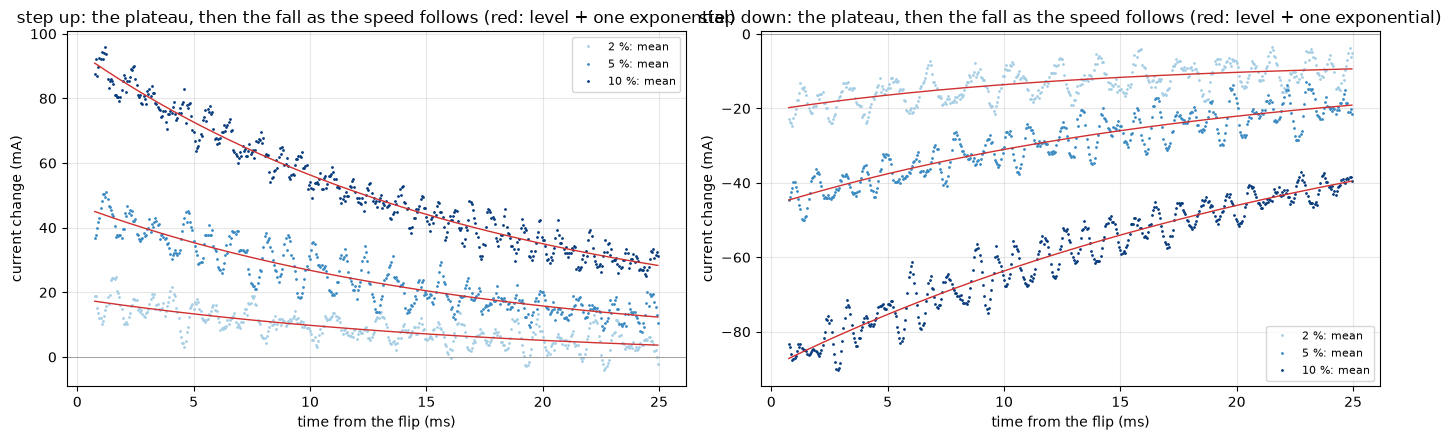

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, edge in zip(axes, ("up", "down")):
    for step, color in zip((2, 5, 10), figures.shades("Blues", 3)):
        c = CURVES[f"{edge} {step} %"]
        ax.plot(c["k_m"] * ROW_US / 1e3, c["y_m"], ".", ms=2, color=color,
                label=f"{step} %: mean")
        ax.plot(c["k_m"] * ROW_US / 1e3, c["model_m"], color=RED, lw=1)
    ax.axhline(0, color=MUTED, lw=0.5)
    figures.label(ax, x="time from the flip (ms)", y="current change (mA)",
                  title=f"step {edge}: the plateau, then the fall as the "
                  "speed follows (red: level + one exponential)")
    ax.legend(fontsize=8)
figures.finish(fig)

In [58]:
for name in MAIN:
    r = gi.loc[name]
    print(f"{name}: plateau {r.plateau_P:+.1f} +/- {r.plateau_P_sd:.1f} mA"
          f" falls to {r.settled_L:+.1f} +/- {r.settled_L_sd:.1f} with "
          f"{r.tau_m_i_ms:.1f} +/- {r.tau_m_i_sd_ms:.1f} ms")
fall = E.loc[E.edge == "up", "tau_i_chain_ms"]   # one per direction
print(f"per chain-direction boxcar model: tau {fall.median():.1f} ms "
      f"median, sd {fall.std():.0f}, n {fall.count()}")

up 2 %: plateau +18.0 +/- 0.6 mA falls to -0.8 +/- 2.5 with 17.4 +/- 2.8 ms
up 5 %: plateau +47.0 +/- 0.7 mA falls to +2.5 +/- 2.0 with 16.6 +/- 1.2 ms
up 10 %: plateau +94.7 +/- 1.4 mA falls to +8.5 +/- 3.3 with 17.0 +/- 0.7 ms
down 2 %: plateau -20.5 +/- 0.5 mA falls to -7.3 +/- 1.5 with 13.6 +/- 3.5 ms
down 5 %: plateau -46.0 +/- 0.8 mA falls to -8.9 +/- 2.5 with 19.3 +/- 2.2 ms
down 10 %: plateau -89.4 +/- 0.6 mA falls to -8.1 +/- 4.6 with 26.2 +/- 2.3 ms
per chain-direction boxcar model: tau 20.2 ms median, sd 11, n 54


The current falls back with 17.0 +/- 0.7 ms after the 10 % step up, and with 26 +/- 2 ms after the 10 % step down. Down against up, the plateau per volt is the same, the rise is faster down and the fall back is slower down. The per-chain boxcar model of the current, which leaves 2.5 ms around each flip out, gives a median of about 20 ms with a wide spread.

## The speed's response to a duty step

### The time constant

One whole-chain model per chain-direction, 54 fits. A table helper first, the mean, sd and se of each column per group.

In [59]:
def agg(df, by, cols):
    # mean, sd and se of `cols` per group of `by`, with the group's size
    rows = []
    for key, g in df.groupby(by, dropna=False):
        key = key if isinstance(key, tuple) else (key,)
        row = dict(zip(by, key))
        row["n"] = len(g)
        for c in cols:
            m, sd, se, _ = wmean(g[c])
            row[c], row[c + "_sd"], row[c + "_se"] = m, sd, se
        rows.append(row)
    return pd.DataFrame(rows)

In [60]:
UP = E[E.edge == "up"].copy()           # one row per chain-direction
TAU_M = wmean(UP.tau_m_chain_ms)        # mean, sd, se, n
print(f"tau_m over {TAU_M[3]} chain-directions: {TAU_M[0]:.2f} ms, sd "
      f"{TAU_M[1]:.2f}, se {TAU_M[2]:.2f}; residual "
      f"{UP.chain_rms_rev_s.min():.1f} to {UP.chain_rms_rev_s.max():.1f} "
      f"rev/s rms")
for by in ("base_pct", "dir", "start_share"):
    t = agg(UP, [by], ["tau_m_chain_ms"])
    z = (t.tau_m_chain_ms - TAU_M[0]) / t.tau_m_chain_ms_se   # vs the pool
    print(f"by {by}: " + ", ".join(
        f"{k:g}: {m:.1f} +/- {sd:.1f} ({zz:+.1f} se)" for k, m, sd, zz in
        zip(t[by], t.tau_m_chain_ms, t.tau_m_chain_ms_sd, z)))

tau_m over 54 chain-directions: 20.86 ms, sd 4.03, se 0.55; residual 1.7 to 11.6 rev/s rms
by base_pct: 20: 20.0 +/- 4.8 (-0.8 se), 30: 22.2 +/- 3.1 (+1.8 se), 40: 20.4 +/- 3.9 (-0.5 se)
by dir: -1: 20.5 +/- 2.4 (-0.7 se), 1: 21.2 +/- 5.2 (+0.3 se)
by start_share: 0: 23.0 +/- 4.5 (+2.0 se), 0.167: 20.3 +/- 2.5 (-1.0 se), 0.333: 19.2 +/- 4.0 (-1.7 se)


Every step-up segment over its base level, by step size, the bases colored, with the chain models as lines and the residuals below. The thing to see is the same first-order rise at every base and the residual's white scatter of a few rev/s, the commutation's unevenness, with no structure left at the flip.

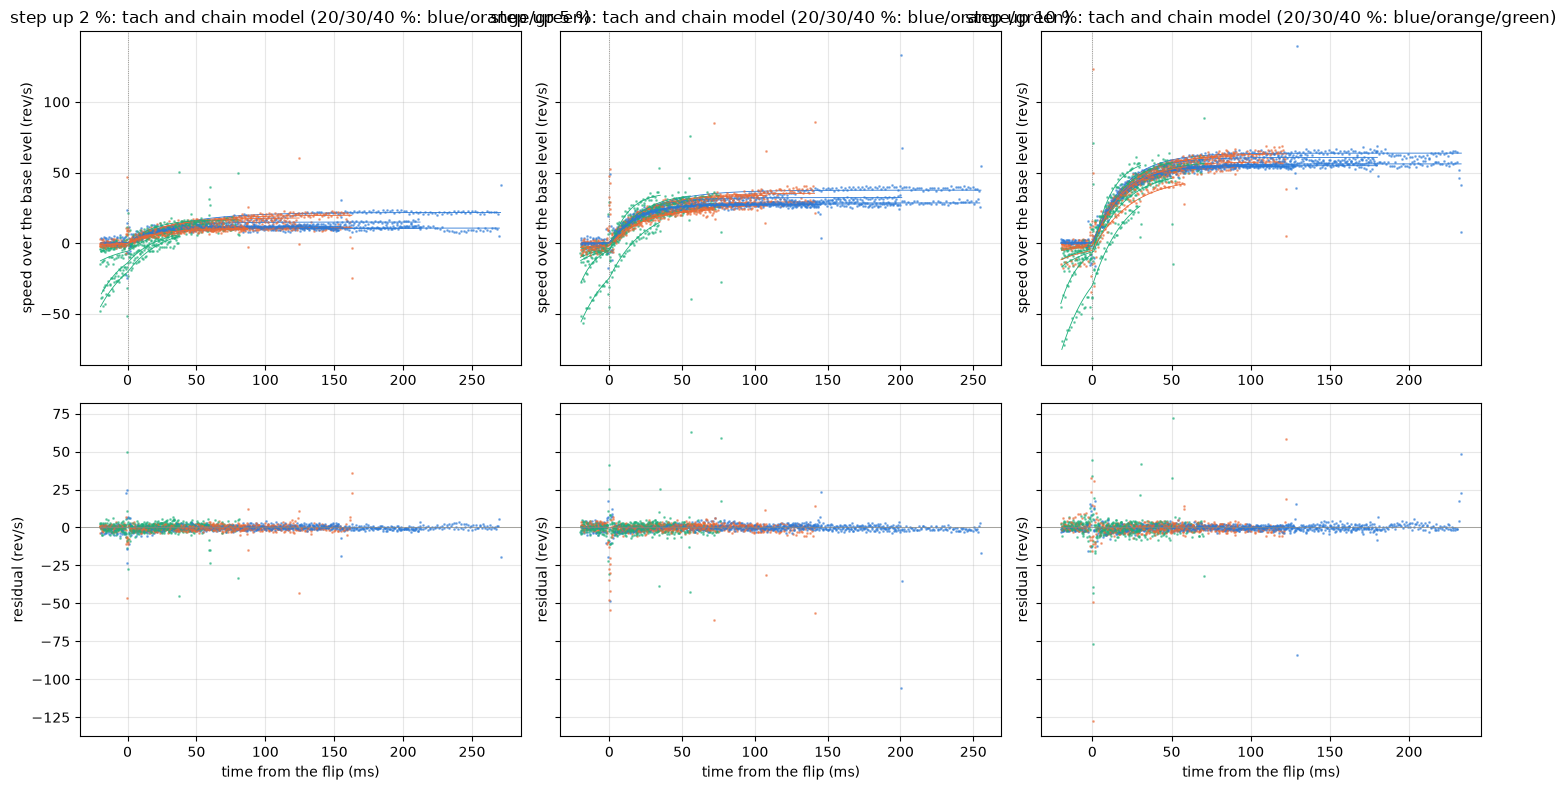

In [61]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharey="row")
BASE_COLOR = {20: BLUE, 30: ORANGE, 40: GREEN}
for col, step in enumerate((2, 5, 10)):
    ax, axr = axes[0, col], axes[1, col]
    for tr in TRACES:
        b, s, ch = tr["base"], tr["s"], tr["chain1"]
        if b["step_pct"] != step:
            continue
        t0 = s.flip_up / FS
        sel = (ch["t"] > t0 - 0.02) & (ch["t"] < s.flip_dn / FS)
        x = (ch["t"][sel] - t0) * 1e3   # ms from the flip
        c, w0 = BASE_COLOR[b["base_pct"]], ch["levels"][0]
        ax.plot(x, ch["y"][sel] - w0, ".", ms=2, color=c, alpha=0.5)
        ax.plot(x, ch["model"][sel] - w0, color=c, lw=0.6)
        axr.plot(x, ch["resid"][sel], ".", ms=2, color=c, alpha=0.5)
    ax.axvline(0, **figures.EDGE_STYLE)
    axr.axhline(0, color=MUTED, lw=0.5)
    figures.label(ax, y="speed over the base level (rev/s)",
                  title=f"step up {step} %: tach and chain model "
                  "(20/30/40 %: blue/orange/green)")
    figures.label(axr, x="time from the flip (ms)", y="residual (rev/s)")
figures.finish(fig)

The mechanical time constant is 20.9 ms, with an sd of 4.0 ms over the 54 chain-directions and a standard error of 0.55 ms. The splits by base and by direction sit within 1.8 of their standard errors of the pool. The start from the guards reads 23.0 +/- 4.5 ms, 2.0 of its standard errors over the pool that contains it, and the inner starts 20.3 and 19.2 ms. The capture ran the three starts in order, so this split is also the time through the capture, as with the gain below, and one capture does not separate the two.

The three-constant alternative gives each segment its own time constant. The chains at 40 % never settle inside a segment, so its numbers are read at 20 and 30 % and under 100 ms.

In [62]:
OK3 = UP[(UP.tau_up3_ms < 100) & (UP.tau_down3_ms < 100)
         & (UP.base_pct < 40)]
for col in ("tau_up3_ms", "tau_down3_ms"):
    m, sd, se, n = wmean(OK3[col])
    print(f"{col}: {m:.1f} +/- {sd:.1f} ms (n {n})")
m, sd, se, n = wmean(OK3[OK3.tau_runup_ms < 150].tau_runup_ms)
print(f"run-up from rest: {m:.1f} +/- {sd:.1f} ms (n {n})")
both = UP[(UP.tau_up3_ms < 100) & (UP.tau_down3_ms < 100)]
m, sd, se, n = wmean(both.tau_down3_ms - both.tau_up3_ms)
print(f"paired back less up, every base under 100 ms: {m:.2f} ms, se "
      f"{se:.2f}, {abs(m) / se:.1f} sigma (n {n})")

tau_up3_ms: 21.3 +/- 8.6 ms (n 36)
tau_down3_ms: 18.7 +/- 3.5 ms (n 36)
run-up from rest: 26.3 +/- 12.1 ms (n 33)
paired back less up, every base under 100 ms: -2.89 ms, se 2.14, 1.4 sigma (n 52)


The step up reads 21.3 +/- 8.6 ms and the step back 18.7 +/- 3.5. Paired by chain, the step back less the step up is -2.9 +/- 2.1 ms (se) over the 52 pairs under 100 ms at every base, 1.4 sigma, not a finding. The run-up from rest reads 26 +/- 12 ms, slower than the small steps. The base segment opens from rest with the take-up and the breakaway in it and its first 15 ms out, which likely accounts for it.

### The delay

The chain model's delay at the flips.

In [63]:
delay = UP.w_delay_chain_ms
print(f"fitted delay: {int((delay < 1e-6).sum())} of {len(delay)} at the "
      f"bound 0, median {delay.median():.2f} ms, 90th percentile "
      f"{delay.quantile(0.9):.2f}, largest {delay.max():.2f}")

fitted delay: 31 of 54 at the bound 0, median 0.00 ms, 90th percentile 1.01, largest 1.98


The tach reads one speed per cycle of 1 to 2 ms, so this is a bound and not a value. The speed's delay after the duty edge is under 1 ms (high, as a bound).

### The gain

The settled speed change per percent of duty on 5 V comes from the chain model's asymptotes, `k_w_chain_rev_s_per_pct`. Per volt of applied change it is formed three ways, under A with the crest volts before the edge, under A with them after it, and under B with the brake term's settled change.

In [64]:
def dv_b_settled(r):
    # B's settled change: A's less the brake term's change at the
    # settled currents before and after the edge
    D0 = (r.base_pct if r.edge == "up" else r.base_pct + r.step_pct) / 100
    D1 = D0 + r.d_duty_pct / 100
    lag = EDGE_TICKS / (2 * 1200)       # the on-share's shortfall
    sh0, sh1 = D0 - lag, D1 - lag
    i0 = r.i0_ma * 1e-3
    i1 = i0 + r.di_ss_chain_ma * 1e-3
    return r.dv_a_v - R_BRK * ((1 - sh1) * i1 - (1 - sh0) * i0)


E["k_w_chain_per_v_a"] = E.dw_chain_rev_s / E.dv_a_v
E["dv_b_ss_v"] = [dv_b_settled(r) for _, r in E.iterrows()]
E["k_w_chain_per_v_b"] = E.dw_chain_rev_s / E.dv_b_ss_v
E["k_w_chain_per_v_a_after"] = E.dw_chain_rev_s / E.dv_a_after_v
GAIN_COLS = ["k_w_chain_rev_s_per_pct", "k_w_chain_per_v_a",
             "k_w_chain_per_v_b", "k_w_chain_per_v_a_after",
             "k_i_ss_chain_ma_per_pct", "travel_counts", "von_step_mv",
             "r_takeback_ohm", "dw_ss_pot_rev_s", "dw_chain_rev_s"]
BIG = E[E.step_pct >= 5]                # the 5 and 10 % steps, 72 edges
K_EDGE = agg(E, ["edge"], GAIN_COLS)
K_STEP = agg(E, ["edge", "step_pct"], GAIN_COLS)

In [65]:
def pm_str(x):
    # "mean +/- sd" of a column
    m, sd, _, _ = wmean(x)
    return f"{m:.2f} +/- {sd:.2f}"


k = "k_w_chain_rev_s_per_pct"
print(f"5 and 10 % steps: {pm_str(BIG[k])} rev/s per % (n {len(BIG)}); "
      f"up {pm_str(BIG[BIG.edge == 'up'][k])}, down "
      f"{pm_str(BIG[BIG.edge == 'down'][k])}")
print(K_STEP[["edge", "step_pct", "n", k, k + "_sd", "von_step_mv"]]
      .round(2).to_string(index=False))
for by in ("base_pct", "start_share", "dir"):
    t = agg(BIG, [by], [k])
    print(f"by {by} (5 and 10 %): " + ", ".join(
        f"{v:g}: {m:.2f} +/- {sd:.2f}" for v, m, sd in
        zip(t[by], t[k], t[k + "_sd"])))
t = agg(E, ["edge", "dir"], [k])
print("by edge and direction, every step: " + ", ".join(
    f"{e} {d:+d}: {m:.1f} +/- {sd:.1f}" for e, d, m, sd in
    zip(t.edge, t.dir, t[k], t[k + "_sd"])))

5 and 10 % steps: 5.64 +/- 0.77 rev/s per % (n 72); up 5.82 +/- 0.73, down 5.47 +/- 0.77
edge  step_pct  n  k_w_chain_rev_s_per_pct  k_w_chain_rev_s_per_pct_sd  von_step_mv
down         2 18                     6.21                        1.23        14.98
down         5 18                     5.60                        0.85        35.65
down        10 18                     5.33                        0.68        68.28
  up         2 18                     6.76                        1.86       -13.49
  up         5 18                     5.99                        0.86       -33.98
  up        10 18                     5.65                        0.54       -64.77
by base_pct (5 and 10 %): 20: 5.70 +/- 0.49, 30: 5.75 +/- 0.58, 40: 5.47 +/- 1.09
by start_share (5 and 10 %): 0: 5.79 +/- 0.62, 0.167: 5.71 +/- 0.57, 0.333: 5.43 +/- 1.01
by dir (5 and 10 %): -1: 5.57 +/- 0.53, 1: 5.72 +/- 0.95
by edge and direction, every step: down -1: 5.9 +/- 1.0, down +1: 5.5 +/- 0.9, up -1: 5.5 +/- 

In [66]:
PER_V_A = BIG.dw_chain_rev_s / BIG.dv_a_v          # crest volts before
PER_V_AFTER = BIG.dw_chain_rev_s / BIG.dv_a_after_v    # and after
print(f"per volt under A: {pm_str(PER_V_A)} rev/s per V with the crest "
      f"volts before the edge, {pm_str(PER_V_AFTER)} with them after it")
up_k = K_EDGE.set_index("edge").loc["up"]
B_OVER_A = up_k.k_w_chain_per_v_b / up_k.k_w_chain_per_v_a
print(f"B over A per volt, steps up: {B_OVER_A:.4f}")
print("crest volts' move on the step (mV), by edge and step: " + ", ".join(
    f"{e} {s}: {v:+.0f}" for e, s, v in
    zip(K_STEP.edge, K_STEP.step_pct, K_STEP.von_step_mv)))

per volt under A: 115.65 +/- 15.67 rev/s per V with the crest volts before the edge, 121.21 +/- 16.30 with them after it
B over A per volt, steps up: 0.9938
crest volts' move on the step (mV), by edge and step: down 2: +15, down 5: +36, down 10: +68, up 2: -13, up 5: -34, up 10: -65


The gain is 5.64 +/- 0.77 rev/s per % over the 72 edges of 5 and 10 %, up 5.82 +/- 0.73 and down 5.47 +/- 0.77. The 2 % steps are noisier and not different. Per volt of applied change it is 116 +/- 16 rev/s per V under A with the crest volts before the edge and 121 +/- 16 with them after it. The rail sags about 65 mV on a +10 % step and rises as much on the step down. B sits within 0.6 % of A.

Whether the gain depends on the base, the start or the time through the capture, a line through the 72 gains on each.

In [67]:
SLOPES = {}
minutes = (BIG.t_start - BIG.t_start.min()) / 60
for name, x in (("base_pct", BIG.base_pct), ("start_share",
                BIG.start_share), ("minutes", minutes)):
    f = line(x, BIG.k_w_chain_rev_s_per_pct)
    SLOPES[name] = f
    print(f"gain on {name}: slope {f['slope']:.4f} +/- {f['slope_se']:.4f}"
          f" ({abs(f['slope']) / f['slope_se']:.1f} sigma), n {f['n']}")
pair = E.pivot_table(index=["k", "dir"], columns="edge",
                     values="dw_chain_rev_s")
DOWN_OVER_UP = -pair["down"] / pair["up"]   # paired by chain-direction
m, sd, se, n = wmean(DOWN_OVER_UP)
print(f"speed change back over change up: {m:.3f} sd {sd:.3f} se {se:.3f}"
      f" ({abs(1 - m) / se:.1f} sigma from 1), n {n}")

gain on base_pct: slope -0.0115 +/- 0.0110 (1.0 sigma), n 72
gain on start_share: slope -1.0981 +/- 0.6555 (1.7 sigma), n 72
gain on minutes: slope -0.0182 +/- 0.0089 (2.0 sigma), n 72
speed change back over change up: 0.961 sd 0.218 se 0.030 (1.3 sigma from 1), n 54


The gain does not move with the base, -0.012 +/- 0.011 rev/s per % per % of base. On the start and on time it falls by 1.7 and 2.0 sigma. The capture runs the three starts in order, so the two are the same drift seen twice, about -0.4 rev/s per % over the capture, not separable here and not called. By direction the signs are mixed and inside the spread. The speed change back is 0.961 +/- 0.218 of the change up, 1.3 sigma from 1 by its se, not a finding.

The per-edge speed check on its own. The thing to see is where it fails, on the bases that are still rising.

In [68]:
neg = E[E.k_w_rev_s_per_pct < 0].groupby(["base_pct", "start_share"]).size()
print("per-edge fit, negative gains by base and start:",
      {f"{b} % at {s:.3f}": int(n) for (b, s), n in neg.items()})
settled_bases = BIG[(BIG.base_pct == 20) & (BIG.start_share == 0)]
ratio = settled_bases.k_w_rev_s_per_pct / settled_bases[
    "k_w_chain_rev_s_per_pct"]
print(f"20 % bases from the guards: per-edge over chain gain "
      f"{ratio.median():.3f} median, {ratio.min():.2f} to {ratio.max():.2f}"
      f" (n {len(ratio)})")

per-edge fit, negative gains by base and start: {'30 % at 0.333': 2, '40 % at 0.167': 1, '40 % at 0.333': 5}
20 % bases from the guards: per-edge over chain gain 1.012 median, 0.68 to 1.09 (n 8)


The velocity plant at a glance. The gain against the base by start and direction, $\tau_m$ against the base by direction with the pool's mean dashed, and the delay's histogram. The thing to see is one gain and one time constant across every operating point, and a delay piled at zero.

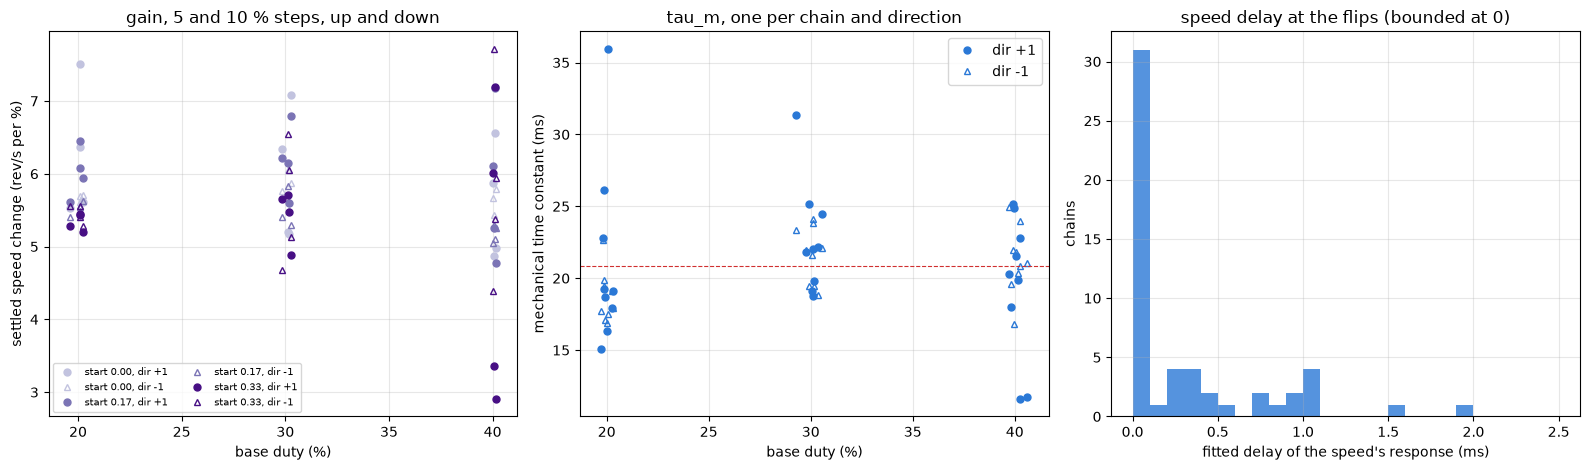

In [69]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
ax = axes[0]
for start, color in zip((0.0, 1 / 6, 1 / 3), figures.shades("Purples", 3)):
    for d in (1, -1):
        s = E[(np.isclose(E.start_share, start, atol=0.01)) & (E.dir == d)
              & (E.step_pct >= 5)]
        jitter = np.random.default_rng(1).normal(0, 0.3, len(s))
        ax.plot(s.base_pct + jitter, s.k_w_chain_rev_s_per_pct,
                **figures.direction_style(d, color), ms=5,
                label=f"start {start:.2f}, dir {d:+d}")
ax.legend(fontsize=7, ncol=2)
figures.label(ax, x="base duty (%)", y="settled speed change (rev/s per %)",
              title="gain, 5 and 10 % steps, up and down")
ax = axes[1]
for d in (1, -1):
    s = UP[UP.dir == d]
    jitter = np.random.default_rng(2).normal(0, 0.3, len(s))
    ax.plot(s.base_pct + jitter, s.tau_m_chain_ms,
            **figures.direction_style(d, BLUE), ms=5, label=f"dir {d:+d}")
ax.axhline(UP.tau_m_chain_ms.mean(), **figures.HIGHLIGHT_STYLE)
ax.legend()
figures.label(ax, x="base duty (%)", y="mechanical time constant (ms)",
              title="tau_m, one per chain and direction")
axes[2].hist(UP.w_delay_chain_ms, bins=np.arange(0, 2.6, 0.1), color=BLUE,
             alpha=0.8)
figures.label(axes[2], x="fitted delay of the speed's response (ms)",
              y="chains", title="speed delay at the flips (bounded at 0)")
figures.finish(fig)

### Travel and the pot

The pot counts each stepped segment traveled, as the runway cut it, and the pot's speed against the tach's over the settled windows. The travel is signed by the direction, so its size is shown here.

In [70]:
E["travel_abs_counts"] = E.travel_counts.abs()   # size, either direction
size = E.groupby(["base_pct", "start_share"])["travel_abs_counts"].agg(
    ["min", "max"]).round(0)
print("stepped segment's travel, pot counts, by base and start:")
print(size.to_string())
SETTLED = L[(L.settle_pct.abs() < SETTLE_PCT_MAX)
            & (L.w_tach_cycles >= SETTLED_CYCLES_MIN)]
POT_OVER_TACH = SETTLED.w_pot_rev_s / SETTLED.w_tach_rev_s
m, sd, _, n = wmean(POT_OVER_TACH)
print(f"pot speed over tach over {n} settled windows: {m:.3f} +/- {sd:.3f};"
      f" {COUNTS_PER_MOTOR_REV * m:.1f} counts per motor turn against "
      f"{COUNTS_PER_MOTOR_REV:.2f} nominal")

stepped segment's travel, pot counts, by base and start:
                        min    max
base_pct start_share              
20       0.000        442.0  739.0
         0.167        337.0  549.0
         0.333        264.0  368.0
30       0.000        418.0  549.0
         0.167        298.0  439.0
         0.333        191.0  291.0
40       0.000        341.0  397.0
         0.167        235.0  284.0
         0.333        129.0  189.0
pot speed over tach over 101 settled windows: 0.970 +/- 0.136; 22.4 counts per motor turn against 23.14 nominal


A stepped segment travels a few hundred counts, the most at 20 % from the guards and the least at 40 % from the inner start. The pot reads the settled speed 3 % under the tach through its nominal slope, 0.97 +/- 0.13, so 22.4 counts per motor turn against 23.14 nominal. The 40 ms windows give the pot's speed a spread of 13 %, so the pot-table notebook, not this one, grades the slope.

## The levels and the EMF balance

A level is settled when its speed changes by under 2.5 % across its window and the tach holds at least 20 cycles in it. The settled levels per duty and direction. The thing to see is the direction split and the EMF balance's offset between the two constructions.

In [71]:
LV_COLS = ["i_ma", "w_tach_rev_s", "w_pot_rev_s", "v_on_v", "v_a_v",
           "v_b_v", "x_a_mv", "x_b_mv", "trough_over_zero_counts",
           "settle_pct"]
V = agg(SETTLED.assign(duty_pct=SETTLED.duty_pct.round(0)),
        ["duty_pct", "dir"], LV_COLS)
print(f"settled levels: {len(SETTLED)} of {len(L)}")
print(V[["duty_pct", "dir", "n", "i_ma", "i_ma_sd", "w_tach_rev_s",
         "w_tach_rev_s_sd", "v_on_v", "x_a_mv", "x_b_mv"]].round(1)
      .to_string(index=False))
for dp in (20, 30, 40):
    s = SETTLED[SETTLED.duty_pct.round(0) == dp]
    print(f"{dp} % pooled (n {len(s)}): {pm_str(s.w_tach_rev_s)} rev/s, "
          f"{pm_str(s.i_ma)} mA, X_A {pm_str(s.x_a_mv)} mV, X_B "
          f"{pm_str(s.x_b_mv)} mV")

settled levels: 101 of 162
 duty_pct  dir  n  i_ma  i_ma_sd  w_tach_rev_s  w_tach_rev_s_sd  v_on_v  x_a_mv  x_b_mv
     20.0   -1  2  81.3      1.0          86.9              0.8     4.9     4.9   -67.0
     20.0    1  2  82.9      0.9          85.6              0.4     4.9     7.8   -64.6
     22.0   -1  3  85.7      2.0          97.2              1.1     4.9     9.1   -63.4
     22.0    1  3  86.7      2.0          97.0              1.1     4.9     6.4   -66.4
     25.0   -1  2  88.4      1.1         114.3              1.0     4.9    18.3   -53.9
     25.0    1  3  90.8      1.8         113.1              1.4     4.9    17.8   -55.0
     30.0   -1 18  96.8      1.5         141.8              1.1     4.9    24.8   -47.8
     30.0    1 19 102.6      5.7         137.5              3.6     4.9    31.1   -42.7
     32.0   -1  3 100.0      1.5         152.4              1.3     4.9    30.7   -42.0
     32.0    1  3 100.2      1.9         152.2              1.8     4.9    32.1   -40.6
     

The speed against the duty over the settled levels, and the ladder notebook's steady 5 V rungs beside it from its result file.

In [72]:
SPEED_LINE = line(SETTLED.duty_pct, SETTLED.w_tach_rev_s)
print(f"speed on duty: {SPEED_LINE['slope']:.3f} +/- "
      f"{SPEED_LINE['slope_se']:.3f} rev/s per %, intercept "
      f"{SPEED_LINE['intercept']:.1f} rev/s, rms {SPEED_LINE['rms']:.2f}")
rungs = LADDER["rungs"]
for dp in (20, 30, 40):
    got = [rungs.get(f"5 V {dp} % {d:+d}") for d in (1, -1)]
    print(f"ladder 5 V {dp} %: " + ", ".join(
        f"{d:+d} {r['speed_rev_s']['value']:.1f} rev/s, "
        f"{r['i_crest_ma']['value']:.1f} mA" for d, r in zip((1, -1), got)
        if r is not None))

speed on duty: 5.412 +/- 0.059 rev/s per %, intercept -21.9 rev/s, rms 4.25
ladder 5 V 20 %: -1 82.1 rev/s, 90.7 mA
ladder 5 V 30 %: +1 136.3 rev/s, 105.4 mA, -1 140.1 rev/s, 100.8 mA
ladder 5 V 40 %: +1 192.7 rev/s, 117.2 mA, -1 198.2 rev/s, 111.4 mA


The settled levels give 5.41 +/- 0.06 rev/s per % with an intercept of -21.9 rev/s, the floor's share of the line. At 20 % the pooled level is 86.3 +/- 0.9 rev/s at 82 mA (four settled levels), at 30 % 139.6 +/- 3.4 rev/s at 100 mA, at 40 % 196.7 +/- 6.1 rev/s at 110 mA, close to the ladder's rungs. The direction split is systematic where both directions hold many levels. At 30 and 40 % direction -1 runs 2 to 3 % faster and draws 5 to 6 % less than +1, as the ladder saw at 30 and 40 %.

The EMF balance $X = V - R\,I - K_e\,\omega$ of the settled levels against the tach speed, under A and under B. The thing to see is the same rising line under both, offset by about 70 mV.

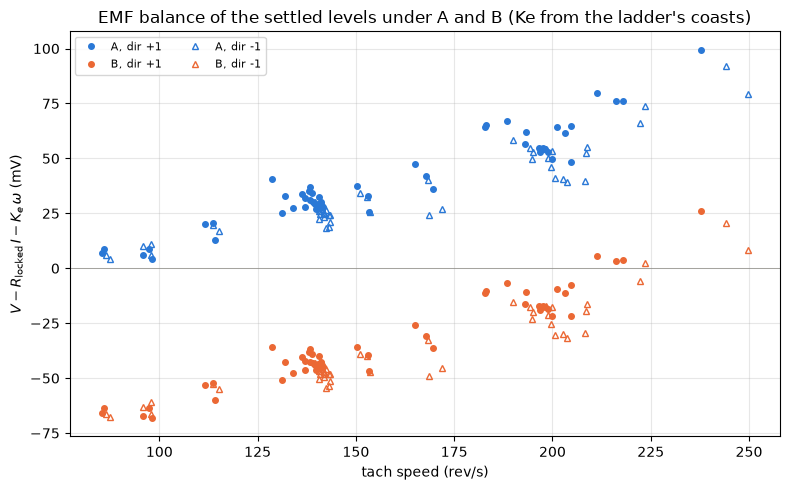

In [73]:
fig, ax = plt.subplots(figsize=(8, 5))
for d in (1, -1):
    s = SETTLED[SETTLED.dir == d]
    ax.plot(s.w_tach_rev_s, s.x_a_mv, **figures.direction_style(d, BLUE),
            ms=4, label=f"A, dir {d:+d}")
    ax.plot(s.w_tach_rev_s, s.x_b_mv, **figures.direction_style(d, ORANGE),
            ms=4, label=f"B, dir {d:+d}")
ax.axhline(0, color=MUTED, lw=0.5)
ax.legend(fontsize=8, ncol=2)
figures.label(ax, x="tach speed (rev/s)",
              y=r"$V - R_\mathrm{locked}\,I - K_e\,\omega$ (mV)",
              title="EMF balance of the settled levels under A and B "
              "(Ke from the ladder's coasts)")
figures.finish(fig)

Under A the balance sits at +6, +28 and +53 mV at 20, 30 and 40 %, 0.8 to 4 % of $K_e\,\omega$. Under B it sits at -66, -45 and -19 mV. The two constructions move the balance by about 70 mV and the step responses by nothing, so this notebook carries both and the construction stays open, as in the ladder notebook.

### Run-in through the capture

The base levels against the chain's host time, 26 minutes at 20 %.

In [74]:
L["minutes"] = (L.t_start - L.t_start.min()) / 60
RUN_IN = {}
for dp in (20, 30):
    sub = L[(L.duty_pct.round(0) == dp) & (L.level == "base")
            & (L.w_tach_cycles >= 15) & (L.settle_pct.abs() < 5)]
    fw = line(sub.minutes, sub.w_tach_rev_s)
    fi = line(sub.minutes, sub.i_ma)
    RUN_IN[dp] = (fw, fi)
    print(f"{dp} % base, n {len(sub)} over "
          f"{sub.minutes.max() - sub.minutes.min():.1f} min: speed "
          f"{fw['slope'] * 10:+.2f} +/- {fw['slope_se'] * 10:.2f} rev/s per "
          f"10 min ({abs(fw['slope'] / fw['slope_se']):.1f} sigma), current "
          f"{fi['slope'] * 10:+.2f} +/- {fi['slope_se'] * 10:.2f} mA per "
          f"10 min")

20 % base, n 17 over 26.1 min: speed +1.42 +/- 0.75 rev/s per 10 min (1.9 sigma), current -2.32 +/- 1.20 mA per 10 min
30 % base, n 16 over 24.4 min: speed +0.51 +/- 1.25 rev/s per 10 min (0.4 sigma), current -1.15 +/- 1.81 mA per 10 min


At 20 % the speed rises 1.4 +/- 0.75 rev/s and the current falls 2.3 +/- 1.2 mA per 10 minutes, 1.9 sigma, not a finding on this capture alone. It has the sign of the ladder's open-to-close drift through the same sitting.

## The plant stage 5 reads

### The current loop

The resistance the step reads, $\Delta V / \Delta i$, from the ensembles and per edge. Under B the brake term's change at the plateau, with the current up and the speed not yet, comes off the volts. The inductance follows as $\tau_e\,R$, with the locked $R$ and with the step's own.

In [75]:
def r_step_b(r):
    # an ensemble group's dV_B / di at the plateau, ohm
    if r.per_volt or not np.isfinite(r.di):
        return np.nan
    parts = r.group.split()
    sub = E[E.edge == parts[0]]
    if "+" in parts:                    # a per-base group
        sub = sub[(sub.base_pct == int(parts[1]))
                  & (sub.step_pct == int(parts[3]))]
    else:
        sub = sub[sub.step_pct == int(parts[1])]
    D0 = ((sub.base_pct if r.group.startswith("up")
           else sub.base_pct + sub.step_pct) / 100).mean()
    dD = sub.d_duty_pct.mean() / 100
    lag = EDGE_TICKS / 2400
    i0 = sub.i0_ma.mean() * 1e-3
    di = r.di * 1e-3
    dv_b = r.mean_dv_a_v - R_BRK * ((1 - (D0 + dD - lag)) * (i0 + di)
                                    - (1 - (D0 - lag)) * i0)
    return dv_b / di


G["r_step_a_ohm"] = G.mean_dv_a_v / (G.di * 1e-3)
G["r_step_a_plateau_ohm"] = G.mean_dv_a_v / (G.plateau_P * 1e-3)
G["r_step_b_ohm"] = [r_step_b(r) for _, r in G.iterrows()]
G["l_step_a_mh"] = G.tau_e_us * 1e-6 * G.r_step_a_ohm * 1e3
G["l_step_locked_r_mh"] = G.tau_e_us * 1e-6 * R_LOCKED * 1e3
gi = G.set_index("group")

In [76]:
KEEP = ["dv_a_after_v", "di_ss_chain_ma", "dw_chain_rev_s",
        "di_jump_chain_ma"]
PM = P.merge(E[["k", "dir", "edge"] + KEEP], on=["k", "dir", "edge"])
PM["r_step_a_after_ohm"] = PM.dv_a_after_v / (PM.di_e_ma * 1e-3)
PM["r_takeback_ens_ohm"] = KE_LADDER * PM.dw_chain_rev_s / (
    (PM.di_e_ma - PM.di_ss_chain_ma) * 1e-3)
P10 = PM[PM.step_pct == 10]             # the 36 edges of 10 %
print(f"dV_A/di per edge, 10 %: {pm_str(P10.r_step_a_ohm)} ohm (n "
      f"{len(P10)}); up {pm_str(P10[P10.edge == 'up'].r_step_a_ohm)}, "
      f"down {pm_str(P10[P10.edge == 'down'].r_step_a_ohm)}")
print(f"with the crest volts after the edge: "
      f"{pm_str(P10.r_step_a_after_ohm)} ohm")
for name in ("up 10 %", "down 10 %"):
    r = gi.loc[name]
    print(f"ensemble {name}: A {r.r_step_a_ohm:.3f}, B {r.r_step_b_ohm:.3f}"
          f" ohm, B over A {r.r_step_b_ohm / r.r_step_a_ohm:.3f}")
print(f"take-back route, chain jumps, 5 and 10 %: "
      f"{pm_str(BIG.r_takeback_ohm)} ohm; ensemble plateaus, 10 %: "
      f"{pm_str(P10.r_takeback_ens_ohm)} ohm")
print(f"locked laps {R_LOCKED:.3f} ohm; stop chains {R_STOP_B:.2f} to "
      f"{R_STOP_A:.2f}")

dV_A/di per edge, 10 %: 5.35 +/- 0.85 ohm (n 72); up 4.95 +/- 0.84, down 5.76 +/- 0.65
with the crest volts after the edge: 5.11 +/- 0.81 ohm
ensemble up 10 %: A 4.830, B 4.678 ohm, B over A 0.969
ensemble down 10 %: A 5.697, B 5.524 ohm, B over A 0.970
take-back route, chain jumps, 5 and 10 %: 5.08 +/- 0.60 ohm; ensemble plateaus, 10 %: 5.03 +/- 0.95 ohm
locked laps 4.219 ohm; stop chains 4.26 to 4.38


The resistance per edge against the base, with the locked laps dashed, and the electrical time constant per 6-edge group with the inductance notebook's band. The thing to see is nearly every edge reading over the locked $R$, and $\tau_e$ up near the inductance notebook's band while $\tau_e$ down sits under it.

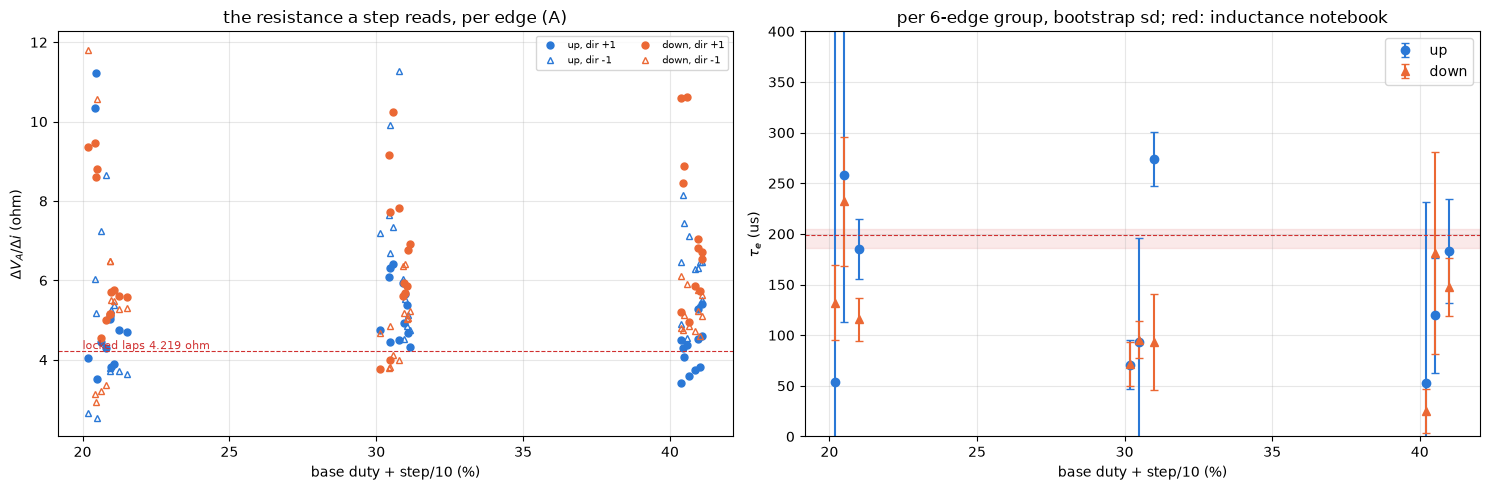

In [77]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
for edge, color in (("up", BLUE), ("down", ORANGE)):
    s = PM[(PM.edge == edge) & (PM.step_pct >= 5)]
    for d in (1, -1):
        ss = s[s.dir == d]
        jitter = np.random.default_rng(3).normal(0, 0.15, len(ss))
        ax.plot(ss.base_pct + ss.step_pct / 10 + jitter, ss.r_step_a_ohm,
                **figures.direction_style(d, color), ms=5,
                label=f"{edge}, dir {d:+d}")
ax.axhline(R_LOCKED, **figures.HIGHLIGHT_STYLE)
ax.text(20, R_LOCKED + 0.05, f"locked laps {R_LOCKED:.3f} ohm", color=RED,
        fontsize=8)
ax.legend(fontsize=7, ncol=2)
figures.label(ax, x="base duty + step/10 (%)", y=r"$\Delta V_A / \Delta i$"
              " (ohm)", title="the resistance a step reads, per edge (A)")
ax = axes[1]
g6 = G[~G.per_volt & G.group.str.contains(r"\+")]
for edge, color in (("up", BLUE), ("down", ORANGE)):
    s = g6[g6.group.str.startswith(edge)]
    x = [int(n.split()[1]) + int(n.split()[3]) / 10 for n in s.group]
    ax.errorbar(x, s.tau_e_us, yerr=s.tau_e_sd_us, capsize=3, color=color,
                fmt="o" if edge == "up" else "^", label=edge)
ax.axhline(TAU_E_US, **figures.HIGHLIGHT_STYLE)
ax.axhspan(TAU_E_LO, TAU_E_HI, color=RED, alpha=0.1)
ax.set_ylim(0, 400)
ax.legend()
figures.label(ax, x="base duty + step/10 (%)", y=r"$\tau_e$ (us)",
              title="per 6-edge group, bootstrap sd; red: inductance "
              "notebook")
figures.finish(fig)

The resistance a small step reads is 5.35 +/- 0.85 ohm under A over the 36 edges of 10 %, up 4.95 +/- 0.84 and down 5.76 +/- 0.65. Each edge enters twice, once with the 18-edge group's shape and once with its 6-edge base group's, so the count above is 72. B reads 3 % lower. The route with no volts in it, $K_e\,\Delta\omega / (\Delta i_\mathrm{jump} - \Delta i_\mathrm{settled})$, gives 5.08 +/- 0.60 ohm from the chain jumps and 5.03 +/- 0.95 from the ensemble plateaus. Against the locked laps' 4.219 ohm these are 15 to 35 % higher. Both routes read the same thing. The current's first change on a small step is about 20 % smaller than the locked $R$ predicts, or the back-EMF takes back 20 % more than $K_e$ predicts.

This is an open discrepancy and not a value of $R$. The candidates are four.

- (a) A current-path term the crest sample does not follow on a 1 ms scale. The inductance notebook's $R$ falls 6 to 10 % as its fit window lengthens and its early $R$ is 4.58 ohm, the same direction at half the size. Leading.
- (b) A $K_e$ under drive above the coast's. The ladder's brush-drop slope of 0.33 mV per rev/s under A is 4.5 % of $K_e$. It would move the take-back route to about 5.3 ohm and leave the volts route untouched, so it explains one route only.
- (c) The applied volts' step over-estimated. The rail's sag is 5 % of the gap, as the after-edge read shows, and the edge lags change nothing on a step. A current-dependent on-window loss is left.
- (d) The plateau taken before the speed has moved. At 1 to 2 ms the speed has risen 5 to 10 % of its change. The slow fit's plateau at the edge corrects for that and reads lower still, 95 against 101 mA on the up 10 % group.

The same small steps captured through the DMA burst window, period means in place of crest samples, on the free motor and on the RL dummy where $R$ is known, separate them. For stage 5 the loop's plant gain is the measured 190 mA per volt, whatever the cause.

### The plant in one place

The two loops' plants in the units the firmware works in, with their spreads.

In [78]:
up10, dn10 = gi.loc["up 10 %"], gi.loc["down 10 %"]
upv, dnv = gi.loc["up all per volt"], gi.loc["down all per volt"]
print("current loop, duty -> crest current")
print(f"  tau_e up {up10.tau_e_us:.0f} +/- {up10.tau_e_sd_us:.0f} us, "
      f"down {dn10.tau_e_us:.0f} +/- {dn10.tau_e_sd_us:.0f} us (10 % steps)")
print(f"  delay under {ROW_US:.0f} us, a bound (the flip row)")
print(f"  plateau {upv.plateau_P:.0f} +/- {upv.plateau_P_sd:.0f} mA per V "
      f"up, {dnv.plateau_P:.0f} +/- {dnv.plateau_P_sd:.0f} down")
print(f"  settled change {pm_str(BIG.k_i_ss_chain_ma_per_pct)} mA per %")
print(f"  L = tau_e x R_locked: {up10.tau_e_us * 1e-3 * R_LOCKED:.2f} mH "
      f"up, {dn10.tau_e_us * 1e-3 * R_LOCKED:.2f} down; with the step's R"
      f" {up10.l_step_a_mh:.2f} up")
print("velocity loop, duty -> motor speed")
print(f"  tau_m {TAU_M[0]:.1f} ms, sd {TAU_M[1]:.1f}, se {TAU_M[2]:.2f}")
print(f"  gain {pm_str(BIG.k_w_chain_rev_s_per_pct)} rev/s per % on 5 V, "
      f"{pm_str(BIG.dw_chain_rev_s / BIG.dv_a_v)} rev/s per V under A")
print(f"  delay under {UP.w_delay_chain_ms.quantile(0.9):.1f} ms, a bound "
      f"(the tach's cycle)")
print(f"  current's own fall {up10.tau_m_i_ms:.1f} +/- "
      f"{up10.tau_m_i_sd_ms:.1f} ms after the 10 % step up")

current loop, duty -> crest current
  tau_e up 204 +/- 28 us, down 116 +/- 16 us (10 % steps)
  delay under 50 us, a bound (the flip row)
  plateau 190 +/- 3 mA per V up, 194 +/- 3 down
  settled change 1.08 +/- 0.72 mA per %
  L = tau_e x R_locked: 0.86 mH up, 0.49 down; with the step's R 0.99 up
velocity loop, duty -> motor speed
  tau_m 20.9 ms, sd 4.0, se 0.55
  gain 5.64 +/- 0.77 rev/s per % on 5 V, 115.65 +/- 15.67 rev/s per V under A
  delay under 1.0 ms, a bound (the tach's cycle)
  current's own fall 17.0 +/- 0.7 ms after the 10 % step up


The current loop's plant is a first-order rise with $\tau_e$ 204 +/- 28 us up and 116 +/- 16 us down at 10 %, no delay beyond the flip row (under 50 us, a bound), a plateau of 190 +/- 3 mA per volt of applied change up and 194 +/- 3 down under A, then a fall toward the settled level with the mechanical time constant. The settled change is 1.1 +/- 0.7 mA per %, so the back-EMF takes back about 90 % of the plateau. $L = \tau_e\,R_\mathrm{locked}$ is 0.86 (0.75 to 0.98) mH up and 0.49 mH down, against the inductance notebook's 0.82 mH and its window $L$ of 0.645.

The velocity loop's plant is first order with $\tau_m$ 20.9 ms (sd 4.0, se 0.55), a gain of 5.64 +/- 0.77 rev/s per % on 5 V (116 +/- 16 rev/s per V under A), a delay under 1 ms (a bound, the tach's cycle), no dependence on the base or the start over 2 sigma, and the same gain up and down within the spread. The electrical pole sits two decades above the mechanical one. mg90-b's bare run-up rose to 63 % in 19.0 and 19.5 ms at 100 % on 5 V. The servo's rotor through its train shows the same time constant within the spread, so the train likely adds no inertia the rotor sees. $J R / (K_e K_t)$ with the type's $J$, the locked $R$ and this $K_e$ predicts 19.6 ms.

The current's own fall, 17.0 +/- 0.7 ms after the 10 % step up, sits 3.9 ms under the tach's 20.9 +/- 0.55 ms, over 2 sigma by the standard errors. It is an open discrepancy. The current's fall sees the EMF plus any speed-dependent voltage, the tach sees the speed alone, or the fall's early hump pulls its fit.

In [79]:
ke_si = KE_LADDER / (2 * np.pi)         # V s/rad, equal to Kt in N m/A
tau_pred = J_TYPE * R_LOCKED / ke_si ** 2
print(f"J R / (Ke Kt) = {tau_pred * 1e3:.1f} ms with J {J_TYPE:.3e}, R "
      f"{R_LOCKED:.3f}, Ke {ke_si:.4e} V s/rad")

J R / (Ke Kt) = 19.6 ms with J 6.255e-09, R 4.219, Ke 1.1591e-03 V s/rad


## Starts from rest and reversals

### The take-up from rest

The 54 starts from rest, by direction. `still_ms` is how long the pot stays within 2.5 counts after the drive starts, the `play_turns_*` the play crossed by each route, `pot_shift_counts` the pot's move at the drive's first rows, before any motion, in the drive's frame.

In [80]:
TK_COLS = ["still_ms", "play_turns_cur", "play_turns_cur_drag",
           "play_turns_a", "play_turns_b", "dip_turns", "pot_shift_counts",
           "i_peak_ma"]
TK = agg(T, ["dir"], TK_COLS)
for _, r in TK.iterrows():
    print(f"dir {int(r.dir):+d} (n {int(r.n)}): still {r.still_ms:.1f} +/- "
          f"{r.still_ms_sd:.1f} ms; play, current route "
          f"{r.play_turns_cur:.3f} +/- {r.play_turns_cur_sd:.3f} turns "
          f"(se {r.play_turns_cur_se:.3f}), with drag "
          f"{r.play_turns_cur_drag:.3f}; EMF A {r.play_turns_a:.2f}, B "
          f"{r.play_turns_b:.2f}; dips {r.dip_turns:.2f}")
by_start = agg(T, ["start_share"], ["play_turns_cur"])
print("by start, both directions: " + ", ".join(
    f"{s:.3f}: {m:.2f}" for s, m in
    zip(by_start.start_share, by_start.play_turns_cur)))

dir -1 (n 27): still 7.0 +/- 1.4 ms; play, current route 0.024 +/- 0.124 turns (se 0.024), with drag 0.002; EMF A 0.07, B -0.03; dips 0.17
dir +1 (n 27): still 9.5 +/- 1.9 ms; play, current route 0.230 +/- 0.101 turns (se 0.020), with drag 0.190; EMF A 0.27, B 0.14; dips 0.27
by start, both directions: 0.000: 0.11, 0.167: 0.16, 0.333: 0.12


The pot at the 20 % starts against the time from the drive's first row, over its level 0.1 to 2 ms in, by direction, and the play crossed by the current route. The thing to see is the +1 starts flat for 8 to 12 ms then rising with a kink, and the -1 starts rising smoothly from about 5 ms.

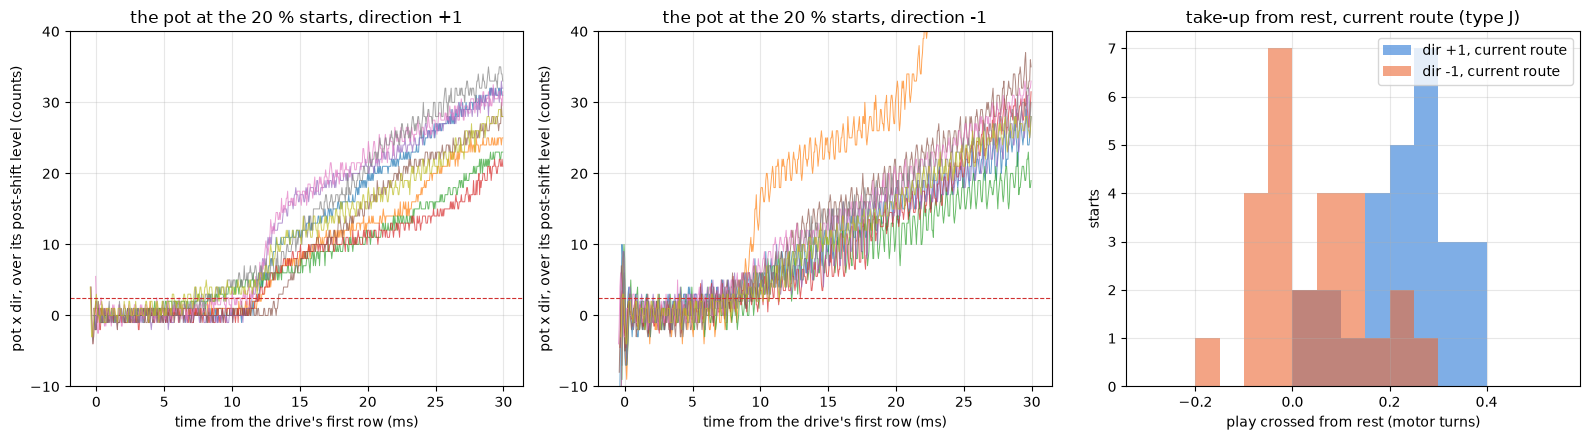

In [81]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, d in zip(axes[:2], (1, -1)):
    for tr in TRACES:
        b = tr["base"]
        if b["dir"] != d or b["base_pct"] != 20:
            continue
        tk = tr["takeup"]
        rows = np.arange(len(tk["pos"])) - tk["row0"]
        ref = np.median(tk["pos"][tk["row0"] + 2:tk["row0"] + 40])
        ax.plot(rows / FS * 1e3, (tk["pos"] - ref) * d, lw=0.7, alpha=0.7)
    ax.axhline(POT_STILL_COUNTS, **figures.HIGHLIGHT_STYLE)
    ax.set_ylim(-10, 40)
    figures.label(ax, x="time from the drive's first row (ms)",
                  y="pot x dir, over its post-shift level (counts)",
                  title=f"the pot at the 20 % starts, direction {d:+d}")
for d, color in ((1, BLUE), (-1, ORANGE)):
    axes[2].hist(T[T.dir == d].play_turns_cur, alpha=0.6, color=color,
                 bins=np.arange(-0.3, 0.6, 0.05),
                 label=f"dir {d:+d}, current route")
figures.label(axes[2], x="play crossed from rest (motor turns)",
              y="starts", title="take-up from rest, current route (type J)")
axes[2].legend()
figures.finish(fig)

A +1 start crosses 0.230 +/- 0.101 motor turns of play by the current route (se 0.02 over 27 starts, 0.19 with 30 mA of drag off), and a -1 start crosses 0.024 +/- 0.124, none. The EMF route reads 0.27 and 0.07 turns under A and 0.14 and -0.03 under B, and the dip count 0.27 and 0.17. The take-up is the same at the three starts within the spread.

So a +1 start crosses 0.23 turns of play, 5.3 counts or 0.27 degrees at the output, and a -1 start crosses none. A backlash is not one-sided, so the asymmetry needs a reading. Three are open.

- (i) The seek leaves the train wound against a +1 drive and with a -1 drive at both guards, through the sweep's seek and brake sequence. Leading.
- (ii) The -1 starts' pot offset masks their take-up. The reference is read after the shift and the shift is a step, so this is unlikely, but a shift that relaxed over milliseconds would do it. Low to moderate.
- (iii) A direction-dependent play, unphysical for a simple gap. Low.

The backlash is then 0.23 turns, bracketed 0 to 0.33 by the two directions, moderate on the value and high on the bound under 0.35 turns. The pot-table pass against the tag is the measurement that pins it, a slow reversal both ways at several positions with the tag. Reading (i) predicts the same play both ways under the tag, (ii) a pot offset that follows the current, (iii) a one-sided play under the tag too.

The pot's shift at the drive's first rows, in raw counts, by base and direction. The thing to see is the -1 starts reading higher before anything moves.

In [82]:
T["pot_shift_raw_counts"] = T.pot_shift_counts * T.dir   # raw pos frame
shift = agg(T, ["base_pct", "dir"], ["pot_shift_raw_counts"])
print(shift[["base_pct", "dir", "n", "pot_shift_raw_counts",
             "pot_shift_raw_counts_sd"]].round(1).to_string(index=False))

 base_pct  dir  n  pot_shift_raw_counts  pot_shift_raw_counts_sd
       20   -1  9                   2.6                      2.4
       20    1  9                  -0.5                      2.0
       30   -1  9                  -0.2                      4.9
       30    1  9                   0.7                      1.0
       40   -1  9                   4.0                      3.5
       40    1  9                   0.8                      0.8


### The reversals

`reversal-1` drives a duty, then its negative with no release. Everything is read in the frame of the first segment's direction, so forward is positive before the flip. Through the crossing the motor's speed comes by two routes, since the tach is blind near zero speed.

- The current route. The rotor, free once the output coasts ahead of it, slows at $K_t I / J$ under the plugging current from its tach speed at the flip, or from the EMF speed under A where the tach is blind at 10 %, and then turns the other way.
- The EMF route, $(V - R\,I)/K_e$ under A and under B, smoothed over 1 ms.

The motor's zero crossing is where each route's speed changes sign. The pot reads a jump at the flip, a discontinuity against its own pre-flip slope, and it is taken off the rows after the flip. The pot then reaches its extremum, and its restart is where the 1 ms smoothed pot has left that extremum by 2.5 counts the other way. The play is the gap at the restart, the output's forward travel since the flip less the motor's net travel, in motor turns.

One reversal pair converted, in the first direction's frame.

In [83]:
PAIRS = {1: (1, 2), -1: (3, 4)}         # the two segments by first dir
LOOK = int(LOOK_MS * 1e-3 * FS)         # rows after the flip read


def reversal_signals(df, board, d1):
    # one reversal pair, forward positive before the flip
    fr, starts = direction_frame(df, PAIRS[d1])
    zero_i, _ = tel.rest_zeros(df)
    raw = fr["current_raw"].to_numpy(float)
    i_meas = amps(raw, zero_i)          # A, its size in either direction
    duty = fr["duty_counts"].to_numpy(float)
    sgn = np.sign(duty) * d1            # +1 before the flip, -1 after
    half = np.abs(duty)
    D = half / board.pwm_arr
    share = share_of(half, 2 * board.pwm_arr)
    von = np.abs(v_on(fr, 1))           # V, the crest volts' size
    i_signed = sgn * i_meas
    v_a = sgn * D * von
    v_b = sgn * share * von - (1 - share) * R_BRK * i_signed
    s_a, s_b = starts[PAIRS[d1][0]], starts[PAIRS[d1][1]]
    f_row, held = flip_row(fr.iloc[s_b:])
    return SimpleNamespace(
        d1=d1, raw=raw, i_meas=i_meas, duty=duty, half=half, held=held,
        i_signed=i_signed, w_a=(v_a - R_LOCKED * i_signed) / KE_LADDER,
        w_b=(v_b - R_LOCKED * i_signed) / KE_LADDER, n=len(fr),
        pos=fr["pos"].to_numpy(float) * d1, s_a=s_a, s_b=s_b,
        flip=s_b + f_row,
        drive0=s_a + tel.drive_start(fr.iloc[s_a:s_b]))

The tach before the flip, the EMF speeds smoothed over 1 ms, the plugging current and whether the current limit cut the duty. The reads add their traces to the pair's namespace for the figure.

In [84]:
def flip_reads(r, limit_counts):
    # the speed at the flip and the plugging current after it
    f = r.flip
    track_from = r.drive0 + int(TRACK_FROM_MS * 1e-3 * FS)
    f_seed = ripple_line(r.raw[f - int(0.015 * FS):f])
    tc1 = tracked_crossings(r.raw, track_from, f - 1, f_seed)
    r.t1, _, r.w1 = cycle_speeds(tc1)
    pre = r.t1 * FS > f - int(0.010 * FS)       # its last 10 ms
    r.w_flip = float(np.nanmean(r.w1[pre])) if pre.sum() >= 2 else np.nan
    r.wa_s, r.wb_s = smooth(r.w_a, 20), smooth(r.w_b, 20)
    after = r.half[f + 2:f + LOOK]      # the applied window after it
    return {"w_tach_at_flip_rev_s": r.w_flip,
            "w_a_at_flip_rev_s": float(r.wa_s[f - 20]),
            "w_b_at_flip_rev_s": float(r.wb_s[f - 20]),
            "i_before_ma": float(r.i_meas[f - 40:f].mean() * 1e3),
            "i_peak_ma": float(r.i_meas[f:f + LOOK].max() * 1e3),
            "i_peak_ms": float(np.argmax(r.i_meas[f:f + LOOK]) / FS * 1e3),
            "duty_min_after_ticks": float(after.min()),
            "limit_engaged": bool(after.min() < r.held - 1),
            "limit_counts": int(limit_counts)}


def emf_zero(r, w_s):
    # the row the smoothed EMF speed first goes negative, from 0.5 ms on
    below = np.flatnonzero(w_s[r.flip + 10:r.flip + LOOK] < 0)
    return r.flip + 10 + int(below[0]) if len(below) else None

In [85]:
def pot_restart(r):
    # the pot's jump at the flip taken off, its extremum and its restart
    f = r.flip
    slope = line(np.arange(60) / FS, r.pos[f - 62:f - 2])["slope"]
    jump = float(np.median(r.pos[f + 2:f + 12])
                 - np.median(r.pos[f - 12:f - 2]) - slope * 12 / FS)
    r.pos_j = r.pos.copy()
    r.pos_j[f:] -= jump                 # the jump off every later row
    r.pos_s = smooth(r.pos_j, POT_STILL_BOX)
    seg = r.pos_s[f:f + LOOK]
    k_max = int(np.argmax(seg))         # the output's extremum
    after = np.flatnonzero(seg[k_max:] < seg[k_max] - POT_STILL_COUNTS)
    r.t_r = f + k_max + int(after[0]) if len(after) else None
    return {"pot_jump_at_flip_counts": jump * r.d1,   # raw counts
            "t_pot_max_ms": k_max / FS * 1e3,
            "pot_coast_counts": float(seg[k_max] - r.pos_s[f]),
            "t_restart_ms": ((r.t_r - f) / FS * 1e3 if r.t_r is not None
                             else np.nan)}

In [86]:
def reversal_current_route(r):
    # the free rotor braked at Kt i / J from its speed at the flip
    f, t_r = r.flip, r.t_r
    w_seed = r.w_flip if np.isfinite(r.w_flip) else float(r.wa_s[f - 20])
    row = {"w_seed_rev_s": w_seed,
           "w_seed_source": "tach" if np.isfinite(r.w_flip) else "emf a"}
    for tag, drag in (("", 0.0), ("_drag", I_DRAG_A)):
        acc = KT_OVER_J * np.clip(r.i_meas[f:f + LOOK] - drag, 0, None)
        w = w_seed * 2 * np.pi - np.concatenate(
            [[0.0], np.cumsum((acc[1:] + acc[:-1]) / 2) / FS])   # rad/s
        theta = np.concatenate([[0.0], np.cumsum((w[1:] + w[:-1]) / 2)
                                / FS]) / (2 * np.pi)    # turns, forward +
        zero = np.flatnonzero(w < 0)
        t0 = f + int(zero[0]) if len(zero) else None
        row[f"t_m0_cur{tag}_ms"] = ((t0 - f) / FS * 1e3 if t0 is not None
                                    else np.nan)
        if t0 is None or t_r is None or t_r <= t0:
            continue
        out_fwd = (r.pos_s[t_r] - r.pos_s[f]) / COUNTS_PER_MOTOR_REV
        row.update({
            f"dead_cur{tag}_ms": (t_r - t0) / FS * 1e3,
            f"turns_back_cur{tag}": float(theta[t0 - f] - theta[t_r - f]),
            f"w_contact_cur{tag}_rev_s": float(-w[t_r - f] / (2 * np.pi)),
            f"play_gap_cur{tag}": float(out_fwd - theta[t_r - f]),
            f"motor_fwd_cur{tag}": float(theta[t0 - f]),
            "out_fwd_turns": float(out_fwd)})
    return row

In [87]:
def reversal_emf_route(r, zeros):
    # the EMF speed integrated from the flip to the restart, A and B
    row = {}
    for tag in ("a", "b"):
        t0 = zeros[tag]
        row[f"t_m0_{tag}_ms"] = ((t0 - r.flip) / FS * 1e3 if t0 is not None
                                 else np.nan)
        if t0 is None or r.t_r is None or r.t_r <= t0:
            continue
        w_e = (r.w_a if tag == "a" else r.w_b)[r.flip:r.t_r]   # rev/s
        theta_e = float(np.trapezoid(w_e, dx=1 / FS))   # net turns
        out_fwd = (r.pos_s[r.t_r] - r.pos_s[r.flip]) / COUNTS_PER_MOTOR_REV
        row[f"dead_{tag}_ms"] = (r.t_r - t0) / FS * 1e3
        row[f"play_gap_emf_{tag}"] = out_fwd - theta_e
        row[f"turns_back_emf_{tag}"] = float(np.trapezoid(
            np.clip(-w_e, 0, None), dx=1 / FS))
        w_s = r.wa_s if tag == "a" else r.wb_s
        row[f"w_contact_emf_{tag}_rev_s"] = float(-w_s[r.t_r])
    if zeros["a"] is not None and r.t_r is not None and (
            r.t_r - zeros["a"] > 12):   # the dips from A's zero
        row["dips"] = count_dips(r.raw, zeros["a"], r.t_r)
        row["turns_back_dips"] = row["dips"] / N_R
    return row

After the restart the tach, from 3 ms after it, approaches the new level, read with the chain model on one segment with no delay.

In [88]:
def after_restart(r):
    # the first-order approach to the new speed after the restart
    r.t2 = r.w2 = np.array([])
    if r.t_r is None:
        return {}
    f2 = ripple_line(r.raw[r.n - int(0.015 * FS):r.n])   # the end's line
    start = r.t_r + int(0.003 * FS)
    tc2 = tracked_crossings(r.raw, start, r.n - 1, f2)
    if len(tc2) <= 6:
        return {}
    r.t2, _, r.w2 = cycle_speeds(tc2)
    fit = fit_chain(r.t2, r.w2, [], start / FS, r.n / FS, taus=1,
                    delay=False)
    row = {"w_after_ss_rev_s": -fit["levels"][0],
           "w_after_init_rev_s": -fit["w_init"],
           "tau_after_ms": fit["taus_s"][0] * 1e3,
           "tau_after_se_ms": fit["taus_se_s"][0] * 1e3,
           "after_rms_rev_s": fit["rms"], "after_cycles": fit["n"]}
    hit = np.flatnonzero(r.wa_s[r.flip:r.flip + LOOK]
                         < -0.5 * row["w_after_ss_rev_s"])
    row["t_half_a_ms"] = hit[0] / FS * 1e3 if len(hit) else np.nan
    return row

In [89]:
def reverse_pair(df, meta, board, d1, info):
    # every read of one reversal, and the pair's namespace for figures
    r = reversal_signals(df, board, d1)
    row = {"k": int(info["k"]), "duty_pct": int(info["duty_pct"]),
           "dir_first": d1, "flip_row": int(r.flip),
           **flip_reads(r, meta["drive"]["current_limit_counts"])}
    zeros = {"a": emf_zero(r, r.wa_s), "b": emf_zero(r, r.wb_s)}
    row.update(pot_restart(r))
    row.update(reversal_current_route(r))
    row.update(reversal_emf_route(r, zeros))
    row.update(after_restart(r))
    row["travel_first_counts"] = float((r.pos_j[r.s_b - 1] - r.pos_j[r.s_a])
                                       * d1)
    row["travel_second_counts"] = float((r.pos_j[r.n - 1] - r.pos_j[r.s_b])
                                        * d1)
    r.info = row
    return row, r


REV_ROWS, REV_TRACES = [], []
for _, info in REV_CHAINS.iterrows():
    df, meta, board = load(REVERSAL / info["folder"])
    assert tel.gaps(df).sum() == 0, f"{info['folder']}: dropped rows"
    for d1 in (1, -1):
        row, r = reverse_pair(df, meta, board, d1, info)
        REV_ROWS.append(row)
        REV_TRACES.append(r)
R = pd.DataFrame(REV_ROWS)              # one row per reversal, 6

In [90]:
cols = ["duty_pct", "dir_first", "w_seed_source", "i_peak_ma", "i_peak_ms",
        "limit_engaged", "t_m0_cur_ms", "t_m0_a_ms", "t_m0_b_ms",
        "t_pot_max_ms", "t_restart_ms", "dead_cur_ms",
        "pot_jump_at_flip_counts", "tau_after_ms"]
print(R[cols].round(1).to_string(index=False))
cols = ["duty_pct", "dir_first", "motor_fwd_cur", "out_fwd_turns",
        "play_gap_cur", "play_gap_emf_a", "play_gap_emf_b"]
print(R[cols].round(2).to_string(index=False))

 duty_pct  dir_first w_seed_source  i_peak_ma  i_peak_ms  limit_engaged  t_m0_cur_ms  t_m0_a_ms  t_m0_b_ms  t_pot_max_ms  t_restart_ms  dead_cur_ms  pot_jump_at_flip_counts  tau_after_ms
       10          1         emf a      136.3        1.2          False          6.4        0.5        7.8           2.6          21.6         15.1                      0.7          14.6
       10         -1         emf a      154.8        2.1          False          7.8        6.4       13.0           7.2          22.6         14.8                     -8.3         109.4
       20          1          tach      333.7        1.1          False         10.4        7.7       11.2           8.1          19.4          9.0                      5.4          14.4
       20         -1          tach      335.4        1.4          False         11.8        8.1       10.2           8.8          13.8          2.0                     -4.3          36.6
       30          1          tach      518.7        1.8         

Six reversals, the pot in counts, the signed current in mA and the EMF speed under A in rev/s against the time from the flip. The pot's jump at the flip is taken off. The dotted line is the motor's zero crossing by the current route, the dashed line the pot's restart. The thing to see is the output coasting on past the flip while the plugging current brakes the motor, then the pot stopping and restarting after the motor has turned back.

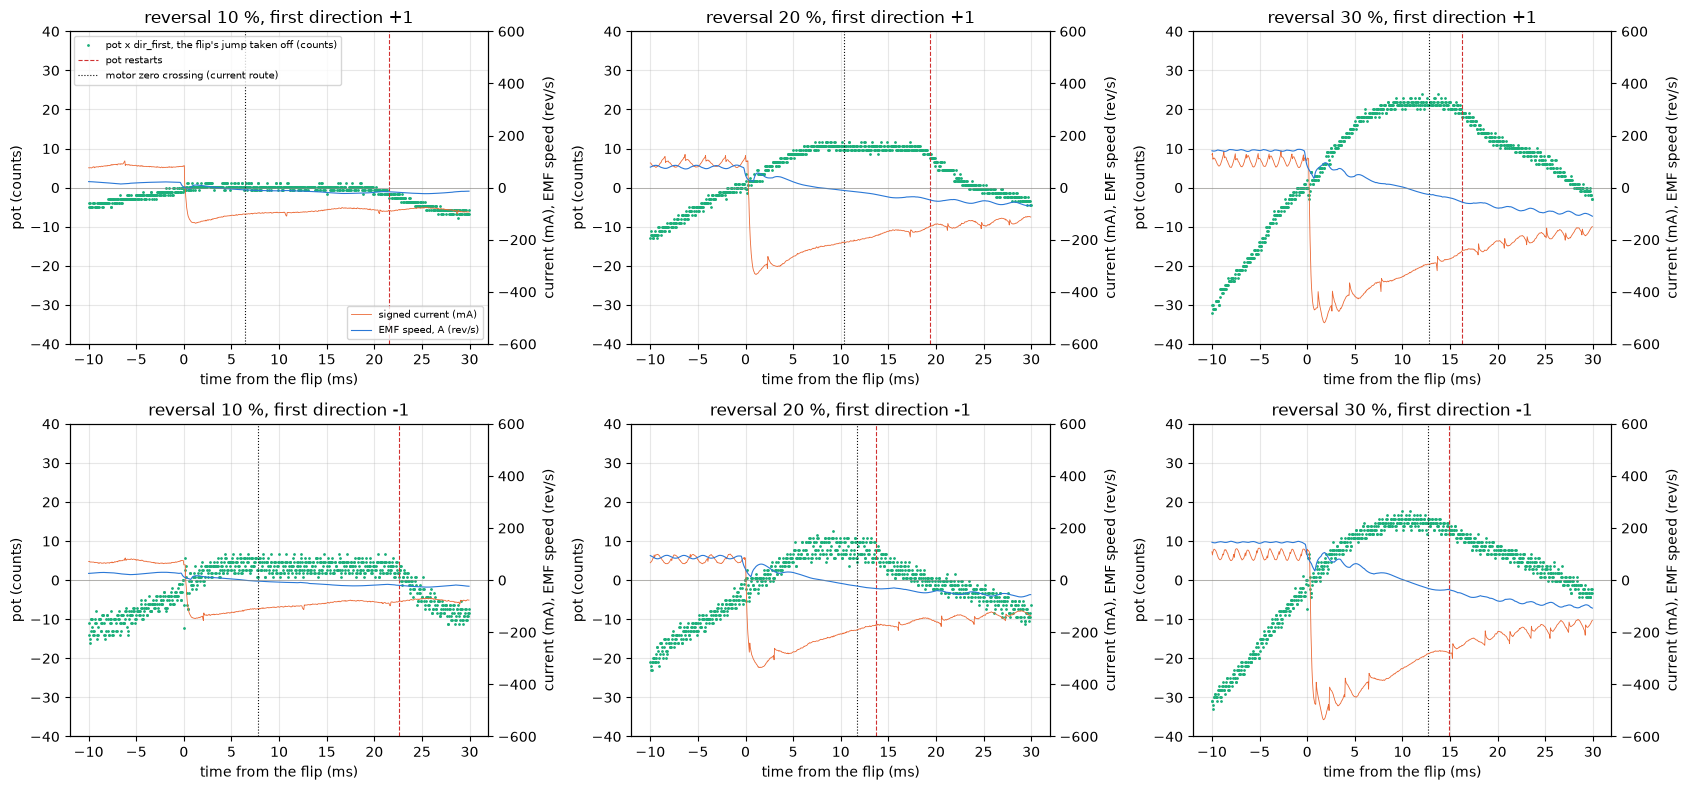

In [91]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, r in zip(axes.T.flat, REV_TRACES):
    f, info = r.flip, r.info
    rows = np.arange(f - 200, f + 600)
    ms = (rows - f) / FS * 1e3          # ms from the flip
    ax.plot(ms, r.pos_j[rows] - r.pos_j[f - 1], ".", ms=2, color=GREEN,
            label="pot x dir_first, the flip's jump taken off (counts)")
    ax2 = ax.twinx()
    ax2.plot(ms, r.i_signed[rows] * 1e3, color=ORANGE, lw=0.6,
             label="signed current (mA)")
    ax2.plot(ms, r.wa_s[rows], color=BLUE, lw=0.8,
             label="EMF speed, A (rev/s)")
    ax2.axhline(0, color=MUTED, lw=0.4)
    ax2.set_ylim(-600, 600)
    ax2.set_ylabel("current (mA), EMF speed (rev/s)")
    if r.t_r is not None:
        ax.axvline((r.t_r - f) / FS * 1e3, color=RED, lw=0.8, ls="--",
                   label="pot restarts")
    if np.isfinite(info.get("t_m0_cur_ms", np.nan)):
        ax.axvline(info["t_m0_cur_ms"], color=INK, lw=0.8, ls=":",
                   label="motor zero crossing (current route)")
    ax.set_ylim(-40, 40)
    figures.label(ax, x="time from the flip (ms)", y="pot (counts)",
                  title=f"reversal {info['duty_pct']} %, first direction "
                  f"{info['dir_first']:+d}")
    if info["duty_pct"] == 10 and info["dir_first"] == 1:
        ax.legend(fontsize=7, loc="upper left")
        ax2.legend(fontsize=7, loc="lower right")
figures.finish(fig)

The plugging current peaks at 136 to 155, 334 and 519 to 535 mA at 10, 20 and 30 % 1.1 to 2.1 ms after the flip, and the current limit never cut the duty. By the current route the motor crosses zero 7.1, 11.1 and 12.7 ms after the flip. The EMF route reads 3.5, 7.9 and 10.3 ms under A and 10.4, 10.7 and 11.5 under B. At 10 % it differences two near-equal 0.5 V terms and is not usable. The output coasts ahead of the braking motor, reaches its extremum 2.6 to 11.3 ms after the flip and restarts the other way at 22.1, 16.6 and 15.6 ms. The dead time from the motor's zero crossing to the pot's restart is 14.9, 5.5 (2.0 to 9.1) and 2.9 (2.2 to 3.5) ms. After the restart the tach approaches the new level with a time constant of 13 to 37 ms, except one 10 % reversal at 109 ms.

The play in motor turns, the gap at the restart by the current route, is 0.18 and 0.39 at 10 %, 0.17 and -0.08 at 20 %, 0.01 and -0.23 at 30 % (the two orders). The EMF route under A reads 0.18 to 0.54, and B 0.1 to 0.3 lower. Negative values are unphysical. With one reversal per case and a pot correction of the play's own size, the reversals resolve nothing beyond play within $\pm$0.3 turns of zero (low).

### The pot's current-coupled offset

The pot's jump at the flip, in raw counts, against the plugging current. The thing to see is that the jump scales with the current and appears whenever the drive turns to -1.

In [92]:
R["pot_jump_per_amp"] = R.pot_jump_at_flip_counts.abs() / (
    R.i_peak_ma * 1e-3)
print(R[["duty_pct", "dir_first", "pot_jump_at_flip_counts", "i_peak_ma",
         "pot_jump_per_amp"]].round(1).to_string(index=False))
jpa = R.pot_jump_per_amp
print(f"jump per A of plugging current: {jpa.mean():.1f} counts, "
      f"{jpa.min():.1f} to {jpa.max():.1f} over {len(jpa)}")

 duty_pct  dir_first  pot_jump_at_flip_counts  i_peak_ma  pot_jump_per_amp
       10          1                      0.7      136.3               5.2
       10         -1                     -8.3      154.8              53.6
       20          1                      5.4      333.7              16.2
       20         -1                     -4.3      335.4              12.9
       30          1                     13.0      518.7              25.0
       30         -1                    -12.3      535.4              22.9
jump per A of plugging current: 22.6 counts, 5.2 to 53.6 over 6


The raw pot reads higher while the bridge drives -1, in both orders. The jump appears when the drive turns to -1 and disappears when it turns to +1, 0.7 and 8.3 counts at 10 %, 5.4 and 4.3 at 20 %, 13.0 and 12.3 at 30 %, about 23 counts per ampere of plugging current (5 to 54 over the six). The same shows at the drive's start from rest, where the -1 starts read +2.6 +/- 2.4 counts higher at 20 % and +4.0 +/- 3.5 at 40 % before any motion, with -0.2 +/- 4.9 at 30 %, and the +1 starts move 0.3 +/- 1.5 pooled.

This is likely a current-coupled offset in the pot's reading tied to the -1 leg. Its size is that of the backlash it sits on. A shared ground drop of the order of 20 mohm, carrying the motor's current under the pot's ground on that leg, would do it, and is the leading cause. Coupling into the wiper is the other candidate. A locked-horn hold at $\pm$0.3 A reading `pos` in both signs, with the DMM on the pot's ground against the board's, separates them. It is an input to the pot-table notebook and to stage 5, whose position estimator sees 5 to 13 counts of step at every reversal under current.

## Results

The result file's quantities. A mean with one standard deviation either side is the default, and each unit string says when the bounds are something else. The velocity loop's plant first.

In [93]:
q = results.quantity


def sdq(x, unit, scale=1.0):
    # the mean of x with one sd either side, none for a single value
    m, sd, _, _ = wmean(np.asarray(x, float) * scale)
    ok = np.isfinite(sd)
    return q(m, m - sd if ok else None, m + sd if ok else None, unit)


def by_start(df, col, unit):
    # one quantity per start share
    return {f"{s:.3f}": sdq(df[np.isclose(df.start_share, s,
                                          atol=0.01)][col], unit)
            for s in (0.0, 1 / 6, 1 / 3)}


OUT = {"tau_m_ms": sdq(UP.tau_m_chain_ms, "ms, mechanical time constant of "
                       "the speed's response, one whole-chain first-order "
                       "model per chain and direction, mean +/- sd over 54"),
       "tau_m_se_ms": q(UP.tau_m_chain_ms.std() / np.sqrt(len(UP)),
                        unit="ms, the mean's standard error")}
OUT["tau_m_by_base_ms"] = {str(b): sdq(UP[UP.base_pct == b].tau_m_chain_ms,
                                       "ms") for b in (20, 30, 40)}
OUT["tau_m_by_direction_ms"] = {f"{d:+d}": sdq(
    UP[UP.dir == d].tau_m_chain_ms, "ms") for d in (1, -1)}
OUT["tau_m_by_start_ms"] = by_start(UP, "tau_m_chain_ms", "ms")

In [94]:
OUT["tau_m_step_up_ms"] = sdq(OK3.tau_up3_ms, "ms, the step up's own time "
                              "constant in the three-constant chain model, "
                              "bases 20 and 30 %")
OUT["tau_m_step_down_ms"] = sdq(OK3.tau_down3_ms, "ms, the step back's own,"
                                " the same model")
OUT["tau_m_runup_from_rest_ms"] = sdq(
    OK3[OK3.tau_runup_ms < 150].tau_runup_ms, "ms, the base segment's "
    "approach from rest (after the take-up), slower than the small steps")
up10 = gi.loc["up 10 %"]
OUT["tau_m_from_current_ms"] = q(
    up10.tau_m_i_ms, up10.tau_m_i_ms - up10.tau_m_i_sd_ms,
    up10.tau_m_i_ms + up10.tau_m_i_sd_ms, "ms, the time constant of the "
    "current's fall after the 10 % step up, ensemble of 18 edges, "
    "bootstrap sd")
OUT["speed_delay_ms"] = q(
    UP.w_delay_chain_ms.median(), 0.0, UP.w_delay_chain_ms.quantile(0.9),
    "ms, the speed's delay after the duty register's flip: the median over "
    "54 chains with the 90th percentile as the upper bound; under the "
    "tach's cycle resolution, a bound not a value")
OUT["speed_delay_max_ms"] = q(UP.w_delay_chain_ms.max(),
                              unit="ms, the largest fitted delay")

In [95]:
kw = "k_w_chain_rev_s_per_pct"
OUT["k_w_rev_s_per_pct"] = sdq(BIG[kw], "rev/s per % of duty on 5 V, "
                               "settled speed change of the chain model, 5 "
                               "and 10 % steps up and down, mean +/- sd "
                               "over 72 edges")
OUT["k_w_up_rev_s_per_pct"] = sdq(BIG[BIG.edge == "up"][kw],
                                  "rev/s per %, steps up")
OUT["k_w_down_rev_s_per_pct"] = sdq(BIG[BIG.edge == "down"][kw],
                                    "rev/s per %, steps down")
OUT["k_w_by_step_rev_s_per_pct"] = {
    f"{e} {s}": sdq(E[(E.edge == e) & (E.step_pct == s)][kw], "rev/s per %")
    for e in ("up", "down") for s in (2, 5, 10)}
OUT["k_w_by_base_rev_s_per_pct"] = {
    str(b): sdq(BIG[BIG.base_pct == b][kw], "rev/s per %")
    for b in (20, 30, 40)}
OUT["k_w_by_start_rev_s_per_pct"] = by_start(BIG, kw, "rev/s per %")
OUT["k_w_by_direction_rev_s_per_pct"] = {
    f"{d:+d}": sdq(BIG[BIG.dir == d][kw], "rev/s per %") for d in (1, -1)}
OUT["k_w_per_v_a_rev_s_per_v"] = sdq(PER_V_A, "rev/s per V of applied "
                                     "volts under construction A (the duty"
                                     " step times the crest tap volts "
                                     "before the edge)")
OUT["k_w_per_v_a_after_rev_s_per_v"] = sdq(
    PER_V_AFTER, "rev/s per V, A with the tap volts after the edge (the "
    "rail's move on the step in)")
OUT["k_w_per_v_b_over_a"] = q(B_OVER_A, unit="ratio, construction B's gain "
                              "per volt over A's: the brake term's change "
                              "on a step")

In [96]:
for name, unit in (("base_pct", "rev/s per % per % of base, a line through"
                    " the 72 edges"),
                   ("start_share", "rev/s per % per unit of start share"),
                   ("minutes", "rev/s per % per minute through the "
                    "capture")):
    f = SLOPES[name]
    key = {"base_pct": "base", "start_share": "start"}.get(name, name)
    OUT[f"k_w_vs_{key}_slope"] = results.pm(f["slope"], f["slope_se"], unit)
OUT["step_down_over_up"] = sdq(DOWN_OVER_UP, "ratio of the speed change "
                               "back to the change up, paired by chain, "
                               "mean +/- sd over 54")
OUT["speed_duty_line_slope_rev_s_per_pct"] = results.pm(
    SPEED_LINE["slope"], SPEED_LINE["slope_se"], "rev/s per %, a line "
    "through the settled levels 20 to 50 %")
OUT["speed_duty_line_intercept_rev_s"] = results.pm(
    SPEED_LINE["intercept"], SPEED_LINE["intercept_se"], "rev/s at zero "
    "duty by that line (negative: the floor)")
OUT["k_i_settled_ma_per_pct"] = sdq(BIG.k_i_ss_chain_ma_per_pct, "mA per % "
                                    "of duty, the settled current's change,"
                                    " chain model levels")
OUT["travel_per_step_counts"] = {
    f"{e} {s}": sdq(E[(E.edge == e) & (E.step_pct == s)].travel_counts,
                    "raw pot counts the stepped segment traveled, signed by "
                    "the direction, so the mean sits near zero and the sd "
                    "carries the size; window as cut by the runway")
    for e in ("up", "down") for s in (2, 5, 10)}

The current loop's plant.

In [97]:
def grp(name, key, unit, sdkey=None):
    # one ensemble group's term, its bootstrap sd as the bounds
    v = gi.loc[name, key]
    sd = gi.loc[name, sdkey] if sdkey else np.nan
    ok = np.isfinite(sd)
    return q(v, v - sd if ok else None, v + sd if ok else None, unit)


OUT["current_delay_up_us"] = grp(
    "up 10 %", "delay_us", "us after the duty register's flip row, the "
    "exponential's start, 10 % steps up, ensemble of 18, bootstrap sd",
    "delay_sd_us")
OUT["current_delay_down_us"] = grp("down 10 %", "delay_us",
                                   "us, 10 % steps down", "delay_sd_us")
OUT["current_delay_bound_us"] = q(0.0, -ROW_US, ROW_US, "us, the delay from"
                                  " the command's edge as the stream shows "
                                  "it: within one row of the flip either "
                                  "way")
for key, name, unit in (
        ("tau_e_up_us", "up 10 %", "us, electrical time constant of the "
         "crest current's rise, 10 % steps up, bootstrap sd"),
        ("tau_e_up_5pct_us", "up 5 %", "us, 5 % steps up"),
        ("tau_e_down_us", "down 10 %", "us, 10 % steps down"),
        ("tau_e_down_5pct_us", "down 5 %", "us, 5 % steps down")):
    OUT[key] = grp(name, "tau_e_us", unit, "tau_e_sd_us")
OUT["tau_e_by_group_us"] = {n: grp(n, "tau_e_us", "us", "tau_e_sd_us")
                            for n in gi.index if "+" in n}
OUT["tau_e_inductance_notebook_us"] = q(TAU_E_US, TAU_E_LO, TAU_E_HI,
                                        "us, the inductance notebook's "
                                        "locked bursts, comparison")

In [98]:
OUT["di_e_per_v_up_ma_per_v"] = grp(
    "up all per volt", "plateau_P", "mA per V of applied change (A), the "
    "plateau the slow fit extrapolates to the edge, steps up, bootstrap sd",
    "plateau_P_sd")
OUT["di_e_per_v_down_ma_per_v"] = grp("down all per volt", "plateau_P",
                                      "mA per V, steps down", "plateau_P_sd")
OUT["di_e_per_v_up_at_2ms_ma_per_v"] = grp(
    "up all per volt", "di", "mA per V, the electrical fit's plateau (1 to "
    "2 ms)", "di_sd")
OUT["r_step_a_ohm"] = sdq(P10.r_step_a_ohm, "ohm, dV_A / di_e per edge, 10 "
                          "% steps up and down, the group's shape scaled to"
                          " each edge, mean +/- sd over 72 rows: the 36 "
                          "edges, each with its 18-edge group's shape and "
                          "its 6-edge base group's")
OUT["r_step_a_up_ohm"] = sdq(P10[P10.edge == "up"].r_step_a_ohm,
                             "ohm, steps up")
OUT["r_step_a_down_ohm"] = sdq(P10[P10.edge == "down"].r_step_a_ohm,
                               "ohm, steps down")
OUT["r_step_a_after_ohm"] = sdq(P10.r_step_a_after_ohm, "ohm, with the tap "
                                "volts after the edge")
OUT["r_step_a_ensemble_up_ohm"] = q(up10.r_step_a_ohm, unit="ohm, the "
                                    "18-edge ensemble's dV_A / di")
OUT["r_step_b_ensemble_up_ohm"] = q(up10.r_step_b_ohm, unit="ohm, the same "
                                    "under B (the brake term's change at "
                                    "the plateau)")
OUT["r_step_b_over_a"] = q(up10.r_step_b_ohm / up10.r_step_a_ohm,
                           unit="ratio")
OUT["r_takeback_ohm"] = sdq(BIG.r_takeback_ohm, "ohm, Ke x dw / (plateau - "
                            "settled change) from the chain model's jumps "
                            "and levels, no volts in it, 5 and 10 % steps")
OUT["r_takeback_ensemble_ohm"] = sdq(P10.r_takeback_ens_ohm, "ohm, the same"
                                     " with the ensemble plateau per edge")
OUT["r_locked_ohm"] = q(R_LOCKED, R_LOCKED_LO, R_LOCKED_HI, "ohm, the "
                        "resistance notebook's locked laps, comparison")

In [99]:
dn10 = gi.loc["down 10 %"]
l_up = up10.tau_e_us * 1e-3 * R_LOCKED  # mH, tau_e x R_locked
rel = up10.tau_e_sd_us / up10.tau_e_us  # tau_e's relative bootstrap sd
OUT["l_step_up_mh"] = q(l_up, l_up * (1 - rel), l_up * (1 + rel),
                        "mH, tau_e (up) x the locked R")
OUT["l_step_up_r_step_mh"] = q(up10.l_step_a_mh, unit="mH, tau_e (up) x "
                               "the step's own R under A")
OUT["l_step_down_mh"] = q(dn10.tau_e_us * 1e-3 * R_LOCKED, unit="mH, "
                          "tau_e (down) x the locked R")
OUT["l_inductance_notebook_mh"] = q(L_MH, L_MH_LO, L_MH_HI,
                                    "mH, comparison")
OUT["jump_term_up_ma"] = q(up10.jump, unit="mA, an instant jump added to "
                           "the up 10 % ensemble model; its residual gain "
                           "is under 1 %, not a finding")
OUT["current_ensemble_rms_ma"] = q(
    up10.rms, dn10.rms, gi.loc["up 5 %", "rms"], "mA, the residual of the "
    "ensemble fits (up 10, down 10, up 5)")
OUT["di_settled_per_pct_ma"] = sdq(BIG.k_i_ss_chain_ma_per_pct,
                                   "mA per %, settled")

The levels, the take-up and the reversals.

In [100]:
for dp in (20, 30, 40):
    s = SETTLED[SETTLED.duty_pct.round(0) == dp]
    OUT[f"level_{dp}_speed_rev_s"] = sdq(s.w_tach_rev_s, "rev/s, tach, "
                                         "settled levels at this duty")
    OUT[f"level_{dp}_current_ma"] = sdq(s.i_ma, "mA")
    OUT[f"level_{dp}_x_a_mv"] = sdq(s.x_a_mv, "mV, V_A - R_locked i - "
                                    "Ke_ladder w")
    OUT[f"level_{dp}_x_b_mv"] = sdq(s.x_b_mv, "mV, under B")
OUT["pot_over_tach"] = sdq(POT_OVER_TACH, "ratio of the pot's speed "
                           "(nominal counts per turn) to the tach's over "
                           "the settled windows")
OUT["counts_per_motor_turn_measured"] = q(
    COUNTS_PER_MOTOR_REV * POT_OVER_TACH.mean(),
    unit="pot counts per motor turn by that ratio")

In [101]:
for d in (1, -1):
    s, tag = T[T.dir == d], "pos" if d == 1 else "neg"
    OUT[f"takeup_still_ms_dir_{tag}"] = sdq(
        s.still_ms, "ms the pot stays within 2.5 counts after the drive "
        "starts from rest")
    OUT[f"play_from_rest_turns_dir_{tag}"] = sdq(
        s.play_turns_cur, "motor turns the rotor makes before the output "
        "moves, current route (type J, this Ke), less the output's own 2.5"
        " counts")
    OUT[f"play_from_rest_turns_drag_dir_{tag}"] = sdq(
        s.play_turns_cur_drag, "motor turns, the same with 30 mA of rotor "
        "drag taken off")
    OUT[f"play_from_rest_counts_dir_{tag}"] = sdq(
        s.play_turns_cur * COUNTS_PER_MOTOR_REV, "pot counts (nominal "
        "counts per turn)")
    OUT[f"play_from_rest_deg_dir_{tag}"] = sdq(
        s.play_turns_cur * COUNTS_PER_MOTOR_REV / COUNTS_PER_DEG,
        "output degrees (nominal)")
    OUT[f"pot_shift_at_start_counts_dir_{tag}"] = sdq(
        s.pot_shift_counts, "raw pot counts the reading moves the moment "
        "the drive starts, before motion")

The backlash's bracket comes from the take-up. The value is the +1 starts' mean play by the current route, the low bound the -1 starts' none, the high bound the +1 mean plus its sd.

In [102]:
play_pos = OUT["play_from_rest_turns_dir_pos"]
BACKLASH = (play_pos["value"], 0.0, play_pos["hi"])   # turns
OUT["backlash_bound_turns"] = q(*BACKLASH, "motor turns: the leading value"
                                " from the +1 starts, the bracket from the "
                                "-1 starts (none) to the +1 starts' upper "
                                "sd")
OUT["backlash_bound_counts"] = q(*(x * COUNTS_PER_MOTOR_REV for x in
                                   BACKLASH), "pot counts")
OUT["backlash_bound_deg"] = q(*(x * COUNTS_PER_MOTOR_REV / COUNTS_PER_DEG
                                for x in BACKLASH), "output degrees")
for key in ("turns", "counts", "deg"):
    b = OUT[f"backlash_bound_{key}"]
    print(f"backlash {key}: {b['value']:.3f} ({b['lo']:.2f} to "
          f"{b['hi']:.3f})")

backlash turns: 0.230 (0.00 to 0.332)
backlash counts: 5.329 (0.00 to 7.677)
backlash deg: 0.269 (0.00 to 0.388)


In [103]:
def span_q(x, unit):
    # the mean of a reversal pair with its two values as the bounds
    return q(x.mean(), x.min(), x.max(), unit)


for dp in (10, 20, 30):
    s = R[R.duty_pct == dp]
    for key, col, unit in (
            ("t_zero_ms", "t_m0_cur_ms", "ms from the flip to the motor's "
             "zero crossing, current route, two orders"),
            ("t_zero_emf_a_ms", "t_m0_a_ms", "ms, the EMF route under A"),
            ("pot_restart_ms", "t_restart_ms", "ms from the flip to the pot"
             " leaving its extremum by 2.5 counts"),
            ("dead_ms", "dead_cur_ms", "ms, restart less zero crossing"),
            ("play_turns", "play_gap_cur", "motor turns, the gap at the "
             "restart by the current route, pot jump removed, two orders "
             "(one each)"),
            ("peak_current_ma", "i_peak_ma", "mA, plugging peak"),
            ("tau_after_ms", "tau_after_ms", "ms, the approach to the new "
             "speed after the restart")):
        OUT[f"reversal_{dp}_{key}"] = span_q(s[col], unit)
    OUT[f"reversal_{dp}_pot_jump_counts"] = span_q(
        s.pot_jump_at_flip_counts.abs(), "raw pot counts the reading jumps"
        " at the flip")
OUT["pot_jump_per_amp_counts"] = span_q(R.pot_jump_per_amp, "raw pot counts"
                                        " per A of plugging current at the "
                                        "flip, both orders")
OUT["reversal_limit_engaged"] = q(float(R.limit_engaged.any()), unit="1 if "
                                  "the current limit cut any duty at a "
                                  "reversal (0: none did)")
OUT["chains"] = q(len(UP), unit="chains x directions in steps/capture-1")
print(len(OUT), "keys")

114 keys


### The result file

The notes that define every key. Report-only keys describe this sitting and set no firmware number. Bound-only keys carry a bound, not a value. Construction-dependent keys change with the construction of the applied volts, A or B, and stay open until the kill test the resistance notebook names runs.

In [104]:
NOTES = (
    "stage 3 steps of mg90-d on dev-v006-2A-D, horn free, 5 V from the "
    "DPS-150 over the feed diode, experiment image, sitting 1: "
    "steps/capture-1 (27 chains of a base duty, a step up and the step "
    "back, bases 20, 30 and 40 %, steps 2, 5 and 10 %, from the guards and "
    "the guards moved in by a sixth and a third of the travel, directions "
    "+1 and -1: 54 chain-directions, 108 edges, 162 levels, 54 starts from"
    " rest) and steps/reversal-1 (d then -d at 10, 20 and 30 %, both "
    "orders, 6 reversals). Current through stage 1 current-scale over each"
    " sweep's torque-off zero with the in-drive offset out, the crest "
    "sample; volts through terminal-chain; construction A = D x V_on, B = "
    "share x V_on - (1 - share) R_brk i with sample-timing's edge lags "
    "(mean of the graded rails) and bridge-states' low-side loop. Speed by "
    "the tracked ripple tach on the drive current (6 events per rev), "
    "never the pot. Ke the ladder result's, R the resistance result's "
    "locked laps, J mg90-b's speed-torque value in the current route only."
    " Bounds are mean +/- sd over the repeats unless the unit says "
    "otherwise: the ensemble groups' bootstrap sd over the edges (200 "
    "resamples, seeded), a line's se, or a reversal pair's two values. "
)

In [105]:
NOTES += (
    "Velocity loop. tau_m_ms the one-constant whole-chain model's time "
    "constant, tau_m_se_ms its standard error; tau_m_by_base, "
    "_by_direction and _by_start report only; tau_m_step_up_ms, "
    "tau_m_step_down_ms and tau_m_runup_from_rest_ms the three-constant "
    "model at bases 20 and 30 % with every constant under 100 ms (run-up "
    "under 150 ms), report only; tau_m_from_current_ms the up 10 % "
    "ensemble's slow fall, an open discrepancy against tau_m_ms. "
    "speed_delay_ms bound-only, value the median fitted delay (at its bound"
    " 0), hi the 90th percentile, under the tach's cycle; "
    "speed_delay_max_ms report only. k_w_rev_s_per_pct the gain per % of "
    "duty on 5 V; k_w_up, k_w_down and k_w_by_* report only; "
    "k_w_per_v_a_rev_s_per_v and k_w_per_v_a_after_rev_s_per_v "
    "construction-dependent (A, the crest volts before and after the "
    "edge); k_w_per_v_b_over_a construction B's gain per volt over A's, "
    "steps up. k_w_vs_*_slope a line's slope with se bounds, none a "
    "finding, start and minutes collinear by the capture's order. "
    "step_down_over_up report only, 1.3 sigma from 1. speed_duty_line_* a "
    "line through the settled levels, se bounds. k_i_settled_ma_per_pct "
    "and di_settled_per_pct_ma the same quantity, the settled current's "
    "change per %. travel_per_step_counts report only, signed. "
)

In [106]:
NOTES += (
    "Current loop. current_delay_up_us and _down_us the ensemble's start "
    "t0 from the flip row; current_delay_bound_us bound-only, one 50 us row"
    " either side of the flip row. tau_e_up_us and tau_e_down_us at 10 % "
    "are the numbers of record, their difference 2.8 sigma (likely, cause "
    "open); tau_e_*_5pct_us and tau_e_by_group_us report only. "
    "tau_e_inductance_notebook_us and l_inductance_notebook_mh comparisons."
    " di_e_per_v_up_ma_per_v and _down the plateau per volt of applied "
    "change under A at the edge, construction-dependent; "
    "di_e_per_v_up_at_2ms the fast fit's plateau, report only. r_step_* is"
    " the resistance a small step reads on the crest current, an open "
    "discrepancy against the locked laps and NOT a value of R; the per-edge"
    " r_step_a_ohm, _up, _down, _after and r_takeback_ensemble_ohm count "
    "each edge twice (its 18-edge and its 6-edge group's shape); r_step_a_* "
    "and r_step_b_* construction-dependent; r_takeback_ohm and "
    "r_takeback_ensemble_ohm volts-free, resting on Ke. r_locked_ohm "
    "quoted. l_step_up_mh tau_e up x the locked R, bounds from tau_e's "
    "bootstrap sd; l_step_up_r_step_mh and l_step_down_mh report only. "
    "jump_term_up_ma report only, not a finding. current_ensemble_rms_ma "
    "value up 10 %, lo down 10 %, hi up 5 %, three residuals, not bounds. "
)

In [107]:
NOTES += (
    "Levels. level_{20,30,40}_speed_rev_s and _current_ma the settled "
    "levels (speed change under 2.5 % across the last 40 ms, at least 20 "
    "tach cycles) pooled over both directions, mean +/- sd; "
    "level_*_x_a_mv and _x_b_mv the EMF balance V - R_locked i - Ke w under"
    " A and B, construction-dependent. pot_over_tach and "
    "counts_per_motor_turn_measured report only, pot-table grades the "
    "slope. Starts and reversals. takeup_still_ms_dir_* and "
    "play_from_rest_*_dir_* per direction (pos +1, neg -1), the play by "
    "the current route with the type J; pot_shift_at_start_counts_dir_* in"
    " the drive's frame, so negative for -1 means the raw pos reads up. "
    "backlash_bound_*: value the +1 starts' mean play, lo 0 (the -1 starts"
    " cross none), hi the +1 mean plus its sd; moderate on the value, high"
    " on the bound under 0.35 turns; the tag pass pins it. "
    "reversal_{10,20,30}_*: value the mean of the two orders, bounds their"
    " two values; t_zero_emf_a unusable at 10 %; play_turns resolves "
    "nothing beyond +/-0.3 turns, report only; tau_after_ms report only. "
    "pot_jump_per_amp_counts the pot's current-coupled offset on the -1 "
    "leg, likely, bounds the six reversals' range. "
    "reversal_limit_engaged 0 when no duty was cut. chains the count."
)

The result file, then every key as written.

In [108]:
CAPTURE_FIELD = ", ".join(str(results.rel(p)) for p in (CAPTURE, REVERSAL))
path = results.write("3-servo", "steps", CAPTURE_FIELD, pair=PAIR,
                     notes=NOTES, **OUT)
written = results.read("3-servo", "steps", pair=PAIR)
print("wrote", path, "with", len(OUT), "keys, capture", written["capture"])
flat = pd.DataFrame([{"key": k, **v} for k, v in written.items()
                     if isinstance(v, dict) and "value" in v])
show(flat, n=None)

wrote stages/3-servo/steps/results/mg90-d__dev-v006-2A-D.json with 114 keys, capture telemetry/mg90-d__dev-v006-2A-D/steps/capture-1, telemetry/mg90-d__dev-v006-2A-D/steps/reversal-1


,key,value,lo,hi,unit
0,tau_m_ms,20.857,16.831,24.883,"ms, mechanical time constant of the speed's re..."
1,tau_m_se_ms,0.548,NaN,NaN,"ms, the mean's standard error"
2,tau_m_step_up_ms,21.250,12.639,29.862,"ms, the step up's own time constant in the thr..."
3,tau_m_step_down_ms,18.702,15.235,22.169,"ms, the step back's own, the same model"
4,tau_m_runup_from_rest_ms,26.327,14.178,38.476,"ms, the base segment's approach from rest (aft..."
...,...,...,...,...,...
100,reversal_30_tau_after_ms,23.851,13.257,34.446,"ms, the approach to the new speed after the re..."
101,reversal_30_pot_jump_counts,12.613,12.251,12.975,raw pot counts the reading jumps at the flip
102,pot_jump_per_amp_counts,22.639,5.246,53.566,raw pot counts per A of plugging current at th...
103,reversal_limit_engaged,0.000,NaN,NaN,1 if the current limit cut any duty at a rever...


## Open discrepancies

1. The resistance a small duty step reads on the crest current, 5.35 +/- 0.85 ohm under A and 5.08 +/- 0.60 by the volts-free take-back route, against the locked laps' 4.219 and the stop chains' 4.26 to 4.38. Candidates are a current-path term the crest sample misses on a 1 ms scale (leading, moderate), a $K_e$ under drive above the coast's, which explains the take-back route only, and an on-window loss that grows with the current. Small steps captured through the DMA burst window on this servo and on the RL dummy separate them.
2. $\tau_e$ down, 116 +/- 16 us, against up, 204 +/- 28 us, at 10 %, 2.8 sigma (likely). Candidates are the crest sample's place in a narrowing against a widening window (leading), $L(i)$, and the brake interval carrying the fall. The same steps on the RL dummy in both signs, and through the DMA burst window, separate them.
3. The current's slow fall, 17.0 +/- 0.7 ms, against the tach's 20.9 +/- 0.55 ms. Candidates are a speed-dependent voltage in the current's fall and the fall's early hump. The tach and the current's fall on the same ensemble at 60 %, where the brush table is steep, against 20 % separate them.
4. The take-up's direction asymmetry, 0.23 turns at +1 starts and none at -1. Candidates are the seek's winding of the train (leading), a pot offset that relaxes over milliseconds, and a one-sided play. The pot-table reversal under the tag, or two seeks of opposite approach to the same guard, separate them.
5. The pot's current-coupled offset, 5 to 13 counts at a reversal, about 23 counts per A on the -1 leg, and +2.6 to +4 counts at -1 drive starts before motion (likely). Candidates are a shared ground path (leading) and coupling into the wiper. A locked-horn hold at $\pm$0.3 A reading `pos` in both signs, with the DMM on the pot's ground against the board's, separates them.
6. Direction -1 runs 2 to 3 % faster and draws 5 to 6 % less than +1 at the same duty at 30 and 40 %, where both directions hold many settled levels, and the ladder saw the same. Candidates are the bridge's asymmetry (the two legs' edge lags differ by rail in sample-timing) and a direction-dependent drag or brush drop. The lead swap, stage 2's test, on this servo separates them.

## What the data does not settle

- The construction of the applied volts. Every step is at 5 V with no second rail. The EMF balance moves 70 mV between A and B and the step responses do not move, so both are carried here. The resistance notebook's chains on three rails, captured after this sitting, pick the board terms with a per-volt crest term, and the balance under B is the one to read with that term out.
- The backlash below 0.3 turns. The pot's 2.5-count threshold and its current-coupled offset are the floor here, and the tag pass decides.
- The speed's delay under 1 ms, the tach's cycle.
- $\tau_e$ at 2 % steps, where the ensemble's leftover ripple is the step's size.
- The 40 % operating point beyond its gain and $\tau_m$. Its segments never settle inside the runway's 41 to 108 ms windows.
- A dependence of the gain on the start or on time under 0.4 rev/s per % over the capture. The capture ran the starts in order, so the two are collinear.
- The run-in within one capture, 1.9 sigma at 20 %. The ladder's open and close brackets carry it.
- The rest is one servo, one board and one sitting in the servo's first hours, on new brushes and fresh grease.

## Conclusion

The current loop's plant on mg90-d, as the firmware's crest sample sees it, is a first-order rise with $\tau_e$ near 200 us up and 116 us down at 10 %, no delay beyond the sample row, and a plateau of 190 mA per volt of applied change before the back-EMF takes 90 % of it back with the mechanical time constant. The velocity loop's plant is first order with $\tau_m$ 20.9 ms, a gain of 5.64 rev/s per % of duty on 5 V and a delay under 1 ms, the same at every base and start within its spread. The two poles sit two decades apart. Stage 5 can take both plants as they stand. The resistance a small step reads, about 5.3 ohm, stays an open discrepancy against the locked 4.219 ohm until the DMA burst window reads the same steps. The backlash is a bracket of 0 to 0.33 motor turns, 0.23 at +1 starts, under a pot offset of its own size that follows the current on the -1 leg, and the pot-table pass under the tag pins both.